<a href="https://colab.research.google.com/github/mayara-ju/EEG-Potencias-Marcha/blob/main/codigo_marcha_zeno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importando bibliotecas

In [ ]:
import pandas as pd                  # Biblioteca para trabalhar com dados tabulares
import seaborn as sns                # Gráficos
import glob                          # Comandos de coleta de pastas
import numpy as np                   # Operações numéricas
from scipy import stats              # Testes estatísticos
from matplotlib import pyplot as plt # Gráficos
from google.colab import drive       # Conectar ao Google Drive

drive.mount('/content/drive/', force_remount=True)

pasta_dados = '/content/drive/MyDrive/doc_mayara/Marcha' # caminho da pasta aqui

# Lista todos os arquivos de dados (extensão .csv) recursively
lista_dados = glob.glob(pasta_dados + '/**/*.csv', recursive=True)

Mounted at /content/drive/


# Variáveis globais



In [ ]:
caract_marcha =['Cadence (steps/min.)',
                 'Velocity (cm./sec.)',
                 'Step Length (cm.)',
                 'Stride Length (cm.)',
                 'Stride Velocity (cm./sec.)',
                 'Stride Width (cm.)',
                 'Stance Time (sec.)',
                'Stride Time (sec.)',
                'Swing %',
                 'Swing Time (sec.)',
                 'Gait Cycle Time (sec.)',
                 'Integ. Pressure (p x sec.)',
                 'Single Support (sec.)',
                 'Total D. Support (sec.)',
                 'Ambulation Time (sec.)',
                 'Walk Ratio (cm./(steps/min.))',
                'Mean eGVI',
                'Foot Angle (degrees)',
                'Toe In/Out Angle (degrees)',
                'Stance COP Dist. (cm.)',
                'Stance COP Dist. %',
                'CISP Time (sec.)',
                'CISP AP (%)',
                'CISP ML (%)',
                'Foot Toe X Location (cm.)',
                'Foot Toe Y Location (cm.)',
                'Foot Center X Location (cm.)',
                'Foot Center Y Location (cm.)',
                'First Contact (sec.)',
                'Last Contact (sec.)',
                'Foot Length (cm.)',
                'Foot Area (cm. x cm.)',
                'Foot Heel X Location (cm.)',
                'Foot Heel Y Location (cm.)',
                'Absolute Step Length (cm.)',
                'Foot Length %',
                'Foot Width (cm.)',
                'Step Ratio (cm. x min.)',
                'Step Time (sec.)',
                'DOP (degrees)',
                'Initial D. Support (sec.)',
                'Initial D. Support %',
                'Terminal D. Support (sec.)',
                'Terminal D. Support %',
                'SS COP Dist. (cm.)',
                'DS COP Dist. (cm.)',
                'SS COP Dist. %',
                'Stance COP Path Eff. %',
                'SS COP Path Eff. %',
                'DS COP Path Eff.%',
                'Left eGVI',
                'Right eGVI',
                'Step Length Left (cm.)'] # Added a column known to exist in Eva_DP22 files


Coletando todos os arquivos da pasta em uma lista (lista_dados)

In [ ]:
import os
import datetime
import re
import pandas as pd # Import pandas for to_datetime

# Define the path to folders to exclude files from them
analysis_folder_to_skip = os.path.join(pasta_dados, 'Análise')
processed_df_folder_to_skip = os.path.join(pasta_dados, 'Processed_DataFrames')
symmetry_analysis_folder_to_skip = os.path.join(pasta_dados, 'Analise_Simetria') # Added explicitly

# Filter lista_dados to include only individual raw CSV files, excluding analysis and processed files
# Raw data files are assumed to follow the pattern 'DPXX_MXX.csv'
raw_data_files = []
for file_path in lista_dados:
    filename = os.path.basename(file_path)
    if analysis_folder_to_skip in file_path:
        print(f"Skipping file from 'Análise' folder: {file_path}")
        continue
    if processed_df_folder_to_skip in file_path:
        print(f"Skipping file from 'Processed_DataFrames' folder: {file_path}")
        continue
    # Explicitly skip files from 'Analise_Simetria' folder
    if symmetry_analysis_folder_to_skip in file_path:
        print(f"Skipping file from 'Analise_Simetria' folder: {file_path}")
        continue

    # Further filter for raw data files based on naming convention (e.g., DPXX_MXX.csv)
    if re.match(r'DP\d+_M[123]\.csv', filename):
        raw_data_files.append(file_path)
    else:
        print(f"Skipping non-raw data file (does not match DPXX_MXX.csv pattern): {file_path}")

# Create a list of (extracted_date, file_path) tuples for the filtered files
files_with_extracted_date = []
for file_path in raw_data_files:
    try:
        extracted_date = None
        with open(file_path, 'r') as f:
            # Read lines up to the 7th line (0-indexed line 6)
            lines = [next(f) for _ in range(7)]
            line_7 = lines[6].strip()

            # Attempt to find "Trial Time" and its value.
            # Try splitting by comma first, then semicolon if comma split doesn't yield the key.
            date_str = None
            if 'Trial Time' in line_7:
                if ',' in line_7:
                    parts = line_7.split(',')
                    if len(parts) > 1 and parts[0].strip() == 'Trial Time':
                        date_str = parts[1].strip()
                if date_str is None and ';' in line_7: # If not found or comma split failed, try semicolon
                    parts = line_7.split(';')
                    if len(parts) > 1 and parts[0].strip() == 'Trial Time':
                        date_str = parts[1].strip()

            if date_str:
                try:
                    # Use pandas.to_datetime for robust parsing of various date/time formats
                    extracted_date = pd.to_datetime(date_str)
                except Exception as parse_error:
                    print(f"Warning: Could not parse date string '{date_str}' from file {file_path}: {parse_error}. Skipping file for date sort.")
            else:
                print(f"Warning: 'Trial Time' value not found or parsed from 7th line of {file_path}. Skipping file for date sort.")

        if extracted_date:
            files_with_extracted_date.append((extracted_date, file_path))
        else:
            print(f"Warning: No valid date extracted from {file_path}. Skipping for date sorting.")

    except FileNotFoundError:
        print(f"Warning: File not found - {file_path}. Skipping.")
    except StopIteration:
        print(f"Warning: File {file_path} has fewer than 7 lines. Skipping for date sorting.")
    except Exception as e:
        print(f"Error processing file {file_path} for date extraction: {e}. Skipping.")

# Sort the list by the extracted date (oldest first)
files_with_extracted_date.sort()

# Extract just the sorted file paths, for use in other cells
sorted_files_by_extracted_date = [file_path for extracted_date, file_path in files_with_extracted_date]

print("\nIndividual raw data files sorted by extracted 'Trial Time' date:")
for extracted_date, file_path in files_with_extracted_date:
    print(f"{extracted_date.strftime('%Y-%m-%d %H:%M:%S')} - {file_path}")

print(f"\nTotal {len(sorted_files_by_extracted_date)} raw data files selected for further processing.")

Skipping non-raw data file (does not match DPXX_MXX.csv pattern): /content/drive/MyDrive/doc_mayara/Marcha/df_resultados_exportado.csv
Skipping file from 'Análise' folder: /content/drive/MyDrive/doc_mayara/Marcha/Análise/coefficient_of_variation_significant_characteristics.csv
Skipping file from 'Análise' folder: /content/drive/MyDrive/doc_mayara/Marcha/Análise/correlation_gait_fog_severity.csv
Skipping file from 'Análise' folder: /content/drive/MyDrive/doc_mayara/Marcha/Análise/correlation_gait_fog_H&Y.csv
Skipping file from 'Análise' folder: /content/drive/MyDrive/doc_mayara/Marcha/Análise/mannwhitneyu_fog_comparison.csv
Skipping file from 'Análise' folder: /content/drive/MyDrive/doc_mayara/Marcha/Análise/mannwhitneyu_fog_comparison_M1_Congelamento.csv
Skipping file from 'Análise' folder: /content/drive/MyDrive/doc_mayara/Marcha/Análise/mannwhitneyu_fog_comparison_M1_Delta_Congelamento.csv
Skipping file from 'Análise' folder: /content/drive/MyDrive/doc_mayara/Marcha/Análise/ou

In [ ]:
 #Listas de arquivos CSV a serem processados
condicao = ['M1', 'M2', 'M3']
M1=  ['dado.csv']
M2 = ['dado.csv']
M3 = ['dado.csv']

In [ ]:
import numpy as np
import pandas as pd
import xarray as xr
!pip install pyomeca
from pyomeca import Analogs, Markers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.3/49.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 23.3 MB/s eta 0:00:00


ANÁLISE 3 D DA TRAJETÓRIA DE CADA PARTICIPANTE ** só executar se quiser

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation
import os
import re

# Assume pasta_dados is defined from previous cells
# Assume sorted_files_by_extracted_date is defined from previous cells

def generate_foot_trajectory_animation(file_path, output_base_dir):
    print(f"\nProcessing file: {file_path}")

    # Extract participant ID and condition for robust naming
    filename = os.path.basename(file_path)
    # Updated regex to match 'DPXX' where XX are digits
    id_match = re.search(r'(DP\d+)', filename)
    participant_id = id_match.group(1) if id_match else 'Unknown_Participant'
    condition_match = re.search(r'(M[123])', filename) # Can be M1, M2, or M3
    condition = condition_match.group(1) if condition_match else 'Unknown_Condition'

    # Create a participant-specific directory for output
    participant_output_dir = os.path.join(output_base_dir, participant_id)
    os.makedirs(participant_output_dir, exist_ok=True)

    df_raw = pd.DataFrame() # Initialize empty dataframe

    # --- Robust header parsing logic (copied from cokz9bXVluAe) ---
    try:
        with open(file_path, 'r') as f:
            for _ in range(11):
                next(f)
            header_line = next(f).strip()

        detected_sep = ','
        if ';' in header_line and header_line.count(';') > header_line.count(','):
            detected_sep = ';'

        raw_columns = [col.strip() for col in header_line.split(detected_sep)]
        cleaned_columns = [col for col in raw_columns if col != '']
        df_raw = pd.read_csv(file_path, skiprows=12, header=None, names=cleaned_columns, sep=detected_sep)
        print(f"  Successfully loaded raw data from {filename}.")
    except Exception as e:
        print(f"  Error loading file {filename}: {e}. Skipping this file for animation.")
        return # Skip to next file if loading fails


    # Identify Time column
    time_column_name = None
    for col in df_raw.columns:
        if 'time' in col.lower() and 'sec' in col.lower():
            time_column_name = col
            break

    if not time_column_name and not df_raw.empty:
        # Assume 100 Hz sampling if no explicit time column
        time_step_s = 0.01
        df_raw['Time (sec.)'] = df_raw.index * time_step_s
        time_column_name = 'Time (sec.)'
        print(f"  Warning: No explicit 'Time (sec.)' column found in {filename}. Using index * {time_step_s} as time.")

    # Define the foot parameters (assuming these are for a single foot or represent an average)
    foot_coords_xy = {
        'Toe': {'x': "Foot Toe X Location (cm.)", 'y': "Foot Toe Y Location (cm.)"},
        'Center': {'x': "Foot Center X Location (cm.)", 'y': "Foot Center Y Location (cm.)"},
        'Heel': {'x': "Foot Heel X Location (cm.)", 'y': "Foot Heel Y Location (cm.)"}
    }

    # Collect available foot coordinate columns and convert to meters
    available_foot_data = {}
    all_required_cols_present = True
    for point, coords in foot_coords_xy.items():
        x_col = coords['x']
        y_col = coords['y']
        if x_col in df_raw.columns and y_col in df_raw.columns:
            # Convert cm to meters by dividing by 100
            available_foot_data[f'{point}_x'] = pd.to_numeric(df_raw[x_col], errors='coerce') / 100
            available_foot_data[f'{point}_y'] = pd.to_numeric(df_raw[y_col], errors='coerce') / 100
            # Placeholder for Z coordinate - assuming ground level or slight elevation
            # User did not specify Z, so assuming Z=0 or a small constant.
            available_foot_data[f'{point}_z'] = np.full_like(available_foot_data[f'{point}_x'], 0.05) # 5 cm off ground
        else:
            print(f"  Warning: Missing columns for {point} (e.g., '{x_col}' or '{y_col}') in {filename}. This point will not be plotted correctly.")
            all_required_cols_present = False

    df_foot_data = pd.DataFrame(available_foot_data)

    if time_column_name and not df_raw.empty:
        df_foot_data['time'] = df_raw[time_column_name]
    else:
        # If time column is also missing or df_raw is empty, create dummy time
        df_foot_data['time'] = np.arange(0, len(df_foot_data) * 0.01, 0.01) if not df_foot_data.empty else np.arange(0, 5, 0.05)

    # Drop rows with any NaN values in critical plotting data
    df_foot_data = df_foot_data.dropna(subset=[col for col in df_foot_data.columns if col.endswith(('_x', '_y', '_z'))])

    # --- Handle cases where real data isn't sufficient for plotting ---
    if df_foot_data.empty or not all_required_cols_present:
        print(f"  No sufficient foot coordinate data found for {filename} after processing, or critical columns are missing. Skipping animation.")
        return # Skip to next file if data is insufficient

    # Prepare arrays for animation using real data
    x_toe, y_toe, z_toe = df_foot_data['Toe_x'].to_numpy(), df_foot_data['Toe_y'].to_numpy(), df_foot_data['Toe_z'].to_numpy()
    x_center, y_center, z_center = df_foot_data['Center_x'].to_numpy(), df_foot_data['Center_y'].to_numpy(), df_foot_data['Center_z'].to_numpy()
    x_heel, y_heel, z_heel = df_foot_data['Heel_x'].to_numpy(), df_foot_data['Heel_y'].to_numpy(), df_foot_data['Heel_z'].to_numpy()

    # Determine axis limits based on actual data
    all_x = np.concatenate([x_toe, x_center, x_heel])
    all_y = np.concatenate([y_toe, y_center, y_heel])
    all_z = np.concatenate([z_toe, z_center, z_heel])

    x_min, x_max = all_x.min() - 0.1, all_x.max() + 0.1
    y_min, y_max = all_y.min() - 0.1, all_y.max() + 0.1
    z_min, z_max = all_z.min() - 0.1, all_z.max() + 0.1

    if z_min < 0: z_min = -0.1 # Ensure z_min can go below 0 if points are close to ground
    if z_max < 0.1: z_max = 0.2 # Ensure some range even if points are all near ground

    num_frames = len(df_foot_data)
    plot_title = f"Trajetória 3D do Pé ({participant_id} - {condition})"

    # ====== 3. Criar figura 3D ======
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Limites (ajuste conforme seus dados)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_zlim(z_min, z_max)

    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_zlabel("Z (m)")
    ax.set_title(plot_title)

    # Lines and points for the foot representation
    line_toe_center, = ax.plot([], [], [], lw=2, color='red')
    line_center_heel, = ax.plot([], [], [], lw=2, color='red')
    point_toe, = ax.plot([], [], [], 'o', color='red', markersize=5, label='Toe')
    point_center, = ax.plot([], [], [], 'o', color='blue', markersize=5, label='Center')
    point_heel, = ax.plot([], [], [], 'o', color='green', markersize=5, label='Heel')

    # Path of the foot's center
    path_center, = ax.plot([], [], [], lw=1, color='gray', linestyle='--', label='Caminho do Centro do Pé')

    ax.legend()

    # ====== 4. Função de atualização ======
    def update(frame):
        # Update foot points
        toe_x, toe_y, toe_z = x_toe[frame], y_toe[frame], z_toe[frame]
        center_x, center_y, center_z = x_center[frame], y_center[frame], z_center[frame]
        heel_x, heel_y, heel_z = x_heel[frame], y_heel[frame], z_heel[frame]

        point_toe.set_data([toe_x], [toe_y])
        point_toe.set_3d_properties([toe_z])

        point_center.set_data([center_x], [center_y])
        point_center.set_3d_properties([center_z])

        point_heel.set_data([heel_x], [heel_y])
        point_heel.set_3d_properties([heel_z])

        # Connect toe, center, heel with lines to form the foot
        line_toe_center.set_data([toe_x, center_x], [toe_y, center_y])
        line_toe_center.set_3d_properties([toe_z, center_z])

        line_center_heel.set_data([center_x, heel_x], [center_y, heel_y])
        line_center_heel.set_3d_properties([center_z, heel_z])

        # Update the path of the foot's center
        path_center.set_data(x_center[:frame+1], y_center[:frame+1])
        path_center.set_3d_properties(z_center[:frame+1])

        return line_toe_center, line_center_heel, point_toe, point_center, point_heel, path_center

    # ====== 5. Criar animação ======
    # Adjust interval to control animation speed (e.g., 50ms means 20 frames/sec)
    ani = FuncAnimation(fig, update, frames=num_frames, interval=50, blit=False) # blit=False often better for 3D

    # Save the animation to a GIF file
    output_animation_path = os.path.join(participant_output_dir, f'foot_trajectory_animation_{participant_id}_{condition}.gif')

    print(f"  Saving animation to {output_animation_path}. This may take a moment...")
    try:
        ani.save(output_animation_path, writer='pillow', fps=20)
        print("  Animation saved successfully!")
        print(f"  You can view the animation here: {output_animation_path}")
    except Exception as e:
        print(f"  Error saving animation for {filename}: {e}")

    plt.close(fig) # Close the figure to prevent it from being displayed as a static image and free memory


# Main loop to process all relevant files
output_animations_base_dir = os.path.join(pasta_dados, 'Análise', 'Animations_M1_M2')
os.makedirs(output_animations_base_dir, exist_ok=True)

print(f"Starting generation of 3D foot trajectory animations for M1 and M2 conditions. Animations will be saved in {output_animations_base_dir}")

processed_count = 0
for entry in sorted_files_by_extracted_date:
    file_path = entry.split(' - ')[1] # Get file path from sorted_files_by_extracted_date
    filename = os.path.basename(file_path)

    # Check if the file is an M1 or M2 condition file
    if 'M1.csv' in filename or 'M2.csv' in filename:
        generate_foot_trajectory_animation(file_path, output_animations_base_dir)
        processed_count += 1
    else:
        print(f"Skipping file {filename} as it's not an M1 or M2 condition file.")

if processed_count == 0:
    print("No M1 or M2 condition files were found or processed for animation.")
else:
    print(f"\nFinished generating {processed_count} animations for M1 and M2 conditions.")

Starting generation of 3D foot trajectory animations for M1 and M2 conditions. Animations will be saved in /content/drive/MyDrive/doc_mayara/Marcha/Análise/Animations_M1_M2


IndexError: list index out of range

In [ ]:
import re
import pandas as pd
import io
import os # Added for path manipulation

# List to store dictionaries of data for each file
all_data_entries = []

# Define the path to the 'Análise' folder for robust skipping
analysis_folder_to_skip = os.path.join(pasta_dados, 'Análise')
# Define the path to the 'Processed_DataFrames' folder to exclude files from it
processed_df_folder_to_skip = os.path.join(pasta_dados, 'Processed_DataFrames')

for iarquivo in sorted_files_by_extracted_date:
    # The list `sorted_files_by_extracted_date` should already exclude these, but keeping
    # the checks as a redundant safety measure against unexpected paths in `sorted_files_by_extracted_date`.
    if analysis_folder_to_skip in iarquivo:
        print(f"Skipping file from 'Análise' folder: {iarquivo}")
        continue
    # Skip files from the 'Processed_DataFrames' folder
    if processed_df_folder_to_skip in iarquivo:
        print(f"Skipping file from 'Processed_DataFrames' folder: {iarquivo}")
        continue

    dict_dados = {}

    try:
        # Extract ID from the filename
        filename = iarquivo.split('/')[-1]
        ID_match = re.match(r'([A-Za-z]+_)?(DP\d+)', filename)
        if ID_match:
            dict_dados['nome'] = ID_match.group(2)
        else:
            print(f"Warning: Could not extract patient ID from filename: {filename}. Assigning 'Unknown_ID'.")
            dict_dados['nome'] = 'Unknown_ID'

        # Extract condition (M1, M2, or M3) from the filename
        condicao_match = re.search(r'(M[123])', filename)
        if condicao_match:
            dict_dados['condicao'] = condicao_match.group(1)
        else:
            print(f"Warning: Could not extract condition (M1, M2, or M3) from filename: {filename}. Assigning 'Unknown_Condition'.")
            dict_dados['condicao'] = 'Unknown_Condition'

        # Extract randomized group (R1 or R2) from the file path ONLY IF condition is M3
        if dict_dados['condicao'] == 'M3':
            grupo_randomizado_match = re.search(r'(R[12])', iarquivo)
            if grupo_randomizado_match:
                dict_dados['grupo_randomizado'] = grupo_randomizado_match.group(1)
            else:
                print(f"Warning: Could not extract randomized group (R1 or R2) from path: {iarquivo} for M3 condition. Assigning 'Unknown_Group'.")
                dict_dados['grupo_randomizado'] = 'Unknown_Group'
        else:
            # For M1 and M2, randomized group is not applicable
            dict_dados['grupo_randomizado'] = None # or ''

        # --- Robust header parsing logic ---
        # Read the raw header line (line 12, after skipping 11 rows)
        with open(iarquivo, 'r') as f:
            for _ in range(11):
                next(f)
            header_line = next(f).strip()

        # Heuristic to detect separator: check for semicolon first, then default to comma
        detected_sep = ','
        if ';' in header_line and header_line.count(';') > header_line.count(','):
            detected_sep = ';'

        raw_columns = [col.strip() for col in header_line.split(detected_sep)]
        # Filter out empty strings that result from leading/double delimiters
        cleaned_columns = [col for col in raw_columns if col != '']

        # Read the CSV file, skipping the header line (now 12 rows in total skipped) and providing explicit column names
        # Use header=None because we are providing names explicitly
        df_dados = pd.read_csv(iarquivo, skiprows=12, header=None, names=cleaned_columns, sep=detected_sep)

        # --- End of robust header parsing logic ---

        has_data = False

        for icaract in caract_marcha:
            if icaract in df_dados.columns:
                # Changed from iloc[15] to iloc[3] to capture line 16 of the original CSV
                if 3 < len(df_dados):
                    value = df_dados[icaract].iloc[3]
                    if pd.isna(value):
                        dict_dados[icaract] = None
                    else:
                        dict_dados[icaract] = value
                        has_data = True
                else:
                    # If row 16 is not available, default to None or a more robust handling if required
                    dict_dados[icaract] = None
            else:
                dict_dados[icaract] = None

        if has_data:
            all_data_entries.append(dict_dados)
        else:
            print(f"Skipping file {iarquivo} as no valid data was found for the specified characteristics at row index 3.")

    except Exception as e:
        print(f"Error processing file {iarquivo}: {e}")

# Create the final DataFrame from the list of dictionaries
df_resultados = pd.DataFrame(all_data_entries)

# Salva a tabela de resultados
df_resultados.to_csv(pasta_dados + 'Analisetabela_resultados.csv', index=False)

print("DataFrame df_resultados created successfully.")

DataFrame df_resultados created successfully.


### Verificando a Extração de Dados da Linha 16 (iloc[3]) para Amostra de Participantes

Vamos verificar se os valores para características específicas em `df_resultados` correspondem aos valores extraídos da linha 16 (índice `iloc[3]` após `skiprows=12`) dos arquivos CSV originais para uma amostra de participantes. Isso ajudará a confirmar a correção da lógica de extração.

In [ ]:
import os
import pandas as pd
import re

# Escolha alguns participantes e características para verificar
sample_participants = ['DP01', 'DP05', 'DP10']
sample_characteristics = ['Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Step Length (cm.)'] # Exemplo de características

print("Verificando valores da linha 16 (iloc[3]) para participantes selecionados:")

for participant_id in sample_participants:
    print(f"\n--- Participante: {participant_id} ---")
    # Filtrar df_resultados para o participante atual
    df_participant_results = df_resultados[df_resultados['nome'] == participant_id]

    # Encontrar os arquivos CSV originais para este participante
    # Reconstruir o caminho do arquivo com base na lista original ou na lógica de nomeação
    # Como sorted_files_by_extracted_date contém caminhos completos, vamos usá-lo
    participant_files = [f for f in sorted_files_by_extracted_date if participant_id in f]

    for file_path in participant_files:
        filename = os.path.basename(file_path)
        condicao_match = re.search(r'(M[123])', filename)
        if not condicao_match:
            continue
        current_condition = condicao_match.group(1)

        # Encontrar a linha correspondente em df_resultados
        df_result_row = df_participant_results[
            (df_participant_results['condicao'] == current_condition)
        ]

        if df_result_row.empty:
            print(f"  Não foi possível encontrar dados em df_resultados para {participant_id} {current_condition}.")
            continue

        print(f"  Condição: {current_condition}")

        try:
            # --- Robust header parsing logic (reutilizada de cokz9bXVluAe) ---
            with open(file_path, 'r') as f:
                for _ in range(11):
                    next(f)
                header_line = next(f).strip()

            detected_sep = ','
            if ';' in header_line and header_line.count(';') > header_line.count(','):
                detected_sep = ';'

            raw_columns = [col.strip() for col in header_line.split(detected_sep)]
            cleaned_columns = [col for col in raw_columns if col != '']
            df_raw_file = pd.read_csv(file_path, skiprows=12, header=None, names=cleaned_columns, sep=detected_sep)
            # --- Fim da lógica de parsing do cabeçalho ---

            # Verificar cada característica de amostra
            for char in sample_characteristics:
                if char in df_raw_file.columns:
                    # Extrair o valor da linha 16 (iloc[3]) do arquivo raw
                    if 3 < len(df_raw_file): # Garantir que a linha existe
                        raw_value = pd.to_numeric(df_raw_file[char].iloc[3], errors='coerce')
                        # Extrair o valor de df_resultados
                        df_value = pd.to_numeric(df_result_row[char].iloc[0], errors='coerce')

                        # Comparar os valores
                        if pd.isna(raw_value) and pd.isna(df_value):
                            status = "(Ambos NaN)"
                        elif raw_value == df_value:
                            status = "(CORRETO)"
                        else:
                            status = "(INCORRETO)"

                        print(f"    Característica '{char}':")
                        print(f"      Valor no CSV original (linha 16): {raw_value:.3f}")
                        print(f"      Valor em df_resultados:       {df_value:.3f} {status}")
                    else:
                        print(f"    Característica '{char}': Linha 16 não disponível no arquivo raw.")
                else:
                    print(f"    Característica '{char}': Não encontrada no arquivo CSV original.")

        except Exception as e:
            print(f"  Erro ao processar o arquivo {file_path}: {e}")

Verificando valores da linha 16 (iloc[3]) para participantes selecionados:

--- Participante: DP01 ---
  Condição: M1
    Característica 'Cadence (steps/min.)':
      Valor no CSV original (linha 16): 114.676
      Valor em df_resultados:       114.676 (CORRETO)
    Característica 'Velocity (cm./sec.)':
      Valor no CSV original (linha 16): 86.536
      Valor em df_resultados:       86.536 (CORRETO)
    Característica 'Step Length (cm.)':
      Valor no CSV original (linha 16): 45.080
      Valor em df_resultados:       45.080 (CORRETO)
  Condição: M2
    Característica 'Cadence (steps/min.)':
      Valor no CSV original (linha 16): 114.907
      Valor em df_resultados:       114.907 (CORRETO)
    Característica 'Velocity (cm./sec.)':
      Valor no CSV original (linha 16): 85.216
      Valor em df_resultados:       85.216 (CORRETO)
    Característica 'Step Length (cm.)':
      Valor no CSV original (linha 16): 44.450
      Valor em df_resultados:       44.450 (CORRETO)
  Condição: M

In [ ]:
output_file_path = os.path.join(pasta_dados, 'df_resultados_exportado.csv')
df_resultados.to_csv(output_file_path, index=False)
print(f"DataFrame df_resultados exportado para: {output_file_path}")

DataFrame df_resultados exportado para: /content/drive/MyDrive/doc_mayara/Marcha/df_resultados_exportado.csv


## Cálculo da Média das Características da Marcha ao Longo do Tempo

Esta seção calcula a média de cada característica da marcha (definida em `caract_marcha`) ao longo de toda a duração do ensaio para cada arquivo de dados brutos. Diferente do `df_resultados`, que coleta um ponto específico no tempo (`iloc[3]`), este DataFrame (`df_mean_time_series`) representará o comportamento médio de cada característica em cada sessão.

In [ ]:
import re
import pandas as pd
import os
import numpy as np

# List to store dictionaries of mean data for each file
all_mean_time_series_data = []

# Define the path to the 'Análise' folder to exclude files from it
# Note: This check is redundant if using sorted_files_by_extracted_date which already filters.
analysis_folder_to_skip = os.path.join(pasta_dados, 'Análise')

print("Calculating mean of gait characteristics over time for each raw data file...")

# --- MODIFICATION START ---
# Use the pre-filtered list of raw data files
for iarquivo in sorted_files_by_extracted_date:
    # Redundant check, but keeping for safety if sorted_files_by_extracted_date was misused
    if analysis_folder_to_skip in iarquivo:
        continue
# --- MODIFICATION END ---

    dict_mean_data = {}

    try:
        # Extract ID from the filename
        filename = os.path.basename(iarquivo)
        ID_match = re.match(r'([A-Za-z]+_)?(DP\d+)', filename)
        if ID_match:
            dict_mean_data['nome'] = ID_match.group(2)
        else:
            print(f"Warning: Could not extract patient ID from filename: {filename}. Assigning 'Unknown_ID'.")
            dict_mean_data['nome'] = 'Unknown_ID'

        # Extract condition (M1, M2, or M3) from the filename
        condicao_match = re.search(r'(M[123])', filename)
        if condicao_match:
            dict_mean_data['condicao'] = condicao_match.group(1)
        else:
            print(f"Warning: Could not extract condition (M1, M2, or M3) from filename: {filename}. Assigning 'Unknown_Condition'.")
            dict_mean_data['condicao'] = 'Unknown_Condition'

        # --- MODIFICATION START ---
        # Extract randomized group (R1 or R2) from the file path ONLY IF condition is M3
        if dict_mean_data['condicao'] == 'M3':
            grupo_randomizado_match = re.search(r'(R[12])', iarquivo)
            if grupo_randomizado_match:
                dict_mean_data['grupo_randomizado'] = grupo_randomizado_match.group(1)
            else:
                print(f"Warning: Could not extract randomized group (R1 or R2) from path: {iarquivo} for M3 condition. Assigning 'Unknown_Group'.")
                dict_mean_data['grupo_randomizado'] = 'Unknown_Group'
        else:
            # For M1 and M2, randomized group is not applicable, set to None
            dict_mean_data['grupo_randomizado'] = None
        # --- MODIFICATION END ---

        # --- Robust header parsing logic (re-used from cokz9bXVluAe) ---
        with open(iarquivo, 'r') as f:
            for _ in range(11):
                next(f)
            header_line = next(f).strip()

        detected_sep = ','
        if ';' in header_line and header_line.count(';') > header_line.count(','):
            detected_sep = ';'

        raw_columns = [col.strip() for col in header_line.split(detected_sep)]
        cleaned_columns = [col for col in raw_columns if col != '']

        df_raw = pd.read_csv(iarquivo, skiprows=12, header=None, names=cleaned_columns, sep=detected_sep)
        # --- End of robust header parsing logic ---

        has_valid_mean_data = False
        for caracteristica in caract_marcha:
            if caracteristica in df_raw.columns:
                # Convert to numeric, coercing errors to NaN, then calculate mean
                numeric_column = pd.to_numeric(df_raw[caracteristica], errors='coerce')
                # Only calculate mean if there are valid (non-NaN) numbers
                if not numeric_column.dropna().empty:
                    mean_value = numeric_column.mean()
                    dict_mean_data[caracteristica] = mean_value
                    has_valid_mean_data = True
                else:
                    dict_mean_data[caracteristica] = np.nan
            else:
                dict_mean_data[caracteristica] = np.nan

        if has_valid_mean_data:
            all_mean_time_series_data.append(dict_mean_data)
        else:
            print(f"Skipping file {iarquivo} as no valid mean data was found for the specified characteristics.")

    except Exception as e:
        print(f"Error processing file {iarquivo}: {e}. Skipping this file for mean calculation.")

# Create the final DataFrame from the list of dictionaries
df_mean_time_series = pd.DataFrame(all_mean_time_series_data)

print("\nDataFrame df_mean_time_series created successfully (mean over time series):")
display(df_mean_time_series.head())

# Optionally, save this new DataFrame to a CSV file
output_dir = os.path.join(pasta_dados, 'Análise')
os.makedirs(output_dir, exist_ok=True)
output_mean_time_series_path = os.path.join(output_dir, 'mean_gait_characteristics_time_series.csv')
df_mean_time_series.to_csv(output_mean_time_series_path, index=False)
print(f"Mean gait characteristics (time series) saved to: {output_mean_time_series_path}")

Calculating mean of gait characteristics over time for each raw data file...

DataFrame df_mean_time_series created successfully (mean over time series):


,nome,condicao,grupo_randomizado,Cadence (steps/min.),Velocity (cm./sec.),Step Length (cm.),Stride Length (cm.),Stride Velocity (cm./sec.),Stride Width (cm.),Stance Time (sec.),...,Terminal D. Support %,SS COP Dist. (cm.),DS COP Dist. (cm.),SS COP Dist. %,Stance COP Path Eff. %,SS COP Path Eff. %,DS COP Path Eff.%,Left eGVI,Right eGVI,Step Length Left (cm.)
0,DP01,M1,None,114.676,86.536,45.350313,88.873785,85.308081,12.209516,2.648060,...,19.945024,8.559167,41.004360,19.373350,84.372395,92.647935,97.220008,142.589,148.418,NaN
1,DP01,M2,None,114.907,85.216,44.780229,87.649188,84.160865,12.470131,2.679186,...,19.935992,8.588314,40.513607,20.106461,82.940563,92.294878,97.143988,145.848,149.465,NaN
2,DP01,M3,R2,115.041,86.454,45.101506,88.323957,85.101725,12.217236,2.629609,...,19.769245,8.860305,40.612923,20.839910,83.526634,93.064554,96.892940,142.111,149.148,NaN
3,DP02,M1,None,96.894,76.666,47.290293,92.347053,75.763063,12.255000,2.768507,...,16.904014,10.116106,40.742718,27.875678,89.490995,94.454861,96.507699,146.263,149.175,NaN
4,DP02,M2,None,104.550,79.787,45.774767,89.450117,78.432906,12.817511,2.705640,...,17.445013,9.728341,39.917513,26.406632,90.194822,95.397543,96.833491,142.855,148.320,NaN


Mean gait characteristics (time series) saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/mean_gait_characteristics_time_series.csv


In [ ]:
import re # Import the regular expression module
import pandas as pd
import numpy as np # Import numpy for np.nan

# Get all unique participant IDs from df_resultados
unique_participants = df_resultados['nome'].unique()

if len(unique_participants) == 0:
    print("No participants found in df_resultados.")
else:
    all_participants_means = []
    for participant_id in unique_participants:
        df_participant = df_resultados[df_resultados['nome'] == participant_id].copy()

        # Select only the characteristic columns (excluding 'nome' and 'condicao')
        characteristic_columns = [col for col in caract_marcha if col in df_participant.columns]

        # Convert selected characteristic columns to numeric, coercing errors to NaN
        for col in characteristic_columns:
            # First, handle 'None' values (if they are strings) by replacing them with np.nan
            df_participant[col] = df_participant[col].replace('None', np.nan)
            # Then, convert the column to numeric, coercing any remaining errors
            df_participant[col] = pd.to_numeric(df_participant[col], errors='coerce')

        # Calculate the mean for each characteristic for the current participant
        # .mean() will now automatically skip NaN values
        mean_characteristics = df_participant[characteristic_columns].mean().to_frame(name='Mean Value')
        mean_characteristics.columns = [participant_id] # Rename column to participant ID
        all_participants_means.append(mean_characteristics)

    if all_participants_means:
        # Concatenate all individual participant means into a single DataFrame
        df_all_means = pd.concat(all_participants_means, axis=1)
        print("Mean values for all participants across their respective conditions:")
        display(df_all_means)
    else:
        print("No characteristic data found for any participant.")

    # Optionally, calculate overall mean for all participants combined (if useful)
    print("\nOverall mean values for all characteristics across all participants and conditions:")
    # Apply the same type coercion for the overall mean calculation
    df_resultados_numeric = df_resultados[caract_marcha].copy()
    for col in caract_marcha:
        if col in df_resultados_numeric.columns:
            df_resultados_numeric[col] = df_resultados_numeric[col].replace('None', np.nan)
            df_resultados_numeric[col] = pd.to_numeric(df_resultados_numeric[col], errors='coerce')
    overall_mean_characteristics = df_resultados_numeric[caract_marcha].mean().to_frame(name='Overall Mean Value')
    display(overall_mean_characteristics)


Mean values for all participants across their respective conditions:


,DP01,DP02,DP03,DP04,DP05,DP06,DP09,DP10,DP11,DP12,DP13,DP14,DP15,DP16,DP17,DP18,DP19,DP20,DP21,DP22
Cadence (steps/min.),114.874667,102.326667,88.269333,92.706667,94.216333,112.445000,94.613000,91.831333,88.759333,115.626000,92.778333,116.123667,80.196000,76.668667,111.166333,93.447667,75.076333,119.053000,94.044333,98.217667
Velocity (cm./sec.),86.068667,78.575000,61.179000,76.527333,77.705667,57.254333,65.081667,60.946667,66.186333,88.074333,55.315000,111.934000,70.983000,37.598333,85.370333,62.874000,41.258000,67.129667,69.311000,72.313000
Step Length (cm.),44.808667,46.116333,41.296333,49.653667,49.484333,30.573000,41.148667,39.628000,44.827000,45.809333,35.175667,57.766333,62.359667,29.055000,46.048000,44.016667,33.004333,34.331333,44.274333,44.251333
Stride Length (cm.),89.944667,92.165333,83.064333,98.871667,98.746667,61.054667,82.414667,79.428333,89.406333,91.460000,71.440000,115.556000,95.862667,58.873000,92.106000,80.615000,65.711333,67.783000,88.405333,88.337000
Stride Velocity (cm./sec.),86.340333,78.956333,62.020333,77.383333,78.749333,56.621667,65.817000,62.368667,66.457333,89.075667,55.360667,113.087333,74.873000,38.331667,85.577667,66.727333,42.569333,69.137000,71.053333,73.451000
Stride Width (cm.),9.747667,9.977333,11.014667,11.273667,10.376000,12.895333,11.672667,9.529000,19.601333,9.031000,15.186000,12.824667,4.733667,16.330333,8.262000,14.733667,10.131000,13.265333,16.371667,12.576667
Stance Time (sec.),0.716000,0.773333,0.904000,0.879333,0.884333,0.756667,0.876000,0.881000,0.929000,0.685333,0.870333,0.652000,0.765333,1.177333,0.710000,0.823667,1.152667,0.729333,0.877333,0.832000
Stride Time (sec.),1.045000,1.173667,1.358333,1.295667,1.275000,1.066667,1.270000,1.309333,1.351667,1.039333,1.295000,1.034000,1.352000,1.569333,1.079333,1.283000,1.597000,1.008667,1.276000,1.222333
Swing %,31.344667,33.897333,33.297333,31.798667,30.584667,28.853333,30.876667,33.031333,31.095000,34.032667,32.388333,36.814667,36.533333,26.503667,34.193000,32.230667,27.928667,29.894000,31.126667,31.870333
Swing Time (sec.),0.327667,0.398667,0.451000,0.414333,0.388667,0.309333,0.391667,0.431333,0.419667,0.353000,0.420667,0.380000,0.590000,0.417333,0.368667,0.461000,0.441667,0.289667,0.395000,0.388667



Overall mean values for all characteristics across all participants and conditions:


,Overall Mean Value
Cadence (steps/min.),97.622017
Velocity (cm./sec.),69.584267
Step Length (cm.),43.181400
Stride Length (cm.),84.562300
Stride Velocity (cm./sec.),70.697917
Stride Width (cm.),11.976683
Stance Time (sec.),0.843750
Stride Time (sec.),1.245067
Swing %,31.914750
Swing Time (sec.),0.401900


In [ ]:
import pandas as pd
import os

# Filter out any rows where 'nome' or 'condicao' might be missing, although they should be present
df_filtered = df_resultados.dropna(subset=['nome', 'condicao'])

# Select only the characteristic columns that are present in df_resultados
valid_caract_marcha = [col for col in caract_marcha if col in df_filtered.columns]

# Convert characteristic columns to numeric, coercing errors to NaN
for col in valid_caract_marcha:
    df_filtered[col] = pd.to_numeric(df_filtered[col], errors='coerce')

# Group by 'nome' and 'condicao' and calculate the mean for each characteristic
mean_characteristics_by_participant_condition = df_filtered.groupby(['nome', 'condicao'])[valid_caract_marcha].mean()

print("Mean gait characteristics for each participant across M1, M2, and M3 conditions:")
display(mean_characteristics_by_participant_condition)

# Optionally, save this table to a CSV file

# Correct path construction using os.path.join
output_dir = os.path.join(pasta_dados, 'Análise')
# Create the directory if it does not exist
os.makedirs(output_dir, exist_ok=True)

output_table_path = os.path.join(output_dir, 'mean_characteristics_by_participant_condition.csv')
mean_characteristics_by_participant_condition.to_csv(output_table_path)
print(f"Table saved to: {output_table_path}")

Mean gait characteristics for each participant across M1, M2, and M3 conditions:


Cadence (steps/min.)  Velocity (cm./sec.)  Step Length (cm.)  \
nome condicao                                                                 
DP01 M1                     114.676               86.536             45.080   
     M2                     114.907               85.216             44.450   
     M3                     115.041               86.454             44.896   
DP02 M1                      96.894               76.666             47.477   
     M2                     104.550               79.787             45.713   
     M3                     105.536               79.272             45.159   
DP03 M1                      87.594               50.918             34.656   
     M2                      86.921               66.986             46.028   
     M3                      90.293               65.633             43.205   
DP04 M1                      88.103               68.002             46.146   
     M2                      94.653               79.943             51.030   
     M3                      95.364               81.637             51.785   
DP05 M1                      89.842               67.874             45.378   
     M2                      95.230               80.723             50.991   
     M3                      97.577               84.520             52.084   
DP06 M1                     108.846               55.627             30.688   
     M2                     114.688               59.240             31.018   
     M3                     113.801               56.896             30.013   
DP09 M1                      89.364               58.733             39.427   
     M2                      97.124               67.281             41.396   
     M3                      97.351               69.231             42.623   
DP10 M1                      87.316               50.133             34.661   
     M2                      93.066               62.826             40.534   
     M3                      95.112               69.881             43.689   
DP11 M1                      91.086               69.376             45.497   
     M2                      87.243               64.342             44.572   
     M3                      87.949               64.841             44.412   
DP12 M1                     112.205               83.735             45.378   
     M2                     116.235               89.778             46.284   
     M3                     118.438               90.710             45.766   
DP13 M1                      88.226               49.690             33.257   
     M2                      94.563               56.882             35.490   
     M3                      95.546               59.373             36.780   
DP14 M1                     111.300              105.131             56.351   
     M2                     117.466              113.490             58.285   
     M3                     119.605              117.181             58.663   
DP15 M1                      84.877               65.756             53.792   
     M2                      83.612               71.242             60.135   
     M3                      72.099               75.951             73.152   
DP16 M1                      72.690               34.605             27.719   
     M2                      77.032               38.788             30.283   
     M3                      80.284               39.402             29.163   
DP17 M1                     109.453               82.524             45.198   
     M2                     110.617               86.022             46.632   
     M3                     113.429               87.565             46.314   
DP18 M1                      91.892               63.693             46.611   
     M2                      97.216               65.210             42.296   
     M3                      91.235               59.719             43.143   
DP19 M1                      73.464               38.587         

Table saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/mean_characteristics_by_participant_condition.csv


## Este código tem como objetivo calcular e exibir os valores médios das características da marcha para um participante específico, 'DP22', em todas as suas condições (M1, M2 e M3).**negrito**

# Processamento dos dados

In [ ]:
# List of column names based on your data
column_names = [
    'nome',
    'condicao',
    'Cadence (steps/min.)',
    'Velocity (cm./sec.)',
    'Step Length (cm.)',
    'Stride Length (cm.)',
    'Stride Velocity (cm./sec.)',
    'Stride Width (cm.)',
    'Stance Time (sec.)',
    'Stride Time (sec.)',
    'Swing %',
    'Swing Time (sec.)',
    'Gait Cycle Time (sec.)',
    'Integ. Pressure (p x sec.)',
    'Single Support (sec.)',
    'Total D. Support (sec.)',
    'Ambulation Time (sec.)',
    'Walk Ratio (cm./(steps/min.))',
    'Mean eGVI',
    'Foot Angle (degrees)',
    'Toe In/Out Angle (degrees)',
    'Stance COP Dist. (cm.)',
    'Stance COP Dist. %',
    'CISP Time (sec.)',
    'CISP AP (%)',
    'CISP ML (%)',
    'Foot Toe X Location (cm.)',
    'Foot Toe Y Location (cm.)',
    'Foot Center X Location (cm.)',
    'Foot Center Y Location (cm.)',
    'First Contact (sec.)',
    'Last Contact (sec.)',
    'Foot Length (cm.)',
    'Foot Area (cm. x cm.)',
    'Foot Heel X Location (cm.)',
    'Foot Heel Y Location (cm.)',
    'Absolute Step Length (cm.)',
    'Foot Length %',
    'Foot Width (cm.)',
    'Step Ratio (cm. x min.)',
    'Step Time (sec.)',
    'DOP (degrees)',
    'Initial D. Support (sec.)',
    'Initial D. Support %',
    'Terminal D. Support (sec.)',
    'Terminal D. Support %',
    'SS COP Dist. (cm.)',
    'DS COP Dist. (cm.)',
    'SS COP Dist. %',
    'Stance COP Path Eff. %',
    'SS COP Path Eff. %',
    'DS COP Path Eff.%',
    'Left eGVI',
    'Right eGVI']



In [ ]:
# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Group by condition and get descriptive statistics for each characteristic
descriptive_stats_by_condition = df_m1_m2.groupby('condicao')[caract_marcha].describe()

# Display the resulting table
display(descriptive_stats_by_condition)


Cadence (steps/min.)                                                \
                        count     mean        std     min       25%     50%   
condicao                                                                      
M1                       20.0  95.3488  13.343636  72.690  87.97575  91.489   
M2                       20.0  98.8167  13.803969  73.485  91.61025  96.386   

                             Velocity (cm./sec.)            ...  Left eGVI  \
                75%      max               count      mean  ...        75%   
condicao                                                    ...              
M1        108.99775  120.884                20.0  63.45580  ...  156.64975   
M2        111.63475  122.611                20.0  72.51995  ...  153.84775   

                  Right eGVI                                          \
              max      count      mean       std      min        25%   
condicao                                                               
M1        172.467       20.0  151.4703  6.232927  139.222  148.06675   
M2        157.768       20.0  149.1325  4.488830  140.791  148.09175   

                                        
               50%        75%      max  
condicao                                
M1        150.4875  153.97025  170.966  
M2        148.4830  150.87050  161.447  

[2 rows x 416 columns]

# TESTES **ESTATÍSTICOS**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
from scipy import stats              # Testes estatísticos
import pandas as pd
import re

# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Dictionary to store p-values for the chosen test
p_values_dict = {}

# Dictionaries to store p-values for normality tests
normality_p_values_m1 = {}
normality_p_values_m2 = {}
normality_p_values_diff = {}

# Dictionary to store suitability for paired t-test based on normality of differences
paired_t_test_suitable = {}

significant_characteristics_at_05 = []
significant_characteristics_at_01 = []

# Make sure the directory for saving plots exists
if not os.path.exists(pasta_dados + 'Análise/'):
    os.makedirs(pasta_dados + 'Análise/')

# Function to get significance stars based on p-value
def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

print("Performing normality tests and then the appropriate statistical test (Paired t-test or Wilcoxon signed-rank test):")

for caracteristica in caract_marcha: # Loop through each characteristic
    print(f"\nProcessing: {caracteristica}")

    # Aggregate duplicate entries by taking the mean for paired tests
    df_agg = df_m1_m2.groupby(['nome', 'condicao'])[caracteristica].mean().reset_index()

    # Reshape data for paired comparison
    df_pivot = df_agg.pivot(index='nome', columns='condicao', values=caracteristica)

    # Drop rows where either M1 or M2 value is missing for this characteristic
    df_pivot = df_pivot.dropna(subset=['M1', 'M2'])

    p_value = None # Initialize p_value

    # Perform the appropriate test if enough paired samples exist
    if len(df_pivot) >= 2:
        M1_values = df_pivot['M1']
        M2_values = df_pivot['M2']

        # --- Perform Normality Tests (Shapiro-Wilk) ---
        try:
            # Test the differences for normality (assumption for paired t-test)
            differences = M1_values - M2_values
            shapiro_diff_stat, shapiro_diff_p = stats.shapiro(differences)
            normality_p_values_diff[caracteristica] = shapiro_diff_p

            # Determine suitability for paired t-test based on normality of differences
            if shapiro_diff_p > 0.05:
                paired_t_test_suitable[caracteristica] = True
                print(f"  --> Differences for {caracteristica} are normally distributed (p={shapiro_diff_p:.3f}). Paired t-test will be used.")
            else:
                paired_t_test_suitable[caracteristica] = False
                print(f"  --> Differences for {caracteristica} are NOT normally distributed (p={shapiro_diff_p:.3f}). Wilcoxon test will be used.")

            # Store M1 and M2 normality p-values (for informational purposes)
            shapiro_m1_stat, shapiro_m1_p = stats.shapiro(M1_values)
            normality_p_values_m1[caracteristica] = shapiro_m1_p
            shapiro_m2_stat, shapiro_m2_p = stats.shapiro(M2_values)
            normality_p_values_m2[caracteristica] = shapiro_m2_p

        except Exception as e:
            print(f"  Error during normality test for {caracteristica}: {e}")
            normality_p_values_m1[caracteristica] = np.nan
            normality_p_values_m2[caracteristica] = np.nan
            normality_p_values_diff[caracteristica] = np.nan
            paired_t_test_suitable[caracteristica] = np.nan # Mark as unknown suitability
        # --- End Normality Tests ---

        try:
            # Perform the appropriate statistical test
            if paired_t_test_suitable[caracteristica] is True:
                ttest_result = stats.ttest_rel(M1_values, M2_values, nan_policy='omit')
                p_value = ttest_result.pvalue
                p_values_dict[caracteristica] = p_value
                print(f"  Result: Paired t-test p-value = {p_value:.6f}")
            elif paired_t_test_suitable[caracteristica] is False:
                # We use 'zero_method="wilcox"' and 'correction=False' to match common interpretations
                wilcoxon_result = stats.wilcoxon(M1_values, M2_values, zero_method='wilcox', correction=False, nan_policy='omit')
                p_value = wilcoxon_result.pvalue
                p_values_dict[caracteristica] = p_value
                print(f"  Result: Wilcoxon signed-rank test p-value = {p_value:.6f}")
            else:
                print(f"  Skipping statistical test for {caracteristica}: Suitability unknown due to prior error.")
                p_values_dict[caracteristica] = np.nan

            # Identify significant characteristics at 0.05 and 0.01 levels
            if p_value is not None and not pd.isna(p_value):
                if p_value < 0.05:
                    significant_characteristics_at_05.append(caracteristica)
                if p_value < 0.01:
                    significant_characteristics_at_01.append(caracteristica)

        except Exception as e:
            print(f"  Error during statistical test for {caracteristica}: {e}")
            p_values_dict[caracteristica] = np.nan # Store NaN for error cases
            p_value = np.nan # Set p_value to NaN

    else:
        print(f"Not enough paired samples (M1 and M2) for {caracteristica} to perform tests. (N={len(df_pivot)})")
        p_values_dict[caracteristica] = np.nan # Store NaN if test not performed
        normality_p_values_m1[caracteristica] = np.nan
        normality_p_values_m2[caracteristica] = np.nan
        normality_p_values_diff[caracteristica] = np.nan
        paired_t_test_suitable[caracteristica] = False # Not suitable if not enough data


print("\n--- Summary of Normality Tests and Paired t-test Suitability ---")
normality_summary_df = pd.DataFrame({
    'Shapiro-Wilk p-value (M1)': pd.Series(normality_p_values_m1),
    'Shapiro-Wilk p-value (M2)': pd.Series(normality_p_values_m2),
    'Shapiro-Wilk p-value (Differences)': pd.Series(normality_p_values_diff),
    'Paired T-test Suitable (Differences p > 0.05)': pd.Series(paired_t_test_suitable)
})
normality_summary_df = normality_summary_df.sort_index()
display(normality_summary_df)

print("\nInterpretation for Paired T-test Suitability:")
print("A paired t-test is generally considered appropriate if the 'Differences' between the paired measurements (M1 - M2) are normally distributed.")
print("This is checked using the Shapiro-Wilk test on the differences. If its p-value is > 0.05, we assume normality of differences and a paired t-test is suitable.")
print("If the differences are not normally distributed (p <= 0.05), a non-parametric test like the Wilcoxon Signed-Rank Test (which is performed in this script) is more robust.")

print("\nSignificant Characteristics (p < 0.05) from the chosen tests:")
print(significant_characteristics_at_05)
print("\nSignificant Characteristics (p < 0.01) from the chosen tests:")
print(significant_characteristics_at_01)

# Combine unique significant characteristics for plotting
all_significant_characteristics = list(set(significant_characteristics_at_05 + significant_characteristics_at_01))

Performing normality tests and then the appropriate statistical test (Paired t-test or Wilcoxon signed-rank test):

Processing: Cadence (steps/min.)
  --> Differences for Cadence (steps/min.) are normally distributed (p=0.176). Paired t-test will be used.
  Result: Paired t-test p-value = 0.000144

Processing: Velocity (cm./sec.)
  --> Differences for Velocity (cm./sec.) are NOT normally distributed (p=0.000). Wilcoxon test will be used.
  Result: Wilcoxon signed-rank test p-value = 0.000134

Processing: Step Length (cm.)
  --> Differences for Step Length (cm.) are NOT normally distributed (p=0.000). Wilcoxon test will be used.
  Result: Wilcoxon signed-rank test p-value = 0.005581

Processing: Stride Length (cm.)
  --> Differences for Stride Length (cm.) are NOT normally distributed (p=0.000). Wilcoxon test will be used.
  Result: Wilcoxon signed-rank test p-value = 0.003153

Processing: Stride Velocity (cm./sec.)
  --> Differences for Stride Velocity (cm./sec.) are NOT normally distr

,Shapiro-Wilk p-value (M1),Shapiro-Wilk p-value (M2),Shapiro-Wilk p-value (Differences),Paired T-test Suitable (Differences p > 0.05)
Absolute Step Length (cm.),2.995028e-01,0.197453,2.608770e-05,False
Ambulation Time (sec.),7.786301e-06,0.000010,1.321670e-05,False
CISP AP (%),2.955930e-01,0.030234,4.521481e-01,True
CISP ML (%),2.433559e-01,0.635519,1.576376e-03,False
CISP Time (sec.),2.840963e-05,0.281123,4.471982e-05,False
Cadence (steps/min.),1.304978e-01,0.489440,1.759633e-01,True
DOP (degrees),4.759239e-01,0.152830,3.527473e-01,True
DS COP Dist. (cm.),8.033443e-01,0.763826,3.556272e-05,False
DS COP Path Eff.%,8.607617e-08,0.000108,1.877560e-08,False
First Contact (sec.),2.190157e-05,0.300027,3.117260e-05,False



Interpretation for Paired T-test Suitability:
A paired t-test is generally considered appropriate if the 'Differences' between the paired measurements (M1 - M2) are normally distributed.
This is checked using the Shapiro-Wilk test on the differences. If its p-value is > 0.05, we assume normality of differences and a paired t-test is suitable.
If the differences are not normally distributed (p <= 0.05), a non-parametric test like the Wilcoxon Signed-Rank Test (which is performed in this script) is more robust.

Significant Characteristics (p < 0.05) from the chosen tests:
['Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Step Length (cm.)', 'Stride Length (cm.)', 'Stride Velocity (cm./sec.)', 'Stance Time (sec.)', 'Stride Time (sec.)', 'Gait Cycle Time (sec.)', 'Integ. Pressure (p x sec.)', 'Single Support (sec.)', 'Total D. Support (sec.)', 'Stance COP Dist. (cm.)', 'Stance COP Dist. %', 'CISP AP (%)', 'Foot Length (cm.)', 'Foot Area (cm. x cm.)', 'Absolute Step Length (cm.)', 'Foot Le

---

**Conclusão com base na tabela:**

*   Para as características onde `Paired T-test Suitable (Differences p > 0.05)` é **True**, o teste t-pareado seria estatisticamente mais apropriado, pois as diferenças entre as condições M1 e M2 seguem uma distribuição normal.
*   Para as características onde `Paired T-test Suitable (Differences p > 0.05)` é **False**, o teste de Wilcoxon (que já foi realizado) é a escolha correta, pois as diferenças não são normalmente distribuídas. A maioria das características neste conjunto de dados se enquadra nesta categoria, justificando o uso generalizado do teste de Wilcoxon neste script.



In [ ]:
output_normality_summary_path = os.path.join(pasta_dados, 'Análise', 'normality_summary_of_tests.csv')
normality_summary_df.to_csv(output_normality_summary_path)
print(f"Normality test summary saved to: {output_normality_summary_path}")

Normality test summary saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/normality_summary_of_tests.csv


### Correção para Múltiplas Comparações: FDR (Benjamini-Hochberg)

A correção de Benjamini-Hochberg (FDR - False Discovery Rate)


In [ ]:
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

print("Aplicando a correção FDR (Benjamini-Hochberg) aos p-valores...")

# Converter o dicionário de p-valores em uma Série Pandas para facilitar o manuseio
# Remova características que não tiveram p-valor calculado (np.nan)
p_values_series = pd.Series(p_values_dict).dropna()

# Aplicar a correção de Benjamini-Hochberg
# method='fdr_bh' for Benjamini-Hochberg FDR
reject, p_values_adjusted, alphacSidak, alphacBonf = multipletests(p_values_series.values, alpha=0.05, method='fdr_bh')

# Criar um DataFrame para exibir os p-valores originais e ajustados
df_adjusted_p_values = pd.DataFrame({
    'Característica': p_values_series.index,
    'P-valor Original': p_values_series.values,
    'P-valor Ajustado (FDR)': p_values_adjusted,
    'Rejeitar H0 (FDR, alpha=0.05)': reject
})

# Exibir os resultados
display(df_adjusted_p_values.sort_values(by='P-valor Ajustado (FDR)'))

# Atualizar as listas de características significativas com base nos p-valores ajustados
# Usaremos um alpha de 0.05 para a significância
significant_characteristics_fdr_05 = df_adjusted_p_values[df_adjusted_p_values['Rejeitar H0 (FDR, alpha=0.05)'] == True]['Característica'].tolist()

print(f"\nCaracterísticas consideradas significativas após correção FDR (alpha=0.05): {len(significant_characteristics_fdr_05)} características")
print(significant_characteristics_fdr_05)

# Se desejar um nível de significância mais rigoroso, por exemplo, 0.01 (embora o 'fdr_bh' seja geralmente com um alpha fixo)
# Podemos filtrar novamente para 0.01 se o p-valor ajustado for menor que 0.01
significant_characteristics_fdr_01 = df_adjusted_p_values[df_adjusted_p_values['P-valor Ajustado (FDR)'] < 0.01]['Característica'].tolist()
print(f"\nCaracterísticas consideradas significativas após correção FDR (alpha=0.01): {len(significant_characteristics_fdr_01)} características")
print(significant_characteristics_fdr_01)

# Para usar estas novas listas nos passos seguintes, você pode reatribuí-las
significant_characteristics_at_05 = significant_characteristics_fdr_05
significant_characteristics_at_01 = significant_characteristics_fdr_01


Aplicando a correção FDR (Benjamini-Hochberg) aos p-valores...


,Característica,P-valor Original,P-valor Ajustado (FDR),"Rejeitar H0 (FDR, alpha=0.05)"
0,Cadence (steps/min.),0.000144,0.001870,True
1,Velocity (cm./sec.),0.000134,0.001870,True
7,Stride Time (sec.),0.000099,0.001870,True
10,Gait Cycle Time (sec.),0.000099,0.001870,True
4,Stride Velocity (cm./sec.),0.000261,0.002718,True
6,Stance Time (sec.),0.000317,0.002749,True
48,SS COP Path Eff. %,0.000395,0.002933,True
13,Total D. Support (sec.),0.001708,0.010536,True
40,Initial D. Support (sec.),0.001824,0.010536,True
42,Terminal D. Support (sec.),0.002200,0.011440,True



Características consideradas significativas após correção FDR (alpha=0.05): 20 características
['Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Step Length (cm.)', 'Stride Length (cm.)', 'Stride Velocity (cm./sec.)', 'Stance Time (sec.)', 'Stride Time (sec.)', 'Gait Cycle Time (sec.)', 'Integ. Pressure (p x sec.)', 'Total D. Support (sec.)', 'Stance COP Dist. %', 'Foot Length (cm.)', 'Foot Area (cm. x cm.)', 'Absolute Step Length (cm.)', 'Step Time (sec.)', 'Initial D. Support (sec.)', 'Terminal D. Support (sec.)', 'DS COP Dist. (cm.)', 'SS COP Dist. %', 'SS COP Path Eff. %']

Características consideradas significativas após correção FDR (alpha=0.01): 7 características
['Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Stride Velocity (cm./sec.)', 'Stance Time (sec.)', 'Stride Time (sec.)', 'Gait Cycle Time (sec.)', 'SS COP Path Eff. %']


In [ ]:
# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Define the columns to display: 'nome', 'condicao', and the significant characteristics
columns_to_display = ['nome', 'condicao'] + significant_characteristics_at_05

# Select only the relevant columns
df_significant_data = df_m1_m2[columns_to_display]

# Display the filtered DataFrame
display(df_significant_data)

,nome,condicao,Cadence (steps/min.),Velocity (cm./sec.),Step Length (cm.),Stride Length (cm.),Stride Velocity (cm./sec.),Stance Time (sec.),Stride Time (sec.),Gait Cycle Time (sec.),...,Stance COP Dist. %,Foot Length (cm.),Foot Area (cm. x cm.),Absolute Step Length (cm.),Step Time (sec.),Initial D. Support (sec.),Terminal D. Support (sec.),DS COP Dist. (cm.),SS COP Dist. %,SS COP Path Eff. %
0,DP01,M1,114.676,86.536,45.080,90.521,86.778,0.718,1.046,1.046,...,70.131,31.944,312.282,47.107,0.523,0.196,0.196,40.575,17.948,94.797
1,DP01,M2,114.907,85.216,44.450,89.194,85.518,0.715,1.047,1.047,...,70.278,31.618,309.775,46.646,0.524,0.195,0.195,40.037,18.628,94.398
3,DP02,M1,96.894,76.666,47.477,94.921,77.396,0.812,1.238,1.238,...,72.966,27.596,232.851,49.247,0.618,0.194,0.194,40.646,27.063,97.597
4,DP02,M2,104.550,79.787,45.713,91.536,79.970,0.757,1.147,1.147,...,71.662,27.366,231.499,47.696,0.573,0.185,0.185,39.639,25.385,98.257
6,DP03,M1,87.594,50.918,34.656,69.677,51.317,0.943,1.368,1.368,...,72.412,28.547,270.972,37.244,0.683,0.261,0.261,29.866,22.627,96.357
7,DP03,M2,86.921,66.986,46.028,92.433,67.918,0.893,1.380,1.380,...,79.128,29.277,280.651,48.347,0.689,0.206,0.206,37.593,31.878,97.475
9,DP04,M1,88.103,68.002,46.146,92.604,68.638,0.949,1.362,1.362,...,76.300,30.066,284.418,48.689,0.681,0.270,0.270,41.140,23.235,98.441
10,DP04,M2,94.653,79.943,51.030,101.299,80.957,0.846,1.267,1.267,...,77.380,30.052,284.312,53.579,0.627,0.223,0.223,44.590,26.047,98.907
12,DP05,M1,89.842,67.874,45.378,90.600,68.824,0.938,1.335,1.335,...,65.046,30.634,280.703,47.384,0.667,0.272,0.272,38.733,23.042,99.064
13,DP05,M2,95.230,80.723,50.991,101.709,81.698,0.868,1.260,1.260,...,70.321,30.637,282.705,53.051,0.630,0.239,0.239,43.394,26.091,98.540


In [ ]:
# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Define the columns to display: 'nome', 'condicao', and the significant characteristics
columns_to_display = ['nome', 'condicao'] + significant_characteristics_at_05

# Select only the relevant columns
df_significant_data = df_m1_m2[columns_to_display]

## Análise de características não significativas

# p < 0.05 level.

In [ ]:
# Identify non-significant characteristics
non_significant_characteristics = [char for char in caract_marcha if char not in significant_characteristics_at_05]

# Filter non_significant_characteristics to only include those present in descriptive_stats_by_condition.columns
actual_non_significant_in_stats = [char for char in non_significant_characteristics if char in descriptive_stats_by_condition.columns]

# Select only the columns related to the non-significant characteristics from the descriptive statistics DataFrame
descriptive_stats_non_significant = descriptive_stats_by_condition[actual_non_significant_in_stats]

# Display the resulting table
display(descriptive_stats_non_significant)

Stride Width (cm.)                                               \
                      count     mean       std    min       25%      50%   
condicao                                                                   
M1                     20.0  12.1378  3.291195  6.685   9.66175  11.4095   
M2                     20.0  11.9671  3.513254  4.206  10.17575  11.2340   

                          Swing %           ...  Left eGVI           \
              75%     max   count     mean  ...        75%      max   
condicao                                    ...                       
M1        14.2975  19.220    20.0  31.2511  ...  156.64975  172.467   
M2        14.0160  19.625    20.0  32.2740  ...  153.84775  157.768   

         Right eGVI                                                    \
              count      mean       std      min        25%       50%   
condicao                                                                
M1             20.0  151.4703  6.232927  139.222  148.06675  150.4875   
M2             20.0  149.1325  4.488830  140.791  148.09175  148.4830   

                              
                75%      max  
condicao                      
M1        153.97025  170.966  
M2        150.87050  161.447  

[2 rows x 256 columns]

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os
from matplotlib.backends.backend_pdf import PdfPages # Import PdfPages

# Close any existing plots to clear the matplotlib state
plt.close('all')

# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# The parts of the cell that save plots for non-significant characteristics and scatter plots have been removed as requested.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import pandas as pd
from matplotlib.backends.backend_pdf import PdfPages # Import PdfPages

# Data for the translation mapping (copied from cell 84410104)
translation_map_data = {
    'Característica (Inglês)': [
        'Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Step Length (cm.)',
        'Stride Length (cm.)', 'Stride Velocity (cm./sec.)', 'Stride Width (cm.)',
        'Stance Time (sec.)', 'Stride Time (sec.)', 'Swing %',
        'Swing Time (sec.)', 'Gait Cycle Time (sec.)', 'Integ. Pressure (p x sec.)',
        'Single Support (sec.)', 'Total D. Support (sec.)', 'Ambulation Time (sec.)',
        'Walk Ratio (cm./(steps/min.))', 'Mean eGVI', 'Foot Angle (degrees)',
        'Toe In/Out Angle (degrees)', 'Stance COP Dist. (cm.)', 'Stance COP Dist. %',
        'CISP Time (sec.)', 'CISP AP (%)', 'CISP ML (%)',
        'Foot Toe X Location (cm.)', 'Foot Toe Y Location (cm.)', 'Foot Center X Location (cm.)',
        'Foot Center Y Location (cm.)', 'First Contact (sec.)', 'Last Contact (sec.)',
        'Foot Length (cm.)', 'Foot Area (cm. x cm.)', 'Foot Heel X Location (cm.)',
        'Foot Heel Y Location (cm.)', 'Absolute Step Length (cm.)', 'Foot Length %',
        'Foot Width (cm.)', 'Step Ratio (cm. x min.)', 'Step Time (sec.)',
        'DOP (degrees)', 'Initial D. Support (sec.)', 'Initial D. Support %',
        'Terminal D. Support (sec.)', 'Terminal D. Support %', 'SS COP Dist. (cm.)',
        'DS COP Dist. (cm.)', 'SS COP Dist. %', 'Stance COP Path Eff. %',
        'SS COP Path Eff. %', 'DS COP Path Eff.%', 'Left eGVI',
        'Right eGVI', 'Step Length Left (cm.)'
    ],
    'Tradução (Português)': [
        'Cadência (passos/min.)', 'Velocidade (cm./seg.)', 'Comprimento do Passo (cm.)',
        'Comprimento da Passada (cm.)', 'Velocidade da Passada (cm./seg.)', 'Largura da Passada (cm.)',
        'Tempo de Suporte (seg.)', 'Tempo de Passada (seg.)', 'Porcentagem da Fase de Balanço (%)',
        'Tempo da Fase de Balanço (seg.)', 'Tempo do Ciclo da Marcha (seg.)', 'Pressão Integrada (p x seg.)',
        'Suporte Simples (seg.)', 'Suporte Duplo Total (seg.)', 'Tempo de Ambiência (seg.)',
        'Razão de Caminhada (cm./(passos/min.))', 'eGVI Médio', 'Ângulo do Pé (graus)',
        'Ângulo de Abertura/Fechamento do Pé (graus)', 'Distância do COP na Fase de Suporte (cm.)', 'Porcentagem da Distância do COP na Fase de Suporte (%)',
        'Tempo CISP (seg.)', 'CISP AP (%)', 'CISP ML (%)',
        'Localização X da Ponta do Pé (cm.)', 'Localização Y da Ponta do Pé (cm.)', 'Localização X do Centro do Pé (cm.)',
        'Localização Y do Centro do Pé (cm.)', 'Primeiro Contato (seg.)', 'Último Contato (seg.)',
        'Comprimento do Pé (cm.)', 'Área do Pé (cm. x cm.)', 'Localização X do Calcanhar do Pé (cm.)',
        'Localização Y do Calcanhar do Pé (cm.)', 'Comprimento Absoluto do Passo (cm.)', 'Porcentagem do Comprimento do Pé (%)',
        'Largura do Pé (cm.)', 'Razão do Passo (cm. x min.)', 'Tempo do Passo (seg.)',
        'DOP (degrees)', 'Suporte Duplo Inicial (seg.)', 'Porcentagem do Suporte Duplo Inicial (%)',
        'Suporte Duplo Terminal (seg.)', 'Porcentagem do Suporte Duplo Terminal (%)', 'Distância do COP no Suporte Simples (cm.)',
        'Distância do COP no Suporte Duplo (cm.)', 'Porcentagem da Distância do COP no Suporte Simples (%)', 'Eficiência do Caminho do COP na Fase de Suporte (%)',
        'Eficiência do Caminho do COP no Suporte Simples (%)', 'Eficiência do Caminho do COP no Suporte Duplo (%)', 'eGVI Esquerdo',
        'eGVI Direito', 'Comprimento do Passo Esquerdo (cm.)'
    ]
}

# Create English to Portuguese mapping
eng_to_port_map = dict(zip(translation_map_data['Característica (Inglês)'], translation_map_data['Tradução (Português)']))

# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Melt the DataFrame for easier plotting with seaborn
df_m1_m2_melted = df_m1_m2.melt(id_vars=['nome', 'condicao'], value_vars=significant_characteristics_fdr_05, var_name='Characteristic', value_name='Value')

# Replace 'M1' with 'Gait 1' and 'M2' with 'Gait 2' in the 'condicao' column
df_m1_m2_melted['condicao'] = df_m1_m2_melted['condicao'].replace({'M1': 'Gait 1', 'M2': 'Gait 2'})

# Directory for saving plots
output_plot_dir = os.path.join(pasta_dados, 'Análise')
os.makedirs(output_plot_dir, exist_ok=True)

# Create a subdirectory for categorized plots
output_categorized_plot_dir = os.path.join(output_plot_dir, 'Boxplots_Swarm_Categorizados')
os.makedirs(output_categorized_plot_dir, exist_ok=True)

# List to store individual figures for PDF
figures_for_pdf = []

print("Generating box plots with swarm overlay for significant characteristics...")

# Function to get significance stars based on p-value (re-using from 7obILcwgJ17Z)
def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

# Define categories of significant gait characteristics (re-using from pjdZE22NvSca)
# Initialize a new dictionary to hold the filtered categories
filtered_categories = {
    "temporais": [
        'Stance Time (sec.)', 'Stride Time (sec.)',
        'Gait Cycle Time (sec.)', 'Single Support (sec.)', 'Total D. Support (sec.)',
        'Step Time (sec.)', 'Initial D. Support (sec.)', 'Terminal D. Support (sec.)'
    ],
    "espaciais": [
        'Step Length (cm.)', 'Stride Length (cm.)',
        'Absolute Step Length (cm.)', 'Foot Length (cm.)',
        'Foot Width (cm.)', 'Foot Length %'
    ],
    "espaco_temporal": [
        'Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Stride Velocity (cm./sec.)'
    ],
    "pressao_e_dinamica_de_marcha": [
        'Integ. Pressure (p x sec.)', 'Stance COP Dist. (cm.)', 'Stance COP Dist. %',
        'CISP AP (%)', 'Foot Area (cm. x cm.)', 'SS COP Dist. (cm.)',
        'DS COP Dist. (cm.)', 'SS COP Dist. %', 'SS COP Path Eff. %', 'DS COP Path Eff.%'
    ]
}

# Filter each list in filtered_categories to only include characteristics present in significant_characteristics_fdr_05
for category, chars in filtered_categories.items():
    filtered_categories[category] = [char for char in chars if char in significant_characteristics_fdr_05]

categories = filtered_categories # Update the original categories variable

# Loop through categories and plot characteristics in batches
# Default values for plots per figure and columns
default_plots_per_figure = 4
default_n_cols = 2

for category_name_raw, characteristics_list in categories.items():
    current_plots_per_figure = default_plots_per_figure
    current_n_cols = default_n_cols

    # Check for the specific requests
    if category_name_raw == "espaciais":
        current_plots_per_figure = 6 # User requested 6 plots for 'espaciais'
        current_n_cols = 2 # Arranged in 2 columns
    elif category_name_raw == "temporais":
        current_plots_per_figure = 8 # User requested 8 plots for 'temporais'
        current_n_cols = 2 # Arranged in 2 columns
    elif category_name_raw == "pressao_e_dinamica_de_marcha":
        current_plots_per_figure = 10 # User requested 10 plots for 'pressao_e_dinamica_de_marcha'
        current_n_cols = 2 # Arranged in 2 columns

    # Filter characteristics that are actually significant and within the current category
    significant_chars_in_category = [char for char in characteristics_list if char in significant_characteristics_fdr_05]

    if not significant_chars_in_category:
        print(f"  No significant characteristics found for category '{category_name_raw}'. Skipping.")
        continue

    # Prepare category name for display
    category_name_display = category_name_raw.replace('_', ' ').title()
    if category_name_display == "Espaco Temporal":
        category_name_display = "Espaço-Temporal"
    elif category_name_display == "Pressao E Dinamica De Marcha":
        category_name_display = "Pressão e Dinâmica de Marcha"

    print(f"\nProcessing category: {category_name_display}")

    # Iterate through chunks of significant characteristics within the category
    for i in range(0, len(significant_chars_in_category), current_plots_per_figure):
        current_chunk = significant_chars_in_category[i : i + current_plots_per_figure]
        num_plots_in_chunk = len(current_chunk)

        # Dynamically determine rows for the current chunk
        n_rows_actual = (num_plots_in_chunk + current_n_cols - 1) // current_n_cols

        fig, axes = plt.subplots(n_rows_actual, current_n_cols, figsize=(current_n_cols * 8, n_rows_actual * 6), dpi=300)
        axes = np.array(axes).flatten() # Flatten for easy iteration over subplots

        for j, caracteristica in enumerate(current_chunk):
            ax = axes[j]

            # Filter data for the current characteristic
            data_for_plot = df_m1_m2_melted[df_m1_m2_melted['Characteristic'] == caracteristica]
            data_for_plot_clean = data_for_plot.dropna(subset=['Value'])

            if data_for_plot_clean.empty or data_for_plot_clean['condicao'].nunique() < 2:
                ax.set_title(f'{caracteristica}\n(Sem Dados Válidos)', fontsize=10)
                ax.text(0.5, 0.5, 'Sem dados válidos para plotar', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray', fontsize=8)
                ax.set_xticks([])
                ax.set_yticks([])
                continue

            # Plot Boxplot
            sns.boxplot(x='condicao', y='Value', data=data_for_plot_clean, ax=ax, palette='light:skyblue', hue='condicao', legend=False)

            # Overlay Swarmplot
            sns.swarmplot(x='condicao', y='Value', data=data_for_plot_clean, ax=ax, color='black', size=3, alpha=0.6, dodge=True)

            # Add p-value and significance stars to the title
            p_val = p_values_dict.get(caracteristica)
            stars = get_significance_stars(p_val)
            title_suffix = f' (p={p_val:.3f}{stars})' if p_val is not None else ''

            # Translate characteristic name for the plot title and labels
            caracteristica_portugues = eng_to_port_map.get(caracteristica, caracteristica)

            ax.set_title(f'{caracteristica_portugues}{title_suffix}', fontsize=12)
            ax.set_xlabel('Condição', fontsize=10)
            ax.set_ylabel('Valor', fontsize=10)
            ax.tick_params(axis='x', labelsize=9)
            ax.tick_params(axis='y', labelsize=9)
            ax.grid(True, linestyle='--', alpha=0.7)

        # Hide any unused subplots in the current figure
        for k in range(num_plots_in_chunk, len(axes)): # from current_chunk end to actual number of axes
            fig.delaxes(axes[k])

        plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle

        # Add a suptitle for the batch
        batch_num = (i // current_plots_per_figure) + 1
        fig.suptitle(f'{category_name_display} - Lote {batch_num}', fontsize=16)

        # Sanitize category name and batch number for filename
        safe_category_name = category_name_raw.replace(' ', '_')
        plot_filename = os.path.join(output_categorized_plot_dir, f'boxplot_swarm_{safe_category_name}_batch_{batch_num}.png')
        plt.savefig(plot_filename)
        print(f"  Saved categorized PNG: {plot_filename}")

        figures_for_pdf.append(fig) # Add figure to list for PDF
        plt.close(fig) # Close the figure to free memory

print("\nFinished generating categorized box plots with swarm overlay.")

# Save all collected figures to a single PDF
if figures_for_pdf:
    pdf_filename = os.path.join(output_plot_dir, 'all_significant_characteristics_boxplots_categorized.pdf')
    with PdfPages(pdf_filename) as pdf:
        for fig in figures_for_pdf:
            pdf.savefig(fig)

    print(f"All significant characteristics categorized box plots saved to PDF: {pdf_filename}")
else:
    print("No figures were generated to save to PDF.")

# Clear all figures from memory after processing (if not already closed by PdfPages)
plt.close('all')

Generating box plots with swarm overlay for significant characteristics...

Processing category: Temporais
  Saved categorized PNG: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Boxplots_Swarm_Categorizados/boxplot_swarm_temporais_batch_1.png

Processing category: Espaciais
  Saved categorized PNG: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Boxplots_Swarm_Categorizados/boxplot_swarm_espaciais_batch_1.png

Processing category: Espaço-Temporal
  Saved categorized PNG: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Boxplots_Swarm_Categorizados/boxplot_swarm_espaco_temporal_batch_1.png

Processing category: Pressão e Dinâmica de Marcha
  Saved categorized PNG: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Boxplots_Swarm_Categorizados/boxplot_swarm_pressao_e_dinamica_de_marcha_batch_1.png

Finished generating categorized box plots with swarm overlay.
All significant characteristics categorized box plots saved to PDF: /content/drive/MyDrive/doc_mayara/Marcha/Análise/all_signifi

In [ ]:
import pandas as pd
import numpy as np

# Re-define categories to ensure availability and proper naming as per user request
categories = {
    "espaco_temporal": [
        'Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Stride Velocity (cm./sec.)'
    ],
    "temporais": [
        'Stance Time (sec.)', 'Stride Time (sec.)',
        'Gait Cycle Time (sec.)', 'Single Support (sec.)', 'Total D. Support (sec.)',
        'Step Time (sec.)', 'Initial D. Support (sec.)', 'Terminal D. Support (sec.)'
    ],
    "espaciais": [
        'Step Length (cm.)', 'Stride Length (cm.)',
        'Absolute Step Length (cm.)', 'Foot Length (cm.)',
        'Foot Width (cm.)', 'Foot Length %'
    ],
    "pressao_e_dinamica_de_marcha": [
        'Integ. Pressure (p x sec.)', 'Stance COP Dist. (cm.)', 'Stance COP Dist. %',
        'CISP AP (%)', 'Foot Area (cm. x cm.)', 'SS COP Dist. (cm.)',
        'DS COP Dist. (cm.)', 'SS COP Dist. %', 'SS COP Path Eff. %', 'DS COP Path Eff.%'
    ]
}

# Filter each list in categories to only include characteristics present in significant_characteristics_fdr_05
# Create a new dictionary to avoid modifying during iteration issues
filtered_categories = {}
for category, chars in categories.items():
    filtered_chars = [char for char in chars if char in significant_characteristics_fdr_05]
    if filtered_chars: # Only add category if it has significant characteristics
        filtered_categories[category] = filtered_chars

categories = filtered_categories # Update the original categories variable

# Create a dictionary to hold the structured table data
gait_table_data = {}

# Prepare the output string
output_lines = ["Tabela de Características de Marcha: Média (Desvio Padrão) e p-valor (Gait 1 vs Gait 2)\n"]

for category_name_raw, characteristics_list in categories.items():
    category_name = category_name_raw.replace('_', ' ').title()
    # Adjust specific category names to match user's request exactly
    if category_name == "Espaco Temporal":
        category_name = "Espaço-Temporal"
    elif category_name == "Pressao E Dinamica De Marcha":
        category_name = "Pressão e Dinâmica"

    gait_table_data[category_name] = {}

    output_lines.append(f"• {category_name}:")
    for char in characteristics_list:
        char_data = {}

        # Get mean and std for Gait 1 (M1)
        mean_m1 = descriptive_stats_by_condition.loc['M1', (char, 'mean')] if (char, 'mean') in descriptive_stats_by_condition.columns else np.nan
        std_m1 = descriptive_stats_by_condition.loc['M1', (char, 'std')] if (char, 'std') in descriptive_stats_by_condition.columns else np.nan
        char_data['Gait 1'] = f"{mean_m1:.2f} \u00B1 {std_m1:.2f}" if not pd.isna(mean_m1) else "N/A"

        # Get mean and std for Gait 2 (M2)
        mean_m2 = descriptive_stats_by_condition.loc['M2', (char, 'mean')] if (char, 'mean') in descriptive_stats_by_condition.columns else np.nan
        std_m2 = descriptive_stats_by_condition.loc['M2', (char, 'std')] if (char, 'std') in descriptive_stats_by_condition.columns else np.nan
        char_data['Gait 2'] = f"{mean_m2:.2f} \u00B1 {std_m2:.2f}" if not pd.isna(mean_m2) else "N/A"

        # Get p-value
        p_value = p_values_dict.get(char, np.nan)
        char_data['p-value'] = f"{p_value:.3f}" if not pd.isna(p_value) else "N/A"

        gait_table_data[category_name][char] = char_data # Store the data for the structured output

        # Add formatted characteristic data to output lines
        output_lines.append(f"  - {char}:")
        output_lines.append(f"    - Gait 1: {char_data['Gait 1']}")
        output_lines.append(f"    - Gait 2: {char_data['Gait 2']}")
        output_lines.append(f"    - p-value: {char_data['p-value']}")

# Join all lines for the final output
final_output = "\n".join(output_lines)

print(final_output)

# Display characteristics that are NOT significant after FDR correction
print("\n--- Características Não Significativas Após Correção FDR (alpha=0.05) ---")
non_significant_fdr = df_adjusted_p_values[df_adjusted_p_values['Rejeitar H0 (FDR, alpha=0.05)'] == False]

if not non_significant_fdr.empty:
    for index, row in non_significant_fdr.iterrows():
        char = row['Característica']
        adjusted_p = row['P-valor Ajustado (FDR)']
        print(f"- {char} (p-valor ajustado = {adjusted_p:.3f})")
else:
    print("Todas as características testadas foram significativas após a correção de FDR.")

Tabela de Características de Marcha: Média (Desvio Padrão) e p-valor (Gait 1 vs Gait 2)

• Espaço-Temporal:
  - Cadence (steps/min.):
    - Gait 1: 95.35 ± 13.34
    - Gait 2: 98.82 ± 13.80
    - p-value: 0.000
  - Velocity (cm./sec.):
    - Gait 1: 63.46 ± 19.07
    - Gait 2: 72.52 ± 17.97
    - p-value: 0.000
  - Stride Velocity (cm./sec.):
    - Gait 1: 64.64 ± 18.88
    - Gait 2: 73.52 ± 17.95
    - p-value: 0.000
• Temporais:
  - Stance Time (sec.):
    - Gait 1: 0.88 ± 0.15
    - Gait 2: 0.83 ± 0.14
    - p-value: 0.000
  - Stride Time (sec.):
    - Gait 1: 1.28 ± 0.18
    - Gait 2: 1.23 ± 0.17
    - p-value: 0.000
  - Gait Cycle Time (sec.):
    - Gait 1: 1.28 ± 0.18
    - Gait 2: 1.23 ± 0.17
    - p-value: 0.000
  - Total D. Support (sec.):
    - Gait 1: 0.49 ± 0.13
    - Gait 2: 0.44 ± 0.12
    - p-value: 0.002
  - Step Time (sec.):
    - Gait 1: 0.63 ± 0.10
    - Gait 2: 0.61 ± 0.09
    - p-value: 0.010
  - Initial D. Support (sec.):
    - Gait 1: 0.25 ± 0.07
    - Gait 2: 0.

In [ ]:
display(descriptive_stats_non_significant)

Stride Width (cm.)                                               \
                      count     mean       std    min       25%      50%   
condicao                                                                   
M1                     20.0  12.1378  3.291195  6.685   9.66175  11.4095   
M2                     20.0  11.9671  3.513254  4.206  10.17575  11.2340   

                          Swing %           ...  Left eGVI           \
              75%     max   count     mean  ...        75%      max   
condicao                                    ...                       
M1        14.2975  19.220    20.0  31.2511  ...  156.64975  172.467   
M2        14.0160  19.625    20.0  32.2740  ...  153.84775  157.768   

         Right eGVI                                                    \
              count      mean       std      min        25%       50%   
condicao                                                                
M1             20.0  151.4703  6.232927  139.222  148.06675  150.4875   
M2             20.0  149.1325  4.488830  140.791  148.09175  148.4830   

                              
                75%      max  
condicao                      
M1        153.97025  170.966  
M2        150.87050  161.447  

[2 rows x 256 columns]

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Function to get significance stars based on p-value (re-using from 7obILcwgJ17Z)
def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

# Prepare data for the DataFrame from gait_table_data
# Initialize an empty list to store rows of the DataFrame
table_rows = []

for category_name_raw, characteristics in gait_table_data.items():
    category_name = category_name_raw.replace('_', ' ').title()
    # Adjust specific category names to match user's request exactly
    if category_name == "Espaco Temporal":
        category_name = "Espacial"
    elif category_name == "Temporais":
        category_name = "Temporal"
    elif category_name == "Espaciais":
        category_name = "Espacial"
    elif category_name == "Pressao E Dinamica De Marcha":
        category_name = "Pressão e Dinâmica"

    # The line gait_table_data[category_name] = {} was removed as it caused a RuntimeError
    # by modifying the dictionary during iteration and was not needed for the logic here.

    for char_name, values in characteristics.items():
        # Get p-value and add significance stars
        p_value_float = p_values_dict.get(char_name, np.nan)
        stars = get_significance_stars(p_value_float)
        formatted_p_value = f"{p_value_float:.3f}{stars}" if not pd.isna(p_value_float) else "N/A"

        # Retrieve median values from descriptive_stats_by_condition
        # Check if the characteristic exists in descriptive_stats_by_condition before trying to access '50%'
        median_m1 = descriptive_stats_by_condition.loc['M1', (char_name, '50%')] if (char_name, '50%') in descriptive_stats_by_condition.columns else np.nan
        median_m2 = descriptive_stats_by_condition.loc['M2', (char_name, '50%')] if (char_name, '50%') in descriptive_stats_by_condition.columns else np.nan

        table_rows.append({
            'Categoria': category_name,
            'Característica': char_name,
            'Gait 1 (média ± DP)': values['Gait 1'],
            'Gait 2 (média ± DP)': values['Gait 2'],
            'Gait 1 (mediana)': f"{median_m1:.2f}" if not pd.isna(median_m1) else "N/A",
            'Gait 2 (mediana)': f"{median_m2:.2f}" if not pd.isna(median_m2) else "N/A",
            'p-valor': formatted_p_value
        })

# Process table_rows to 'merge' category cells visually
merged_table_rows = []
last_category = None
for row in table_rows:
    current_category = row['Categoria']
    if current_category == last_category:
        row['Categoria'] = '' # Set to empty string for visual merging
    else:
        last_category = current_category
    merged_table_rows.append(row)

# Create the DataFrame from the processed rows
df_gait_table = pd.DataFrame(merged_table_rows)
display(df_gait_table.head())

,Categoria,Característica,Gait 1 (média ± DP),Gait 2 (média ± DP),Gait 1 (mediana),Gait 2 (mediana),p-valor
0,Espaço-Temporal,Cadence (steps/min.),95.35 ± 13.34,98.82 ± 13.80,91.49,96.39,0.000***
1,,Velocity (cm./sec.),63.46 ± 19.07,72.52 ± 17.97,66.32,71.57,0.000***
2,,Stride Velocity (cm./sec.),64.64 ± 18.88,73.52 ± 17.95,68.28,73.98,0.000***
3,Temporal,Stance Time (sec.),0.88 ± 0.15,0.83 ± 0.14,0.88,0.83,0.000***
4,,Stride Time (sec.),1.28 ± 0.18,1.23 ± 0.17,1.31,1.24,0.000***


### Tabela de Características de Marcha (Formato Visual)

English table saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/gait_table_english.png


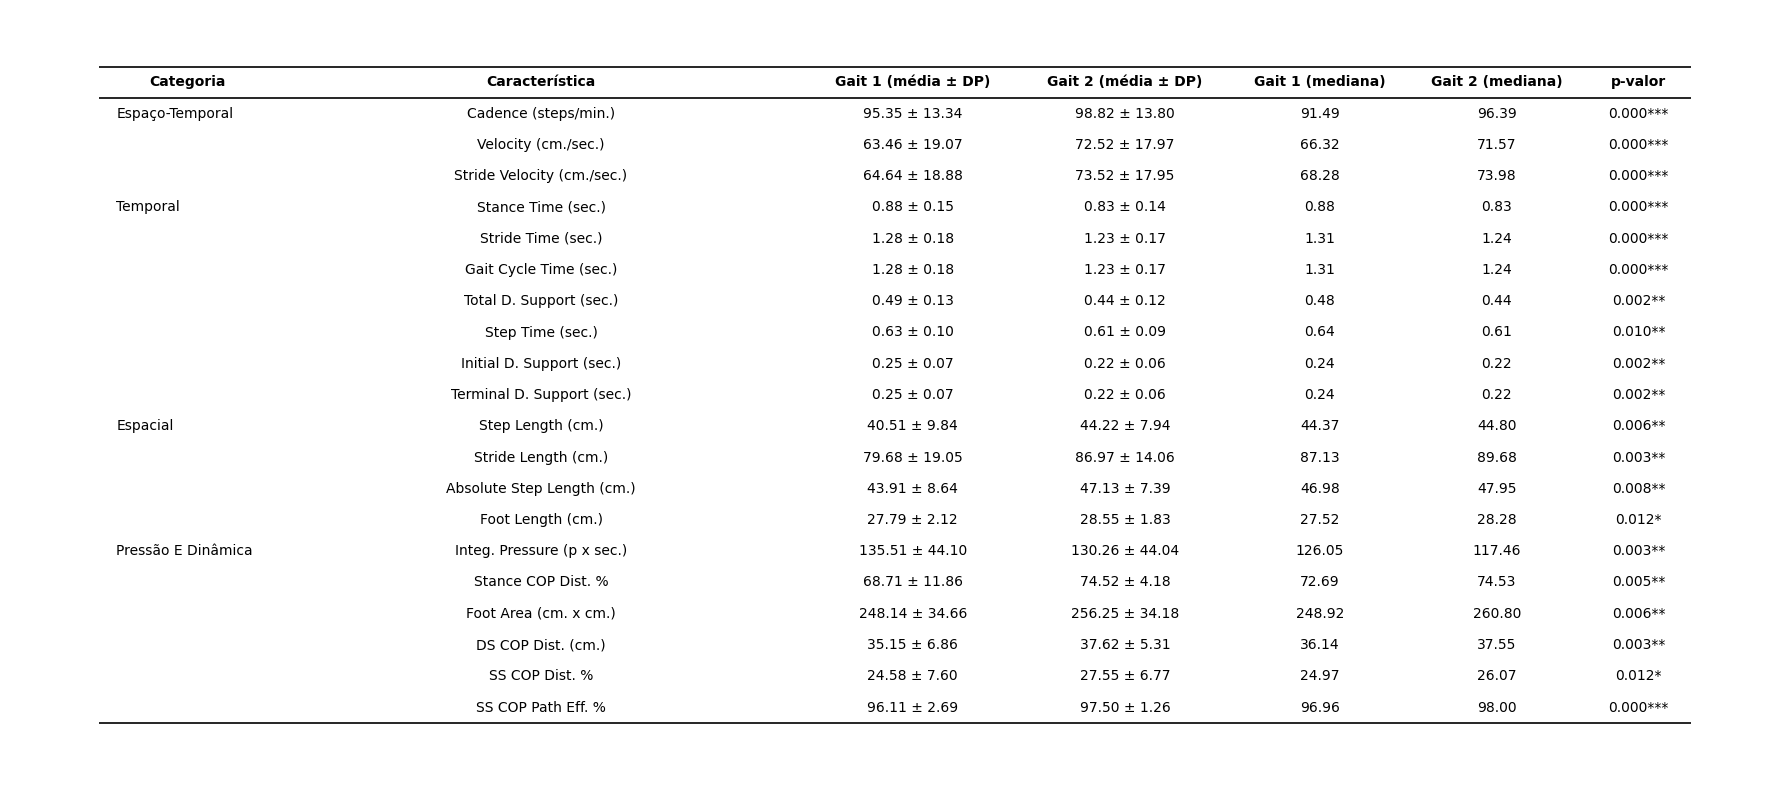

Portuguese table saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/gait_table_portuguese.png


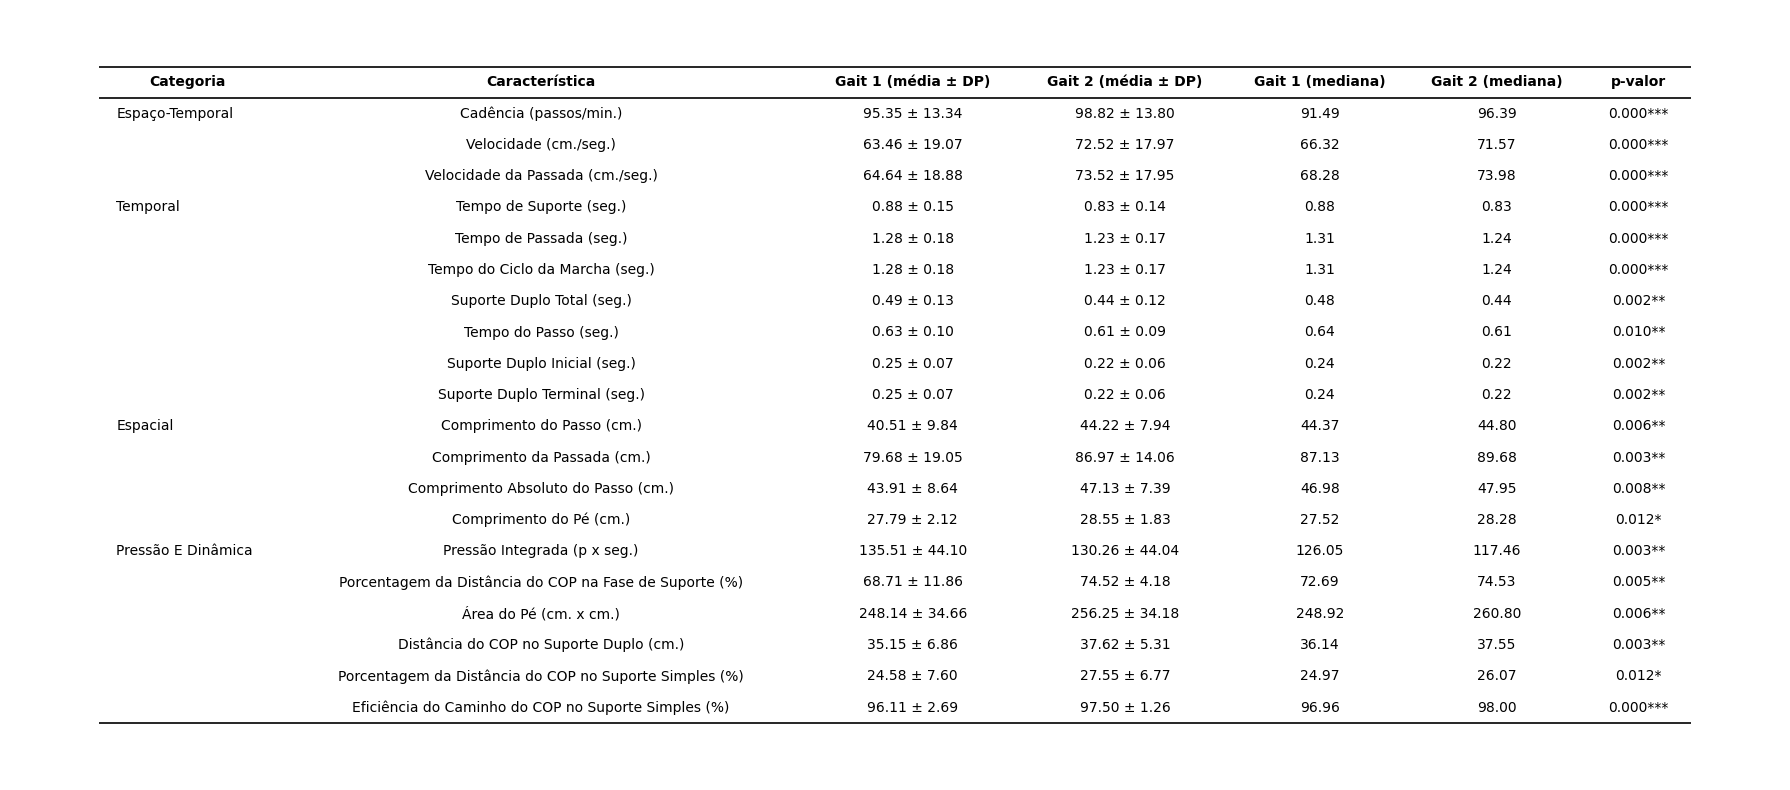

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os # Import os for path manipulation
import numpy as np # Import numpy for np.nan

# Function to get significance stars based on p-value (re-using from 7obILcwgJ17Z)
def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

# Define the output directory for saving plots
output_table_dir = os.path.join(pasta_dados, 'Análise')
os.makedirs(output_table_dir, exist_ok=True)

# --- START: First table generation (English characteristics - as previously generated in f9184b0b and then modified) ---
# df_gait_table is already available from cell f9184b0b
# Apply the category name modification as was done previously in this cell
df_gait_table_display_english = df_gait_table.copy()

# Check if DataFrame is empty before proceeding
if df_gait_table_display_english.empty:
    print("Skipping English table generation: No significant characteristics found to display.")
else:
    df_gait_table_display_english['Categoria'] = df_gait_table_display_english['Categoria'].replace('Pressão e Dinâmica de Marcha', 'Pressão e Dinâmica')

    # Define column widths for better readability
    column_widths = [0.10, 0.30, 0.12, 0.12, 0.10, 0.10, 0.06] # Adjusted widths

    # Create the figure and axes for the English table
    fig_english, ax_english = plt.subplots(figsize=(18, df_gait_table_display_english.shape[0] * 0.4)) # Increased figure width
    ax_english.axis('off') # Hide axes

    tabela_english = ax_english.table(
        cellText=df_gait_table_display_english.values,
        colLabels=df_gait_table_display_english.columns,
        cellLoc='center',
        loc='center',
        colWidths=column_widths # Apply custom column widths
    )

    tabela_english.auto_set_font_size(False)
    tabela_english.set_fontsize(10)
    tabela_english.scale(1.0, 1.5) # Adjusted overall scale slightly

    categoria_col_idx_english = df_gait_table_display_english.columns.get_loc('Categoria')

    # --- Apply styling for "three lines" table ---
    # Remove all borders first
    for (row, col), cell in tabela_english.get_celld().items():
        cell.visible_edges = ''
        cell.set_linewidth(0)

    # Header row styling
    for col in range(len(df_gait_table_display_english.columns)):
        tabela_english[(0, col)].visible_edges = 'TB' # Top and Bottom borders for header
        tabela_english[(0, col)].set_linewidth(1.2)
        tabela_english[(0, col)].set_text_props(ha='center', weight='bold', color='black') # Header text
        tabela_english[(0, col)].set_facecolor('white') # Header background

    # Set content rows styling and add bottom line for the entire table
    ultima_linha_english = len(df_gait_table_display_english)
    for (row_idx_mpl, col_idx_mpl), cell in tabela_english.get_celld().items():
        if row_idx_mpl > 0: # Only for data rows, not header
            if col_idx_mpl == categoria_col_idx_english:
                cell.set_text_props(ha='left')
            else:
                cell.set_text_props(ha='center')

            # Add bottom line only to the last row of the table
            if row_idx_mpl == ultima_linha_english:
                cell.visible_edges = 'B'
                cell.set_linewidth(1.2)

    plt.tight_layout()

    # Save the English table as a high-resolution PNG
    english_table_path = os.path.join(output_table_dir, 'gait_table_english.png')
    plt.savefig(english_table_path, dpi=300, bbox_inches='tight')
    print(f"English table saved to: {english_table_path}")

    plt.show()
# --- END: First table generation ---

# --- START: Second table generation (Portuguese characteristics) ---

# Data for the translation mapping
translation_map_data = {
    'Característica (Inglês)': [
        'Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Step Length (cm.)',
        'Stride Length (cm.)', 'Stride Velocity (cm./sec.)', 'Stride Width (cm.)',
        'Stance Time (sec.)', 'Stride Time (sec.)', 'Swing %',
        'Swing Time (sec.)', 'Gait Cycle Time (sec.)', 'Integ. Pressure (p x sec.)',
        'Single Support (sec.)', 'Total D. Support (sec.)', 'Ambulation Time (sec.)',
        'Walk Ratio (cm./(steps/min.))', 'Mean eGVI', 'Foot Angle (degrees)',
        'Toe In/Out Angle (degrees)', 'Stance COP Dist. (cm.)', 'Stance COP Dist. %',
        'CISP Time (sec.)', 'CISP AP (%)', 'CISP ML (%)',
        'Foot Toe X Location (cm.)', 'Foot Toe Y Location (cm.)', 'Foot Center X Location (cm.)',
        'Foot Center Y Location (cm.)', 'First Contact (sec.)', 'Last Contact (sec.)',
        'Foot Length (cm.)', 'Foot Area (cm. x cm.)', 'Foot Heel X Location (cm.)',
        'Foot Heel Y Location (cm.)', 'Absolute Step Length (cm.)', 'Foot Length %',
        'Foot Width (cm.)', 'Step Ratio (cm. x min.)', 'Step Time (sec.)',
        'DOP (degrees)', 'Initial D. Support (sec.)', 'Initial D. Support %',
        'Terminal D. Support (sec.)', 'Terminal D. Support %', 'SS COP Dist. (cm.)',
        'DS COP Dist. (cm.)', 'SS COP Dist. %', 'Stance COP Path Eff. %',
        'SS COP Path Eff. %', 'DS COP Path Eff.%', 'Left eGVI',
        'Right eGVI', 'Step Length Left (cm.)'
    ],
    'Tradução (Português)': [
        'Cadência (passos/min.)', 'Velocidade (cm./seg.)', 'Comprimento do Passo (cm.)',
        'Comprimento da Passada (cm.)', 'Velocidade da Passada (cm./seg.)', 'Largura da Passada (cm.)',
        'Tempo de Suporte (seg.)', 'Tempo de Passada (seg.)', 'Porcentagem da Fase de Balanço (%)',
        'Tempo da Fase de Balanço (seg.)', 'Tempo do Ciclo da Marcha (seg.)', 'Pressão Integrada (p x seg.)',
        'Suporte Simples (seg.)', 'Suporte Duplo Total (seg.)', 'Tempo de Ambiência (seg.)',
        'Razão de Caminhada (cm./(passos/min.))', 'eGVI Médio', 'Ângulo do Pé (graus)',
        'Ângulo de Abertura/Fechamento do Pé (graus)', 'Distância do COP na Fase de Suporte (cm.)', 'Porcentagem da Distância do COP na Fase de Suporte (%)',
        'Tempo CISP (seg.)', 'CISP AP (%)', 'CISP ML (%)',
        'Localização X da Ponta do Pé (cm.)', 'Localização Y da Ponta do Pé (cm.)', 'Localização X do Centro do Pé (cm.)',
        'Localização Y do Centro do Pé (cm.)', 'Primeiro Contato (seg.)', 'Último Contato (seg.)',
        'Comprimento do Pé (cm.)', 'Área do Pé (cm. x cm.)', 'Localização X do Calcanhar do Pé (cm.)',
        'Localização Y do Calcanhar do Pé (cm.)', 'Comprimento Absoluto do Passo (cm.)', 'Porcentagem do Comprimento do Pé (%)',
        'Largura do Pé (cm.)', 'Razão do Passo (cm. x min.)', 'Tempo do Passo (seg.)',
        'DOP (graus)', 'Suporte Duplo Inicial (seg.)', 'Porcentagem do Suporte Duplo Inicial (%)',
        'Suporte Duplo Terminal (seg.)', 'Porcentagem do Suporte Duplo Terminal (%)', 'Distância do COP no Suporte Simples (cm.)',
        'Distância do COP no Suporte Duplo (cm.)', 'Porcentagem da Distância do COP no Suporte Simples (%)', 'Eficiência do Caminho do COP na Fase de Suporte (%)',
        'Eficiência do Caminho do COP no Suporte Simples (%)', 'Eficiência do Caminho do COP no Suporte Duplo (%)', 'eGVI Esquerdo',
        'eGVI Direito', 'Comprimento do Passo Esquerdo (cm.)'
    ]
}

# Create English to Portuguese mapping
eng_to_port_map = dict(zip(translation_map_data['Característica (Inglês)'], translation_map_data['Tradução (Português)']))

table_rows_portuguese = []

# Fallback for empty gait_table_data in case no significant characteristics were found
if not gait_table_data:
    print("Skipping Portuguese table generation: 'gait_table_data' is empty, likely due to no significant characteristics.")
else:
    for category_name_raw, characteristics in gait_table_data.items():
        category_name = category_name_raw.replace('_', ' ').title()
        # Adjust specific category names to match user's request exactly
        if category_name == "Espaco Temporal":
            category_name = "Espaço-Temporal"
        elif category_name == "Temporais":
            category_name = "Temporal"
        elif category_name == "Espaciais":
            category_name = "Espacial"
        elif category_name == "Pressao E Dinamica De Marcha":
            category_name = "Pressão e Dinâmica" # Corrected

        for char_name_english, values in characteristics.items():
            char_name_portuguese = eng_to_port_map.get(char_name_english, char_name_english) # Get translation or keep English

            # Get p-value and add significance stars (p_values_dict uses English names)
            p_value_float = p_values_dict.get(char_name_english, np.nan)
            stars = get_significance_stars(p_value_float)
            formatted_p_value = f"{p_value_float:.3f}{stars}" if not pd.isna(p_value_float) else "N/A"

            # Retrieve median values from descriptive_stats_by_condition (descriptive_stats_by_condition uses English names)
            median_m1 = descriptive_stats_by_condition.loc['M1', (char_name_english, '50%')] if (char_name_english, '50%') in descriptive_stats_by_condition.columns else np.nan
            median_m2 = descriptive_stats_by_condition.loc['M2', (char_name_english, '50%')] if (char_name_english, '50%') in descriptive_stats_by_condition.columns else np.nan

            table_rows_portuguese.append({
                'Categoria': category_name,
                'Característica': char_name_portuguese,
                'Gait 1 (média ± DP)': values['Gait 1'],
                'Gait 2 (média ± DP)': values['Gait 2'],
                'Gait 1 (mediana)': f"{median_m1:.2f}" if not pd.isna(median_m1) else "N/A",
                'Gait 2 (mediana)': f"{median_m2:.2f}" if not pd.isna(median_m2) else "N/A",
                'p-valor': formatted_p_value
            })

    # Process table_rows_portuguese to 'merge' category cells visually
    merged_table_rows_portuguese = []
    last_category = None
    for row in table_rows_portuguese:
        current_category = row['Categoria']
        if current_category == last_category:
            row['Categoria'] = '' # Set to empty string for visual merging
        else:
            last_category = current_category
        merged_table_rows_portuguese.append(row)

    # Create the DataFrame from the processed rows
    df_gait_table_portuguese = pd.DataFrame(merged_table_rows_portuguese)

    # Check if DataFrame is empty after processing
    if df_gait_table_portuguese.empty:
        print("Skipping Portuguese table generation: No rows to display in the table.")
    else:
        # Modify the 'Categoria' column in df_gait_table_portuguese
        df_gait_table_portuguese['Categoria'] = df_gait_table_portuguese['Categoria'].replace('Pressão e Dinâmica de Marcha', 'Pressão e Dinâmica')

        # Create the figure and axes for the Portuguese table
        fig_portuguese, ax_portuguese = plt.subplots(figsize=(18, df_gait_table_portuguese.shape[0] * 0.4)) # Increased figure width
        ax_portuguese.axis('off') # Hide axes

        tabela_portuguese = ax_portuguese.table(
            cellText=df_gait_table_portuguese.values,
            colLabels=df_gait_table_portuguese.columns,
            cellLoc='center',
            loc='center',
            colWidths=column_widths # Apply custom column widths
        )

        tabela_portuguese.auto_set_font_size(False)
        tabela_portuguese.set_fontsize(10)
        tabela_portuguese.scale(1.0, 1.5) # Adjusted overall scale slightly

        categoria_col_idx_portuguese = df_gait_table_portuguese.columns.get_loc('Categoria')

        # --- Apply styling for "three lines" table ---
        # Remove all borders first
        for (row, col), cell in tabela_portuguese.get_celld().items():
            cell.visible_edges = ''
            cell.set_linewidth(0)

        # Header row styling
        for col in range(len(df_gait_table_portuguese.columns)):
            tabela_portuguese[(0, col)].visible_edges = 'TB'
            tabela_portuguese[(0, col)].set_linewidth(1.2)
            tabela_portuguese[(0, col)].set_text_props(ha='center', weight='bold', color='black')
            tabela_portuguese[(0, col)].set_facecolor('white')

        # Content rows styling and add bottom line for the entire table
        ultima_linha_portuguese = len(df_gait_table_portuguese)
        for (row_idx_mpl, col_idx_mpl), cell in tabela_portuguese.get_celld().items():
            if row_idx_mpl > 0: # Only for data rows, not header
                if col_idx_mpl == categoria_col_idx_portuguese:
                    cell.set_text_props(ha='left')
                else:
                    cell.set_text_props(ha='center')
                if row_idx_mpl == ultima_linha_portuguese:
                    cell.visible_edges = 'B'
                    cell.set_linewidth(1.2)

        plt.tight_layout()

        # Save the Portuguese table as a high-resolution PNG
        portuguese_table_path = os.path.join(output_table_dir, 'gait_table_portuguese.png')
        plt.savefig(portuguese_table_path, dpi=300, bbox_inches='tight')
        print(f"Portuguese table saved to: {portuguese_table_path}")

        plt.show()
# --- END: Second table generation ---


## Cálculo do Tamanho do Efeito (Cohen's d)

Para quantificar a magnitude das diferenças observadas nas características de marcha significativas entre as condições M1 e M2, calcularemos o **Tamanho do Efeito de Cohen (Cohen's d)**. Este é um método padrão para expressar a diferença entre duas médias em termos de desvio padrão.

### Interpretação do Cohen's d:
*   **0.2**: Pequeno efeito
*   **0.5**: Médio efeito
*   **0.8**: Grande efeito


In [ ]:
import numpy as np
import pandas as pd

# Assuming df_resultados, significant_characteristics_at_05, and p_values_dict are already defined

# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

def cohens_d(data1, data2):
    # Calculate sample means and standard deviations
    mean1, mean2 = np.nanmean(data1), np.nanmean(data2)
    std1, std2 = np.nanstd(data1, ddof=1), np.nanstd(data2, ddof=1) # ddof=1 for sample standard deviation
    n1, n2 = len(data1.dropna()), len(data2.dropna())

    # Calculate pooled standard deviation (for independent samples t-test)
    # Note: For paired samples (Wilcoxon), a slightly different pooled std might be used conceptually,
    # but for effect size interpretation, using the pooled standard deviation of the two groups
    # is common for Cohen's d.
    if (n1 + n2 - 2) > 0: # Avoid division by zero
        pooled_std = np.sqrt(((n1 - 1) * std1**2 + (n2 - 1) * std2**2) / (n1 + n2 - 2))
    else:
        return np.nan # Not enough data to calculate pooled standard deviation

    # Calculate Cohen's d
    if pooled_std > 0:
        d = (mean1 - mean2) / pooled_std
    else:
        d = np.nan # Avoid division by zero if pooled_std is 0
    return d

# Dictionary to store Cohen's d values
cohens_d_values = {}

print("Calculating Cohen's d for significant characteristics (M1 vs M2):")

for caracteristica in significant_characteristics_at_05:
    # Aggregate duplicate entries by taking the mean for each (nome, condicao)
    # This is important if multiple measurements exist per participant per condition
    df_agg = df_m1_m2.groupby(['nome', 'condicao'])[caracteristica].mean().reset_index()

    # Reshape data to get M1 and M2 values side-by-side per participant
    df_pivot = df_agg.pivot(index='nome', columns='condicao', values=caracteristica)

    # Extract M1 and M2 values for the current characteristic
    m1_values = df_pivot['M1'].dropna() if 'M1' in df_pivot.columns else pd.Series([])
    m2_values = df_pivot['M2'].dropna() if 'M2' in df_pivot.columns else pd.Series([])

    # Ensure there's enough data for calculation
    if len(m1_values) >= 2 and len(m2_values) >= 2:
        # Calculate Cohen's d. Note: We are calculating d using M1 - M2.
        d = cohens_d(m1_values, m2_values)
        cohens_d_values[caracteristica] = d
        print(f"- {caracteristica}: Cohen's d = {d:.3f}")
    else:
        cohens_d_values[caracteristica] = np.nan
        print(f"- {caracteristica}: Not enough data to calculate Cohen's d (M1: {len(m1_values)}, M2: {len(m2_values)})")

# Create a DataFrame for better display
df_cohens_d = pd.DataFrame.from_dict(cohens_d_values, orient='index', columns=["Cohen's d"])
df_cohens_d.index.name = 'Characteristic'

print("\nSummary of Cohen's d values for significant characteristics:")
display(df_cohens_d.sort_values(by="Cohen's d", ascending=False))

# Optionally save to CSV
output_cohens_d_path = os.path.join(pasta_dados, 'Análise', 'cohens_d_significant_characteristics.csv')
df_cohens_d.to_csv(output_cohens_d_path)
print(f"Cohen's d values saved to: {output_cohens_d_path}")

Calculating Cohen's d for significant characteristics (M1 vs M2):
- Cadence (steps/min.): Cohen's d = -0.255
- Velocity (cm./sec.): Cohen's d = -0.489
- Step Length (cm.): Cohen's d = -0.415
- Stride Length (cm.): Cohen's d = -0.436
- Stride Velocity (cm./sec.): Cohen's d = -0.482
- Stance Time (sec.): Cohen's d = 0.351
- Stride Time (sec.): Cohen's d = 0.274
- Gait Cycle Time (sec.): Cohen's d = 0.274
- Integ. Pressure (p x sec.): Cohen's d = 0.119
- Total D. Support (sec.): Cohen's d = 0.380
- Stance COP Dist. %: Cohen's d = -0.653
- Foot Length (cm.): Cohen's d = -0.380
- Foot Area (cm. x cm.): Cohen's d = -0.235
- Absolute Step Length (cm.): Cohen's d = -0.400
- Step Time (sec.): Cohen's d = 0.211
- Initial D. Support (sec.): Cohen's d = 0.384
- Terminal D. Support (sec.): Cohen's d = 0.385
- DS COP Dist. (cm.): Cohen's d = -0.404
- SS COP Dist. %: Cohen's d = -0.413
- SS COP Path Eff. %: Cohen's d = -0.663

Summary of Cohen's d values for significant characteristics:


,Cohen's d
Characteristic,
Terminal D. Support (sec.),0.384561
Initial D. Support (sec.),0.383785
Total D. Support (sec.),0.379533
Stance Time (sec.),0.350609
Gait Cycle Time (sec.),0.274024
Stride Time (sec.),0.274024
Step Time (sec.),0.210602
Integ. Pressure (p x sec.),0.119105
Foot Area (cm. x cm.),-0.235374


Cohen's d values saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/cohens_d_significant_characteristics.csv


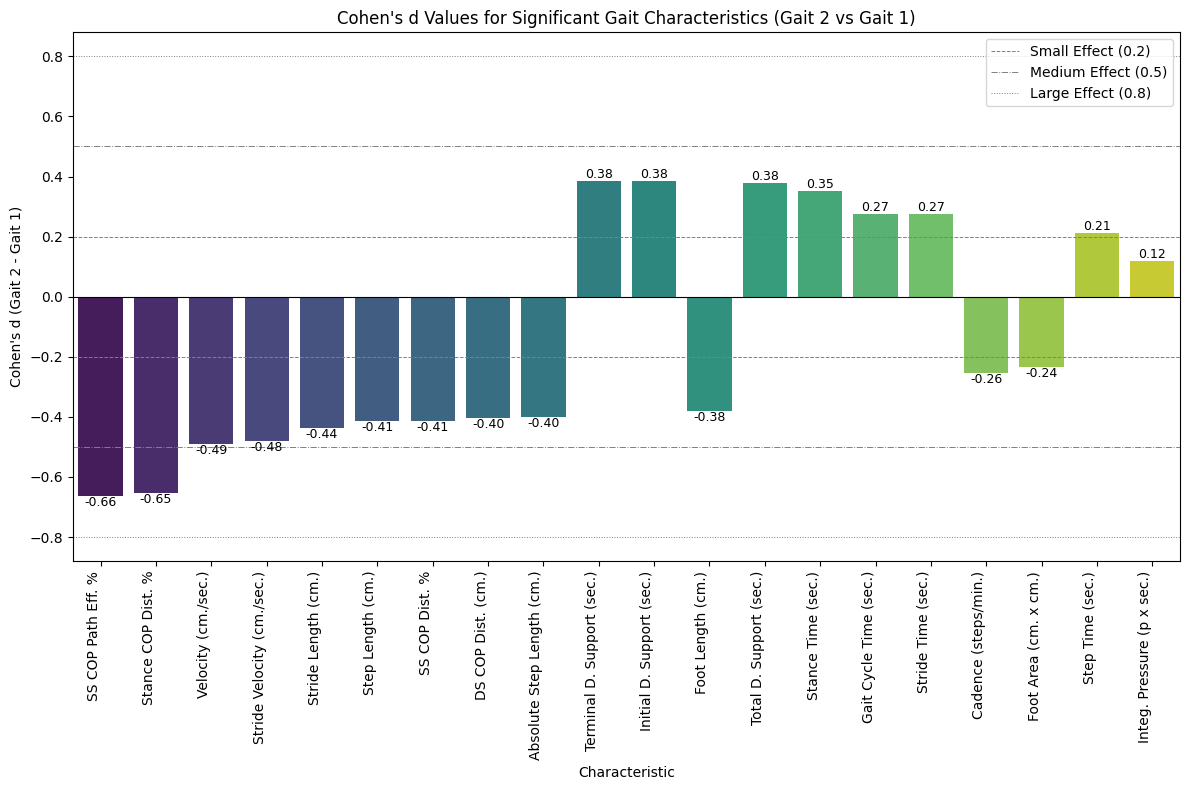

Cohen's d bar plot saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/cohens_d_significant_characteristics_barplot.png


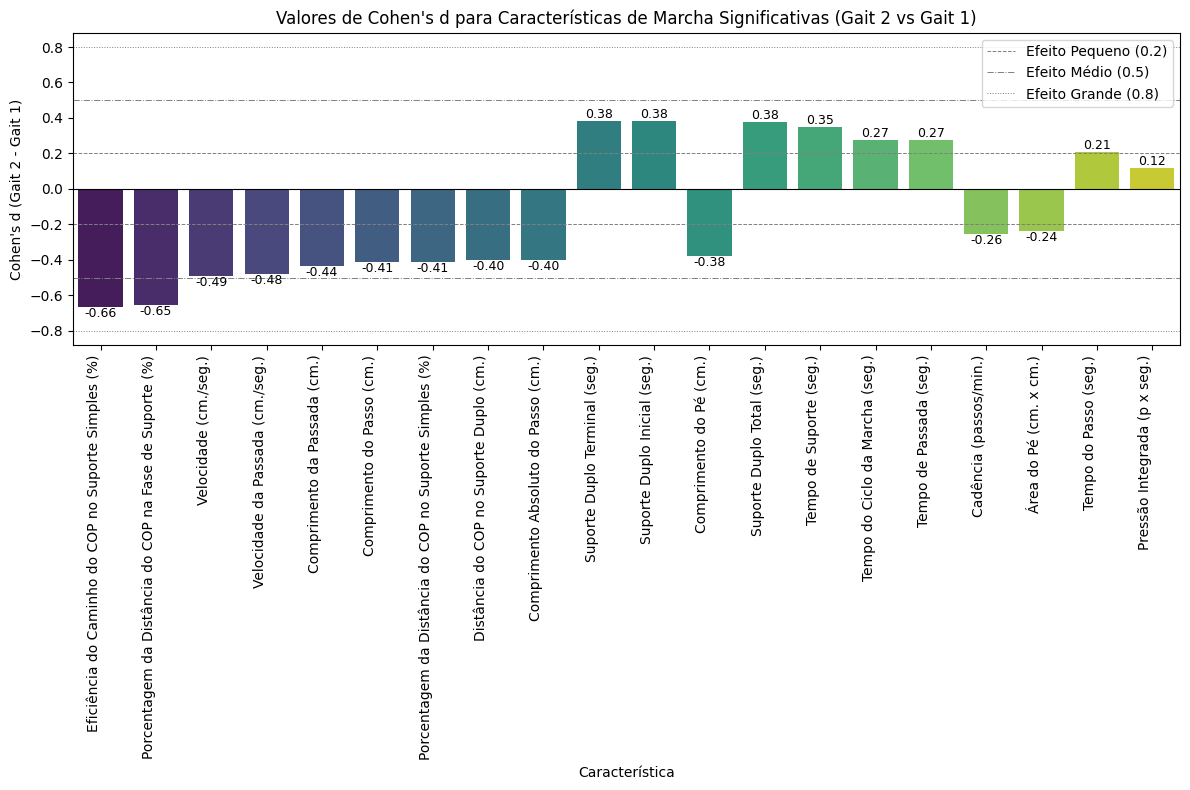

Cohen's d bar plot em português salvo em: /content/drive/MyDrive/doc_mayara/Marcha/Análise/cohens_d_significant_characteristics_barplot_pt.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Sort the Cohen's d values by their absolute magnitude to highlight the most relevant ones
df_cohens_d_sorted = df_cohens_d.reindex(df_cohens_d["Cohen's d"].abs().sort_values(ascending=False).index)

# --- First Plot (Original - English) ---
plt.figure(figsize=(12, 8))
ax = sns.barplot(x=df_cohens_d_sorted.index, y="Cohen's d", data=df_cohens_d_sorted, palette='viridis', hue=df_cohens_d_sorted.index, legend=False)
plt.axhline(0, color='black', linewidth=0.8) # Add a zero line for reference

# Add interpretation lines for Cohen's d magnitudes
plt.axhline(0.2, color='gray', linestyle='--', linewidth=0.7, label='Small Effect (0.2)')
plt.axhline(0.5, color='gray', linestyle='-.', linewidth=0.7, label='Medium Effect (0.5)')
plt.axhline(0.8, color='gray', linestyle=':', linewidth=0.7, label='Large Effect (0.8)')
plt.axhline(-0.2, color='gray', linestyle='--', linewidth=0.7)
plt.axhline(-0.5, color='gray', linestyle='-.', linewidth=0.7)
plt.axhline(-0.8, color='gray', linestyle=':', linewidth=0.7)

# Add Cohen's d values as labels on the bars
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., height,    # Position
                f'{height:.2f}',                               # Label text (formatted to 2 decimal places)
                ha='center', va='bottom' if height > 0 else 'top',  # Horizontal and vertical alignment
                color='black', fontsize=9)

plt.title("Cohen's d Values for Significant Gait Characteristics (Gait 2 vs Gait 1)")
plt.xlabel('Characteristic')
plt.ylabel("Cohen's d (Gait 2 - Gait 1)")
plt.xticks(rotation=90, ha='right')
plt.legend()
plt.tight_layout()

# Save the plot
output_plot_path_cohens_d = os.path.join(pasta_dados, 'Análise', 'cohens_d_significant_characteristics_barplot.png')
plt.savefig(output_plot_path_cohens_d)
plt.show()

print(f"Cohen's d bar plot saved to: {output_plot_path_cohens_d}")

# --- Second Plot (Portuguese Version) ---
# Create a translated index for the plot
translated_characteristics = [eng_to_port_map.get(char, char) for char in df_cohens_d_sorted.index]

plt.figure(figsize=(12, 8))
ax_pt = sns.barplot(x=translated_characteristics, y="Cohen's d", data=df_cohens_d_sorted, palette='viridis', hue=translated_characteristics, legend=False)
plt.axhline(0, color='black', linewidth=0.8) # Adiciona uma linha zero para referência

# Adiciona linhas de interpretação para as magnitudes de Cohen's d
plt.axhline(0.2, color='gray', linestyle='--', linewidth=0.7, label='Efeito Pequeno (0.2)')
plt.axhline(0.5, color='gray', linestyle='-.', linewidth=0.7, label='Efeito Médio (0.5)')
plt.axhline(0.8, color='gray', linestyle=':', linewidth=0.7, label='Efeito Grande (0.8)')
plt.axhline(-0.2, color='gray', linestyle='--', linewidth=0.7)
plt.axhline(-0.5, color='gray', linestyle='-.', linewidth=0.7)
plt.axhline(-0.8, color='gray', linestyle=':', linewidth=0.7)

# Adiciona os valores de Cohen's d como rótulos nas barras
for container in ax_pt.containers:
    for bar in container:
        height = bar.get_height()
        ax_pt.text(bar.get_x() + bar.get_width() / 2., height,    # Posição
                   f'{height:.2f}',                               # Texto do rótulo (formatado para 2 casas decimais)
                   ha='center', va='bottom' if height > 0 else 'top',  # Alinhamento horizontal e vertical
                   color='black', fontsize=9)

plt.title("Valores de Cohen's d para Características de Marcha Significativas (Gait 2 vs Gait 1)")
plt.xlabel('Característica')
plt.ylabel("Cohen's d (Gait 2 - Gait 1)")
plt.xticks(rotation=90, ha='right')
plt.legend()
plt.tight_layout()

# Salva o segundo gráfico
output_plot_path_cohens_d_pt = os.path.join(pasta_dados, 'Análise', 'cohens_d_significant_characteristics_barplot_pt.png')
plt.savefig(output_plot_path_cohens_d_pt)
plt.show()

print(f"Cohen's d bar plot em português salvo em: {output_plot_path_cohens_d_pt}")

In [ ]:
# Define the path to save the significant data table in Google Drive
output_table_path = pasta_dados + 'Análise/significant_data_table.csv'

# Save the df_significant_data DataFrame to a CSV file
df_significant_data.to_csv(output_table_path, index=False) # index=False prevents writing the DataFrame index as a column

print(f"Significant data table saved to: {output_table_path}")

Significant data table saved to: /content/drive/MyDrive/doc_mayara/MarchaAnálise/significant_data_table.csv


In [ ]:
import pandas as pd
import io
import sys

print("P-values for significant characteristics:")

# Capture the output of the print statements
old_stdout = sys.stdout
sys.stdout = captured_output = io.StringIO()

print("\nSignificant at p < 0.05:")
for caracteristica in significant_characteristics_at_05:
    if caracteristica in p_values_dict:
        print(f"- {caracteristica}: {p_values_dict[caracteristica]:.6f}")
    else:
        print(f"- {caracteristica}: P-value not available")

print("\nSignificant at p < 0.01:")
for caracteristica in significant_characteristics_at_01:
    if caracteristica in p_values_dict:
        print(f"- {caracteristica}: {p_values_dict[caracteristica]:.6f}")
    else:
        print(f"- {caracteristica}: P-value not available")

# Restore stdout
sys.stdout = old_stdout

# Get the captured output
output_text = captured_output.getvalue()

# Print the captured output to the notebook
print(output_text)

# Define the path to save the output file in Google Drive
output_file_path = pasta_dados + 'Análise/significant_p_values.txt'

# Save the captured output to a text file
with open(output_file_path, 'w') as f:
    f.write(output_text)

print(f"\nP-values saved to: {output_file_path}")

P-values for significant characteristics:

Significant at p < 0.05:
- Cadence (steps/min.): 0.000144
- Velocity (cm./sec.): 0.000134
- Step Length (cm.): 0.005581
- Stride Length (cm.): 0.003153
- Stride Velocity (cm./sec.): 0.000261
- Stance Time (sec.): 0.000317
- Stride Time (sec.): 0.000099
- Gait Cycle Time (sec.): 0.000099
- Integ. Pressure (p x sec.): 0.003252
- Total D. Support (sec.): 0.001708
- Stance COP Dist. %: 0.004860
- Foot Length (cm.): 0.012079
- Foot Area (cm. x cm.): 0.005581
- Absolute Step Length (cm.): 0.008308
- Step Time (sec.): 0.009983
- Initial D. Support (sec.): 0.001824
- Terminal D. Support (sec.): 0.002200
- DS COP Dist. (cm.): 0.002712
- SS COP Dist. %: 0.012079
- SS COP Path Eff. %: 0.000395

Significant at p < 0.01:
- Cadence (steps/min.): 0.000144
- Velocity (cm./sec.): 0.000134
- Stride Velocity (cm./sec.): 0.000261
- Stance Time (sec.): 0.000317
- Stride Time (sec.): 0.000099
- Gait Cycle Time (sec.): 0.000099
- SS COP Path Eff. %: 0.000395


P-val

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Close any existing plots to clear the matplotlib state
plt.close('all')

# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Melt the DataFrame for easier plotting with seaborn
df_m1_m2_melted = df_m1_m2.melt(id_vars=['nome', 'condicao'], value_vars=significant_characteristics_at_05, var_name='Characteristic', value_name='Value')

# Replace 'M1' with 'Gait 1' and 'M2' with 'Gait 2' in the 'condicao' column
df_m1_m2_melted['condicao'] = df_m1_m2_melted['condicao'].replace({'M1': 'Gait 1', 'M2': 'Gait 2'})

# Directory for saving plots
output_plot_dir = os.path.join(pasta_dados, 'Análise', 'Raincloud_Plots_Categorizados') # Updated directory name
os.makedirs(output_plot_dir, exist_ok=True)

# Function to get significance stars based on p-value
def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

# Define categories of significant gait characteristics
categories = {
    "temporais": [
        'Stance Time (sec.)', 'Stride Time (sec.)',
        'Gait Cycle Time (sec.)', 'Single Support (sec.)', 'Total D. Support (sec.)',
        'Step Time (sec.)', 'Initial D. Support (sec.)', 'Terminal D. Support (sec.)'
    ],
    "espaciais": [
        'Step Length (cm.)', 'Stride Length (cm.)',
        'Absolute Step Length (cm.)', 'Foot Length (cm.)',
        'Foot Width (cm.)', 'Foot Length %'
    ],
    "espaco_temporal": [
        'Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Stride Velocity (cm./sec.)'
    ],
    "pressao_e_dinamica_de_marcha": [
        'Integ. Pressure (p x sec.)', 'Stance COP Dist. (cm.)', 'Stance COP Dist. %',
        'CISP AP (%)', 'Foot Area (cm. x cm.)', 'SS COP Dist. (cm.)',
        'DS COP Dist. (cm.)', 'SS COP Dist. %', 'SS COP Path Eff. %', 'DS COP Path Eff.%'
    ]
}

print("Generating categorized raincloud plots for significant characteristics...")

# Make sure eng_to_port_map is defined, or provide a fallback
if 'eng_to_port_map' not in globals():
    print("WARNING: 'eng_to_port_map' not found. Using English names for plot titles and labels. Define a fallback.")
    # Fallback: create a dummy map if it2 does not exist
    eng_to_port_map = {char: char for char in df_m1_m2.columns if char not in ['nome', 'condicao', 'grupo_randomizado']}

for category_name, characteristics_list in categories.items():
    print(f"\nProcessing category: {category_name.replace('_', ' ').title()}")
    # Filter characteristics that are actually significant
    significant_chars_in_category = [char for char in characteristics_list if char in significant_characteristics_at_05]

    if not significant_chars_in_category:
        print(f"  No significant characteristics found for category '{category_name}'. Skipping.")
        continue

    # Determine grid size for subplots
    num_plots = len(significant_chars_in_category)
    if num_plots == 0:
        continue

    n_cols = 2 # Changed from 3 to 2 for requested layout
    n_rows = (num_plots + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 8, n_rows * 6), dpi=300) # High resolution, adjusted figsize
    axes = np.array(axes).flatten() # Flatten for easy iteration

    for i, caracteristica in enumerate(significant_chars_in_category):
        ax = axes[i]

        # Filter data for the current characteristic
        data_for_plot = df_m1_m2_melted[df_m1_m2_melted['Characteristic'] == caracteristica]
        data_for_plot_clean = data_for_plot.dropna(subset=['Value'])

        if data_for_plot_clean.empty or data_for_plot_clean['condicao'].nunique() < 2:
            ax.set_title(f'{caracteristica}\n(Sem Dados Válidos)', fontsize=10)
            ax.text(0.5, 0.5, 'Sem dados válidos para plotar', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray', fontsize=8)
            ax.set_xticks([])
            ax.set_yticks([])
            continue

        # --- Raincloud Plot elements ---
        # 1. KDE Plot (Density) - quantitative on x-axis, categorical on y-axis
        sns.kdeplot(
            data=data_for_plot_clean,
            x='Value',
            hue='condicao',
            fill=True,
            alpha=0.4,
            linewidth=0,
            palette='viridis',
            legend=False,
            ax=ax
        )

        # 2. Boxplot - categorical on y-axis, quantitative on x-axis
        sns.boxplot(
            data=data_for_plot_clean,
            y='condicao',
            x='Value',
            hue='condicao', # Keep hue for proper coloring if using a palette with hue
            width=0.3,
            boxprops={'zorder': 2, 'facecolor': 'white', 'edgecolor': 'black'},
            medianprops={'color': 'red'},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            flierprops={'marker': 'o', 'markerfacecolor': 'gray', 'markeredgecolor': 'gray'},
            palette='viridis',
            showfliers=False,
            linewidth=1.0,
            ax=ax
        )

        # 3. Stripplot (individual points) - categorical on y-axis, quantitative on x-axis
        sns.stripplot(
            data=data_for_plot_clean,
            y='condicao',
            x='Value',
            jitter=0.2,
            size=3,
            color='black',
            alpha=0.6,
            ax=ax
        )
        # --- End Raincloud Plot elements ---

        # Add p-value and significance stars to the title
        p_val = p_values_dict.get(caracteristica)
        stars = get_significance_stars(p_val)
        title_suffix = f' (p={p_val:.3f}{stars})' if p_val is not None else ''

        # Translate characteristic name for the plot title and labels
        caracteristica_portugues = eng_to_port_map.get(caracteristica, caracteristica)

        ax.set_title(f'{caracteristica_portugues}{title_suffix}', fontsize=12)
        ax.set_xlabel('Valor', fontsize=10) # X-axis is now 'Value'
        ax.set_ylabel('Condição', fontsize=10) # Y-axis is now 'Condição'
        ax.tick_params(axis='x', labelsize=9)
        ax.tick_params(axis='y', labelsize=9)
        ax.grid(True, linestyle='--', alpha=0.7)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
    fig.suptitle(f'Raincloud Plots de Características Significativas: Categoria {category_name.replace("_", " ").title()}', fontsize=16)

    # Sanitize category name for filename
    safe_category_name = category_name.replace(' ', '_')
    plot_filename = os.path.join(output_plot_dir, f'raincloud_plots_significant_caracteristicas_{safe_category_name}.png')
    plt.savefig(plot_filename, dpi=300)
    plt.close(fig) # Close the figure to free memory
    print(f"  Saved: {plot_filename}")

print("\nFinished generating all categorized raincloud plots.")

Generating categorized raincloud plots for significant characteristics...

Processing category: Temporais
  Saved: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Raincloud_Plots_Categorizados/raincloud_plots_significant_caracteristicas_temporais.png

Processing category: Espaciais
  Saved: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Raincloud_Plots_Categorizados/raincloud_plots_significant_caracteristicas_espaciais.png

Processing category: Espaco Temporal
  Saved: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Raincloud_Plots_Categorizados/raincloud_plots_significant_caracteristicas_espaco_temporal.png

Processing category: Pressao E Dinamica De Marcha
  Saved: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Raincloud_Plots_Categorizados/raincloud_plots_significant_caracteristicas_pressao_e_dinamica_de_marcha.png

Finished generating all categorized raincloud plots.


## Distribuição das Características com Maior Tamanho de Efeito (Cohen's d)

Vamos visualizar a distribuição das características que apresentaram os maiores tamanhos de efeito (Cohen's d) absolutos entre as condições Gait 1 e Gait 2, usando box plots com swarm overlays para cada uma.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Get the top N characteristics with the largest absolute Cohen's d values
num_top_chars = 7 # You can adjust this number
top_effect_characteristics = df_cohens_d_sorted.head(num_top_chars).index.tolist()

print(f"Características com os {num_top_chars} maiores tamanhos de efeito (Cohen's d):\n{top_effect_characteristics}")

# Filter df_resultados for M1 and M2 conditions
df_m1_m2 = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Melt the DataFrame for easier plotting with seaborn, using only the top effect characteristics
df_top_effect_melted = df_m1_m2.melt(id_vars=['nome', 'condicao'],
                                       value_vars=top_effect_characteristics,
                                       var_name='Characteristic',
                                       value_name='Value')

# Replace 'M1' with 'Gait 1' and 'M2' with 'Gait 2' in the 'condicao' column
df_top_effect_melted['condicao'] = df_top_effect_melted['condicao'].replace({'M1': 'Gait 1', 'M2': 'Gait 2'})

# Directory for saving plots
output_plot_dir_top_effects = os.path.join(pasta_dados, 'Análise', 'Top_Effect_Distributions')
os.makedirs(output_plot_dir_top_effects, exist_ok=True)

# Function to get significance stars based on p-value (re-used from 7obILcwgJ17Z)
def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

print("\nGerando box plots com swarm overlay para as características com maior tamanho de efeito...")

# Determine grid size for subplots
num_plots = len(top_effect_characteristics)
if num_plots == 0:
    print("Nenhuma característica com alto tamanho de efeito para plotar.")
else:
    n_cols = min(num_plots, 3) # Max 3 columns
    n_rows = (num_plots + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 7, n_rows * 6), dpi=300) # High resolution
    axes = np.array(axes).flatten() # Flatten for easy iteration

    for i, caracteristica_eng in enumerate(top_effect_characteristics):
        ax = axes[i]

        # Filter data for the current characteristic
        data_for_plot = df_top_effect_melted[df_top_effect_melted['Characteristic'] == caracteristica_eng]
        data_for_plot_clean = data_for_plot.dropna(subset=['Value'])

        if data_for_plot_clean.empty or data_for_plot_clean['condicao'].nunique() < 2:
            ax.set_title(f'{eng_to_port_map.get(caracteristica_eng, caracteristica_eng)}\n(Sem Dados Válidos)', fontsize=10)
            ax.text(0.5, 0.5, 'Sem dados válidos para plotar', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray', fontsize=8)
            ax.set_xticks([])
            ax.set_yticks([])
            continue

        # Plot Boxplot
        sns.boxplot(x='condicao', y='Value', data=data_for_plot_clean, ax=ax, palette='light:orange', hue='condicao', legend=False)

        # Overlay Swarmplot
        sns.swarmplot(x='condicao', y='Value', data=data_for_plot_clean, ax=ax, color='black', size=3, alpha=0.6, dodge=True)

        # Get Cohen's d value
        cohens_d_val = df_cohens_d.loc[caracteristica_eng, "Cohen's d"]
        formatted_cohens_d = f"Cohen's d = {cohens_d_val:.2f}"

        # Translate characteristic name for title
        caracteristica_port = eng_to_port_map.get(caracteristica_eng, caracteristica_eng)

        ax.set_title(f'{caracteristica_port}\n({formatted_cohens_d})', fontsize=12)
        ax.set_xlabel('Condição', fontsize=10)
        ax.set_ylabel('Valor', fontsize=10)
        ax.tick_params(axis='x', labelsize=9)
        ax.tick_params(axis='y', labelsize=9)
        ax.grid(True, linestyle='--', alpha=0.7)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
    fig.suptitle(f'Distribuição das {num_top_chars} Características com Maior Efeito (Gait 1 vs Gait 2)', fontsize=16)

    plot_filename = os.path.join(output_plot_dir_top_effects, f'top_{num_top_chars}_effect_characteristics_distributions.png')
    plt.savefig(plot_filename, dpi=300)
    plt.close(fig) # Close the figure to free memory
    print(f"  Salvo: {plot_filename}")

print("\nConcluída a geração dos box plots para as características com maior tamanho de efeito.")

Características com os 7 maiores tamanhos de efeito (Cohen's d):
['SS COP Path Eff. %', 'Stance COP Dist. %', 'Velocity (cm./sec.)', 'Stride Velocity (cm./sec.)', 'Stride Length (cm.)', 'Step Length (cm.)', 'SS COP Dist. %']

Gerando box plots com swarm overlay para as características com maior tamanho de efeito...
  Salvo: /content/drive/MyDrive/doc_mayara/Marcha/Análise/Top_Effect_Distributions/top_7_effect_characteristics_distributions.png

Concluída a geração dos box plots para as características com maior tamanho de efeito.


**Reasoning**:
Print the significant characteristics and their p-values for both the 0.05 and 0.01 significance levels as requested by the subtask.



In [ ]:
import io
import sys

# Capture the output of the print statements
old_stdout = sys.stdout
sys.stdout = captured_output = io.StringIO()

print("Significant characteristics and their p-values:")

print("\nSignificant at p < 0.05:")
for caracteristica in significant_characteristics_at_05:
    if caracteristica in p_values_dict:
        print(f"- {caracteristica}: {p_values_dict[caracteristica]:.6f}")
    else:
        print(f"- {caracteristica}: P-value not available")

print("\nSignificant at p < 0.01:")
for caracteristica in significant_characteristics_at_01:
    if caracteristica in p_values_dict:
        print(f"- {caracteristica}: {p_values_dict[caracteristica]:.6f}")
    else:
        print(f"- {caracteristica}: P-value not available")

# Restore stdout
sys.stdout = old_stdout

# Get the captured output
output_text = captured_output.getvalue()

# Print the captured output to the notebook
print(output_text)

Significant characteristics and their p-values:

Significant at p < 0.05:
- Cadence (steps/min.): 0.000144
- Velocity (cm./sec.): 0.000134
- Step Length (cm.): 0.005581
- Stride Length (cm.): 0.003153
- Stride Velocity (cm./sec.): 0.000261
- Stance Time (sec.): 0.000317
- Stride Time (sec.): 0.000099
- Gait Cycle Time (sec.): 0.000099
- Integ. Pressure (p x sec.): 0.003252
- Total D. Support (sec.): 0.001708
- Stance COP Dist. %: 0.004860
- Foot Length (cm.): 0.012079
- Foot Area (cm. x cm.): 0.005581
- Absolute Step Length (cm.): 0.008308
- Step Time (sec.): 0.009983
- Initial D. Support (sec.): 0.001824
- Terminal D. Support (sec.): 0.002200
- DS COP Dist. (cm.): 0.002712
- SS COP Dist. %: 0.012079
- SS COP Path Eff. %: 0.000395

Significant at p < 0.01:
- Cadence (steps/min.): 0.000144
- Velocity (cm./sec.): 0.000134
- Stride Velocity (cm./sec.): 0.000261
- Stance Time (sec.): 0.000317
- Stride Time (sec.): 0.000099
- Gait Cycle Time (sec.): 0.000099
- SS COP Path Eff. %: 0.000395




# Estatísticas descritivas (média, desvio padrão, etc.) para as características significativas nas condições 'Gait1' e 'Gait2'.


**Reasoning**:
Display the descriptive statistics for the significant characteristics for both M1 and M2 conditions, which have been previously calculated and stored in `descriptive_stats_by_condition`.



In [ ]:
# Select only the columns related to the significant characteristics
descriptive_stats_significant = descriptive_stats_by_condition[significant_characteristics_at_05]

# Display the resulting table
display(descriptive_stats_significant)

Cadence (steps/min.)                                                \
                        count     mean        std     min       25%     50%   
condicao                                                                      
M1                       20.0  95.3488  13.343636  72.690  87.97575  91.489   
M2                       20.0  98.8167  13.803969  73.485  91.61025  96.386   

                             Velocity (cm./sec.)            ...  \
                75%      max               count      mean  ...   
condicao                                                    ...   
M1        108.99775  120.884                20.0  63.45580  ...   
M2        111.63475  122.611                20.0  72.51995  ...   

         SS COP Dist. %         SS COP Path Eff. %                      \
                    75%     max              count      mean       std   
condicao                                                                 
M1             30.40950  37.150               20.0  96.10725  2.685746   
M2             33.47325  37.174               20.0  97.49815  1.259742   

                                                       
             min       25%      50%       75%     max  
condicao                                               
M1        87.980  95.09075  96.9635  97.86775  99.064  
M2        94.241  97.28400  97.9990  98.18200  98.907  

[2 rows x 160 columns]

Exibindo o gráfico de barras dos valores de Cohen's d: /content/drive/MyDrive/doc_mayara/Marcha/Análise/cohens_d_significant_characteristics_barplot.png


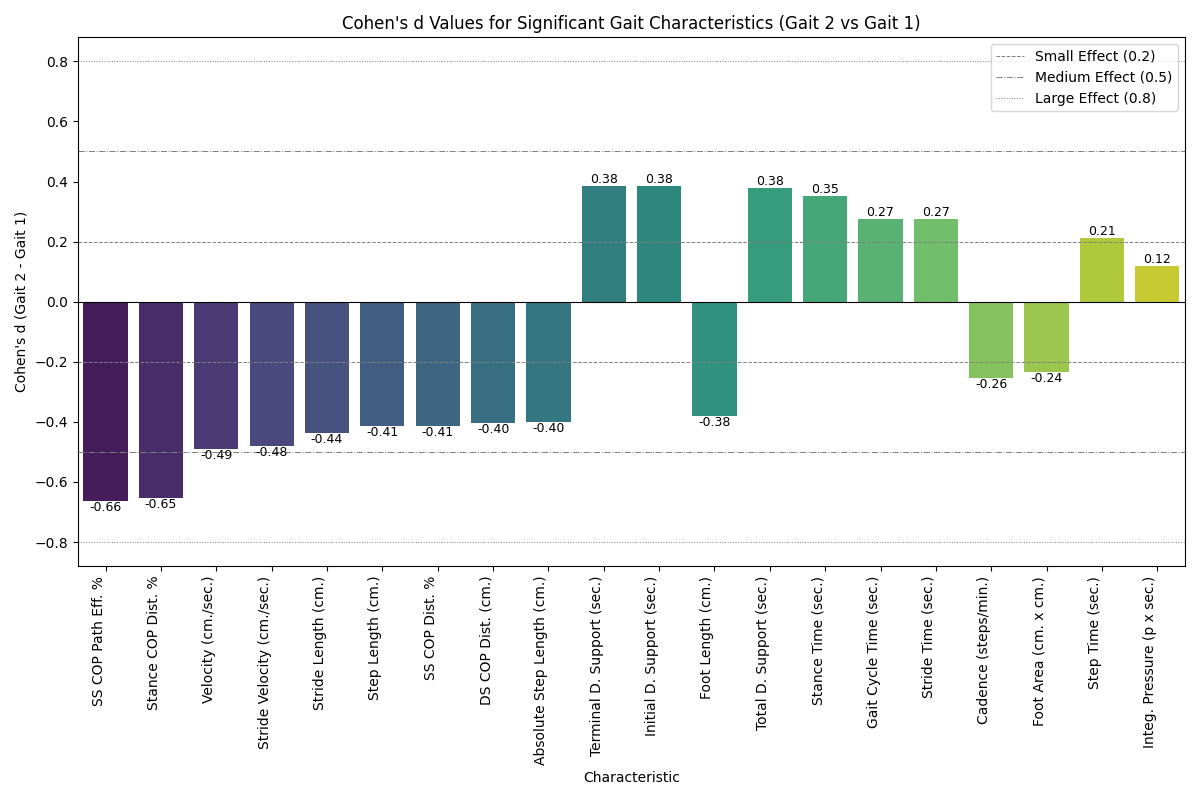

In [ ]:
from IPython.display import Image, display
import os

# The filename for the Cohen's d bar plot generated in cell 12df880d
output_plot_path_cohens_d = os.path.join(pasta_dados, 'Análise', 'cohens_d_significant_characteristics_barplot.png')

# Display the image directly
print(f"Exibindo o gráfico de barras dos valores de Cohen's d: {output_plot_path_cohens_d}")
display(Image(filename=output_plot_path_cohens_d))

# Teste estatísticos e **Box** Plots com Swarm Overlay para Características Significativas (R1 vs R2 em Gait 3)


In [ ]:
import scipy.stats as stats
import pandas as pd
import numpy as np
import os

# Filter df_resultados for M3 condition
df_m3 = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Separate into R1 and R2 groups
df_r1_m3 = df_m3[df_m3['grupo_randomizado'] == 'R1'].copy()
df_r2_m3 = df_m3[df_m3['grupo_randomizado'] == 'R2'].copy()

# Dictionaries to store results
normality_p_values_r1_m3 = {}
normality_p_values_r2_m3 = {}
chosen_test_r1_r2_m3 = {}
p_values_r1_r2_m3_final = {}
significant_characteristics_r1_r2_m3_05_independent = []
significant_characteristics_r1_r2_m3_01_independent = []

print("Performing normality tests and then the appropriate independent statistical test (R1 vs R2 in Gait 3):")

# Use only the 20 characteristics found significant between M1 and M2 (after FDR correction)
# The variable `significant_characteristics_fdr_05` is available from a previous cell.
# Original line: if 'significant_characteristics_fdr_05' in globals() and significant_characteristics_fdr_05:
# User requested to undo the comparison only on 20 characteristics, so reverting to all characteristics.
characteristics_to_compare_r1_r2_m3 = caract_marcha
print("Reverting to use all gait characteristics for R1 vs R2 comparison as requested.")

for caracteristica in characteristics_to_compare_r1_r2_m3:
    # Get the data for the current characteristic for R1 and R2 in M3
    data_r1 = pd.to_numeric(df_r1_m3[caracteristica], errors='coerce').dropna()
    data_r2 = pd.to_numeric(df_r2_m3[caracteristica], errors='coerce').dropna()

    print(f"\nProcessing: {caracteristica}")

    # Ensure there's enough data for both groups to perform tests
    if len(data_r1) > 1 and len(data_r2) > 1:
        try:
            # --- Perform Normality Tests (Shapiro-Wilk) ---
            shapiro_r1_stat, shapiro_r1_p = stats.shapiro(data_r1)
            shapiro_r2_stat, shapiro_r2_p = stats.shapiro(data_r2)

            normality_p_values_r1_m3[caracteristica] = shapiro_r1_p
            normality_p_values_r2_m3[caracteristica] = shapiro_r2_p

            is_r1_normal = shapiro_r1_p > 0.05
            is_r2_normal = shapiro_r2_p > 0.05

            print(f"  R1 Normality (Shapiro-Wilk p): {shapiro_r1_p:.3f} (Normal: {is_r1_normal})")
            print(f"  R2 Normality (Shapiro-Wilk p): {shapiro_r2_p:.3f} (Normal: {is_r2_normal})")

            # --- Decide and Perform Appropriate Statistical Test ---
            p_value = np.nan
            if is_r1_normal and is_r2_normal:
                # Use independent t-test (Welch's t-test for unequal variances is generally safer)
                ttest_result = stats.ttest_ind(data_r1, data_r2, equal_var=False, nan_policy='omit')
                p_value = ttest_result.pvalue
                chosen_test_r1_r2_m3[caracteristica] = "Welch's t-test (independent samples)"
                print(f"  Both groups normally distributed. Using Welch's t-test.")
            else:
                # Use Mann-Whitney U test (non-parametric alternative for independent samples)
                mannwhitneyu_result = stats.mannwhitneyu(data_r1, data_r2, alternative='two-sided')
                p_value = mannwhitneyu_result.pvalue
                chosen_test_r1_r2_m3[caracteristica] = "Mann-Whitney U test"
                print(f"  One or both groups not normally distributed. Using Mann-Whitney U test.")

            p_values_r1_r2_m3_final[caracteristica] = p_value
            print(f"  Result: p-value = {p_value:.6f}")

            # Identify significant characteristics
            if p_value < 0.05:
                significant_characteristics_r1_r2_m3_05_independent.append(caracteristica)
            if p_value < 0.01:
                significant_characteristics_r1_r2_m3_01_independent.append(caracteristica)

        except Exception as e:
            print(f"  Error during normality or statistical test for {caracteristica}: {e}")
            normality_p_values_r1_m3[caracteristica] = np.nan
            normality_p_values_r2_m3[caracteristica] = np.nan
            chosen_test_r1_r2_m3[caracteristica] = "Error"
            p_values_r1_r2_m3_final[caracteristica] = np.nan
    else:
        print(f"  Skipping {caracteristica}: Not enough data in both R1 ({len(data_r1)}) and R2 ({len(data_r2)}) for Gait 3 condition.")
        normality_p_values_r1_m3[caracteristica] = np.nan
        normality_p_values_r2_m3[caracteristica] = np.nan
        chosen_test_r1_r2_m3[caracteristica] = "Not enough data"
        p_values_r1_r2_m3_final[caracteristica] = np.nan

# --- Summary Table of Results ---
print("\n--- Summary of Statistical Tests for Gait 3 (R1 vs R2) ---")
summary_df_r1_r2_m3 = pd.DataFrame({
    'Shapiro-Wilk p-value (R1)': pd.Series(normality_p_values_r1_m3),
    'Shapiro-Wilk p-value (R2)': pd.Series(normality_p_values_r2_m3),
    'Chosen Statistical Test': pd.Series(chosen_test_r1_r2_m3),
    'Test p-value': pd.Series(p_values_r1_r2_m3_final)
})
summary_df_r1_r2_m3 = summary_df_r1_r2_m3.sort_index()
display(summary_df_r1_r2_m3)

print("\nSignificant Characteristics (p < 0.05):")
if significant_characteristics_r1_r2_m3_05_independent:
    for char in significant_characteristics_r1_r2_m3_05_independent:
        print(f"- {char} (p={p_values_r1_r2_m3_final[char]:.6f})")
else:
    print("No characteristics were significant at p < 0.05.")

print("\nSignificant Characteristics (p < 0.01):")
if significant_characteristics_r1_r2_m3_01_independent:
    for char in significant_characteristics_r1_r2_m3_01_independent:
        print(f"- {char} (p={p_values_r1_r2_m3_final[char]:.6f})")
else:
    print("No characteristics were significant at p < 0.01.")

# Optionally, save this summary to a CSV file
output_dir_analysis = os.path.join(pasta_dados, 'Análise')
os.makedirs(output_dir_analysis, exist_ok=True)
output_summary_path_r1_r2_m3 = os.path.join(output_dir_analysis, 'statistical_test_summary_R1_R2_Gait3.csv')
summary_df_r1_r2_m3.to_csv(output_summary_path_r1_r2_m3)
print(f"\nSummary of statistical tests for R1 vs R2 in Gait 3 saved to: {output_summary_path_r1_r2_m3}")


# --- Apply FDR Correction for Multiple Comparisons (Benjamini-Hochberg) ---
from statsmodels.stats.multitest import multipletests

print("\nApplying FDR (Benjamini-Hochberg) correction to p-values for Gait 3 (R1 vs R2)...")

# Convert the dictionary of p-values to a Pandas Series, dropping NaNs
p_values_r1_r2_m3_series = pd.Series(p_values_r1_r2_m3_final).dropna()

if not p_values_r1_r2_m3_series.empty:
    # Apply Benjamini-Hochberg correction
    reject_fdr, p_values_adjusted_fdr, _, _ = multipletests(p_values_r1_r2_m3_series.values, alpha=0.05, method='fdr_bh')

    # Create a DataFrame to display original and adjusted p-values
    df_adjusted_p_values_r1_r2_m3 = pd.DataFrame({
        'Característica': p_values_r1_r2_m3_series.index,
        'P-valor Original': p_values_r1_r2_m3_series.values,
        'P-valor Ajustado (FDR)': p_values_adjusted_fdr,
        'Rejeitar H0 (FDR, alpha=0.05)': reject_fdr
    })

    # Display the results, sorted by adjusted p-value
    print("\n--- P-valores Ajustados (FDR) para Gait 3 (R1 vs R2) ---")
    display(df_adjusted_p_values_r1_r2_m3.sort_values(by='P-valor Ajustado (FDR)'))

    # Update significant characteristics lists based on adjusted p-values
    significant_characteristics_r1_r2_m3_05_fdr = df_adjusted_p_values_r1_r2_m3[
        df_adjusted_p_values_r1_r2_m3['Rejeitar H0 (FDR, alpha=0.05)'] == True
    ]['Característica'].tolist()

    significant_characteristics_r1_r2_m3_01_fdr = df_adjusted_p_values_r1_r2_m3[
        df_adjusted_p_values_r1_r2_m3['P-valor Ajustado (FDR)'] < 0.01
    ]['Característica'].tolist()

    print(f"\nCaracterísticas Significativas (FDR ajustado p < 0.05): {len(significant_characteristics_r1_r2_m3_05_fdr)} características")
    print(significant_characteristics_r1_r2_m3_05_fdr)

    print(f"\nCaracterísticas Significativas (FDR ajustado p < 0.01): {len(significant_characteristics_r1_r2_m3_01_fdr)} características")
    print(significant_characteristics_r1_r2_m3_01_fdr)

    # Update the summary DataFrame with adjusted p-values
    summary_df_r1_r2_m3['FDR Adjusted p-value'] = df_adjusted_p_values_r1_r2_m3.set_index('Característica')['P-valor Ajustado (FDR)']
    summary_df_r1_r2_m3['FDR Reject H0 (alpha=0.05)'] = df_adjusted_p_values_r1_r2_m3.set_index('Característica')['Rejeitar H0 (FDR, alpha=0.05)']

    # Save updated summary with FDR to CSV
    output_summary_path_r1_r2_m3_fdr = os.path.join(output_dir_analysis, 'statistical_test_summary_R1_R2_Gait3_with_FDR.csv')
    summary_df_r1_r2_m3.to_csv(output_summary_path_r1_r2_m3_fdr)
    print(f"\nSummary of statistical tests for R1 vs R2 in Gait 3 (with FDR) saved to: {output_summary_path_r1_r2_m3_fdr}")

else:
    print("Nenhum p-valor disponível para aplicar a correção FDR.")

# --- Generate Report for Significant Differences (R1 vs R2 in Gait 3) ---
print("\n--- Reporte de Diferenças Estatísticas Significativas (R1 vs R2 em Gait 3) ---")

if not significant_characteristics_r1_r2_m3_05_fdr:
    print("Não foram encontradas características significativas após a correção FDR (p < 0.05).")
else:
    print("As seguintes características foram estatisticamente significativas (FDR ajustado p < 0.05):\n")

    for char in significant_characteristics_r1_r2_m3_05_fdr:
        print(f"Característica: {char}")

        # Get means and std for R1 and R2
        mean_r1 = df_r1_m3[char].mean()
        std_r1 = df_r1_m3[char].std()
        mean_r2 = df_r2_m3[char].mean()
        std_r2 = df_r2_m3[char].std()

        # Get FDR adjusted p-value
        fdr_p_value = summary_df_r1_r2_m3.loc[char, 'FDR Adjusted p-value']

        # Calculate absolute and percentage differences
        absolute_diff = mean_r2 - mean_r1
        percentage_diff = (absolute_diff / mean_r1) * 100 if mean_r1 != 0 else np.nan

        print(f"  Média (R1): {mean_r1:.3f} \u00B1 {std_r1:.3f}")
        print(f"  Média (R2): {mean_r2:.3f} \u00B1 {std_r2:.3f}")
        print(f"  Diferença Absoluta (R2 - R1): {absolute_diff:.3f}")
        if not pd.isna(percentage_diff):
            print(f"  Diferença Percentual (R2 vs R1): {percentage_diff:.2f}%")
        else:
            print("  Diferença Percentual: Não calculável (Média R1 é zero).")
        print(f"  P-valor Ajustado (FDR): {fdr_p_value:.6f}\n")

Performing normality tests and then the appropriate independent statistical test (R1 vs R2 in Gait 3):
Reverting to use all gait characteristics for R1 vs R2 comparison as requested.

Processing: Cadence (steps/min.)
  R1 Normality (Shapiro-Wilk p): 0.332 (Normal: True)
  R2 Normality (Shapiro-Wilk p): 0.534 (Normal: True)
  Both groups normally distributed. Using Welch's t-test.
  Result: p-value = 0.302959

Processing: Velocity (cm./sec.)
  R1 Normality (Shapiro-Wilk p): 0.229 (Normal: True)
  R2 Normality (Shapiro-Wilk p): 0.453 (Normal: True)
  Both groups normally distributed. Using Welch's t-test.
  Result: p-value = 0.230971

Processing: Step Length (cm.)
  R1 Normality (Shapiro-Wilk p): 0.371 (Normal: True)
  R2 Normality (Shapiro-Wilk p): 0.082 (Normal: True)
  Both groups normally distributed. Using Welch's t-test.
  Result: p-value = 0.346152

Processing: Stride Length (cm.)
  R1 Normality (Shapiro-Wilk p): 0.957 (Normal: True)
  R2 Normality (Shapiro-Wilk p): 0.377 (Normal:

,Shapiro-Wilk p-value (R1),Shapiro-Wilk p-value (R2),Chosen Statistical Test,Test p-value
Absolute Step Length (cm.),0.229358,0.086782,Welch's t-test (independent samples),0.376242
Ambulation Time (sec.),0.000135,0.000007,Mann-Whitney U test,0.969850
CISP AP (%),0.860636,0.009988,Mann-Whitney U test,0.677585
CISP ML (%),0.305153,0.780969,Welch's t-test (independent samples),0.307677
CISP Time (sec.),0.000644,0.001804,Mann-Whitney U test,0.791337
Cadence (steps/min.),0.332209,0.534313,Welch's t-test (independent samples),0.302959
DOP (degrees),0.750513,0.253313,Welch's t-test (independent samples),0.397254
DS COP Dist. (cm.),0.152568,0.338399,Welch's t-test (independent samples),0.962089
DS COP Path Eff.%,0.088622,0.002282,Mann-Whitney U test,0.850107
First Contact (sec.),0.000034,0.001724,Mann-Whitney U test,0.969850



Significant Characteristics (p < 0.05):
- Swing % (p=0.025686)
- Integ. Pressure (p x sec.) (p=0.045155)
- Total D. Support (sec.) (p=0.031039)
- Foot Toe Y Location (cm.) (p=0.000690)
- Foot Center Y Location (cm.) (p=0.001706)
- Foot Heel Y Location (cm.) (p=0.005795)
- Initial D. Support (sec.) (p=0.034031)
- Initial D. Support % (p=0.023210)
- Terminal D. Support (sec.) (p=0.033957)
- Terminal D. Support % (p=0.031624)

Significant Characteristics (p < 0.01):
- Foot Toe Y Location (cm.) (p=0.000690)
- Foot Center Y Location (cm.) (p=0.001706)
- Foot Heel Y Location (cm.) (p=0.005795)

Summary of statistical tests for R1 vs R2 in Gait 3 saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/statistical_test_summary_R1_R2_Gait3.csv

Applying FDR (Benjamini-Hochberg) correction to p-values for Gait 3 (R1 vs R2)...

--- P-valores Ajustados (FDR) para Gait 3 (R1 vs R2) ---


,Característica,P-valor Original,P-valor Ajustado (FDR),"Rejeitar H0 (FDR, alpha=0.05)"
25,Foot Toe Y Location (cm.),0.000690,0.035902,True
27,Foot Center Y Location (cm.),0.001706,0.044362,True
33,Foot Heel Y Location (cm.),0.005795,0.100453,False
13,Total D. Support (sec.),0.031039,0.196626,False
40,Initial D. Support (sec.),0.034031,0.196626,False
41,Initial D. Support %,0.023210,0.196626,False
42,Terminal D. Support (sec.),0.033957,0.196626,False
8,Swing %,0.025686,0.196626,False
43,Terminal D. Support %,0.031624,0.196626,False
11,Integ. Pressure (p x sec.),0.045155,0.234804,False



Características Significativas (FDR ajustado p < 0.05): 2 características
['Foot Toe Y Location (cm.)', 'Foot Center Y Location (cm.)']

Características Significativas (FDR ajustado p < 0.01): 0 características
[]

Summary of statistical tests for R1 vs R2 in Gait 3 (with FDR) saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/statistical_test_summary_R1_R2_Gait3_with_FDR.csv

--- Reporte de Diferenças Estatísticas Significativas (R1 vs R2 em Gait 3) ---
As seguintes características foram estatisticamente significativas (FDR ajustado p < 0.05):

Característica: Foot Toe Y Location (cm.)
  Média (R1): 60.930 ± 1.363
  Média (R2): 57.956 ± 1.810
  Diferença Absoluta (R2 - R1): -2.974
  Diferença Percentual (R2 vs R1): -4.88%
  P-valor Ajustado (FDR): 0.035902

Característica: Foot Center Y Location (cm.)
  Média (R1): 60.915 ± 1.434
  Média (R2): 58.245 ± 1.691
  Diferença Absoluta (R2 - R1): -2.670
  Diferença Percentual (R2 vs R1): -4.38%
  P-valor Ajustado (FDR): 0.044362



In [ ]:
import pandas as pd
import os
import json

# Define initial categories of gait characteristics (these will be filtered)
initial_categories = {
    "temporais": [
        'Stance Time (sec.)', 'Stride Time (sec.)',
        'Gait Cycle Time (sec.)', 'Single Support (sec.)', 'Total D. Support (sec.)',
        'Step Time (sec.)', 'Initial D. Support (sec.)', 'Terminal D. Support (sec.)'
    ],
    "espaciais": [
        'Step Length (cm.)', 'Stride Length (cm.)',
        'Absolute Step Length (cm.)', 'Foot Length (cm.)',
        'Foot Width (cm.)', 'Foot Length %'
    ],
    "espaco_temporal": [
        'Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Stride Velocity (cm./sec.)'
    ],
    "pressao_e_dinamica_de_marcha": [
        'Integ. Pressure (p x sec.)', 'Stance COP Dist. (cm.)', 'Stance COP Dist. %',
        'CISP AP (%)', 'Foot Area (cm. x cm.)', 'SS COP Dist. (cm.)',
        'DS COP Dist. (cm.)', 'SS COP Dist. %', 'SS COP Path Eff. %', 'DS COP Path Eff.%'
    ]
}

# Filter categories to include only significant characteristics after FDR correction (alpha=0.05)
# Assumes 'significant_characteristics_fdr_05' is defined in a previous cell execution
filtered_categories = {}
if 'significant_characteristics_fdr_05' in globals():
    for category_name, characteristics_list in initial_categories.items():
        # Filter for characteristics that are both in the category and in the significant list
        significant_chars_in_category = [char for char in characteristics_list if char in significant_characteristics_fdr_05]
        if significant_chars_in_category: # Only add category if it has significant characteristics
            filtered_categories[category_name] = significant_chars_in_category
else:
    print("Warning: 'significant_characteristics_fdr_05' not found. Using all initial categories.")
    filtered_categories = initial_categories # Fallback to all categories if significant list is not available

categories = filtered_categories # Update the 'categories' variable to the filtered set

print("Here are the defined categories for the significant gait characteristics (after FDR correction):")
for category_name, characteristics_list in categories.items():
    # Display category name in a more readable format
    display_name = category_name.replace('_', ' ').title()
    if display_name == "Espaco Temporal":
        display_name = "Espaço-Temporal"
    elif display_name == "Pressao E Dinamica De Marcha":
        display_name = "Pressão e Dinâmica de Marcha"

    print(f"\nCategory: {display_name}")
    for char in characteristics_list:
        print(f"  - {char}")

# Define the output directory based on pasta_dados (available from previous cells)
output_dir = os.path.join(pasta_dados, 'Análise')
os.makedirs(output_dir, exist_ok=True) # Ensure the directory exists

# Define the output file path
output_file_path = os.path.join(output_dir, 'gait_characteristics_categories_fdr_significant.json')

# Save the categories dictionary to a JSON file
with open(output_file_path, 'w') as f:
    json.dump(categories, f, indent=4) # Use indent for pretty printing

print(f"\nCategories of significant gait characteristics saved to: {output_file_path}")

Here are the defined categories for the significant gait characteristics (after FDR correction):

Category: Temporais
  - Stance Time (sec.)
  - Stride Time (sec.)
  - Gait Cycle Time (sec.)
  - Total D. Support (sec.)
  - Step Time (sec.)
  - Initial D. Support (sec.)
  - Terminal D. Support (sec.)

Category: Espaciais
  - Step Length (cm.)
  - Stride Length (cm.)
  - Absolute Step Length (cm.)
  - Foot Length (cm.)

Category: Espaço-Temporal
  - Cadence (steps/min.)
  - Velocity (cm./sec.)
  - Stride Velocity (cm./sec.)

Category: Pressão e Dinâmica de Marcha
  - Integ. Pressure (p x sec.)
  - Stance COP Dist. %
  - Foot Area (cm. x cm.)
  - DS COP Dist. (cm.)
  - SS COP Dist. %
  - SS COP Path Eff. %

Categories of significant gait characteristics saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/gait_characteristics_categories_fdr_significant.json


In [ ]:
output_descriptive_stats_path = os.path.join(pasta_dados, 'Análise', 'descriptive_stats_significant.csv')
descriptive_stats_significant.to_csv(output_descriptive_stats_path)
print(f"Descriptive statistics for significant characteristics saved to: {output_descriptive_stats_path}")

Descriptive statistics for significant characteristics saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/descriptive_stats_significant.csv


In [ ]:
import os
import pandas as pd

# Define the output path for the complete descriptive statistics
output_complete_descriptive_stats_path = os.path.join(pasta_dados, 'Análise', 'complete_descriptive_stats_M1_M2.csv')

# Save the descriptive_stats_by_condition DataFrame to a CSV file
descriptive_stats_by_condition.to_csv(output_complete_descriptive_stats_path)

print(f"Complete descriptive statistics for M1 and M2 saved to: {output_complete_descriptive_stats_path}")

Complete descriptive statistics for M1 and M2 saved to: /content/drive/MyDrive/doc_mayara/Marcha/Análise/complete_descriptive_stats_M1_M2.csv


In [ ]:
import pandas as pd
import numpy as np

# Assuming df_cohens_d_sorted and p_values_dict are available from previous cells.
# Assuming eng_to_port_map is also available for translation.

# Get the top N characteristics with the largest absolute Cohen's d values
num_top_chars = 7
top_effect_characteristics_eng = df_cohens_d_sorted.head(num_top_chars).index.tolist()

# Prepare data for display
display_data = []
for char_eng in top_effect_characteristics_eng:
    char_port = eng_to_port_map.get(char_eng, char_eng)
    cohens_d_val = df_cohens_d_sorted.loc[char_eng, "Cohen's d"]
    p_value = p_values_dict.get(char_eng, np.nan)

    # Format p-value with significance stars
    stars = ''
    if not pd.isna(p_value):
        if p_value < 0.001:
            stars = '***'
        elif p_value < 0.01:
            stars = '**'
        elif p_value < 0.05:
            stars = '*'
    formatted_p_value = f"{p_value:.3f}{stars}" if not pd.isna(p_value) else "N/A"

    display_data.append({
        'Característica': char_port,
        "Cohen's d": f"{cohens_d_val:.3f}",
        'P-valor': formatted_p_value
    })

df_discriminant_chars = pd.DataFrame(display_data)

print(f"As {num_top_chars} características de marcha mais discriminantes (ordenadas por tamanho de efeito) com p-valores:")
display(df_discriminant_chars)


As 7 características de marcha mais discriminantes (ordenadas por tamanho de efeito) com p-valores:


,Característica,Cohen's d,P-valor
0,Eficiência do Caminho do COP no Suporte Simple...,-0.663,0.000***
1,Porcentagem da Distância do COP na Fase de Sup...,-0.653,0.005**
2,Velocidade (cm./seg.),-0.489,0.000***
3,Velocidade da Passada (cm./seg.),-0.482,0.000***
4,Comprimento da Passada (cm.),-0.436,0.003**
5,Comprimento do Passo (cm.),-0.415,0.006**
6,Porcentagem da Distância do COP no Suporte Sim...,-0.413,0.012*


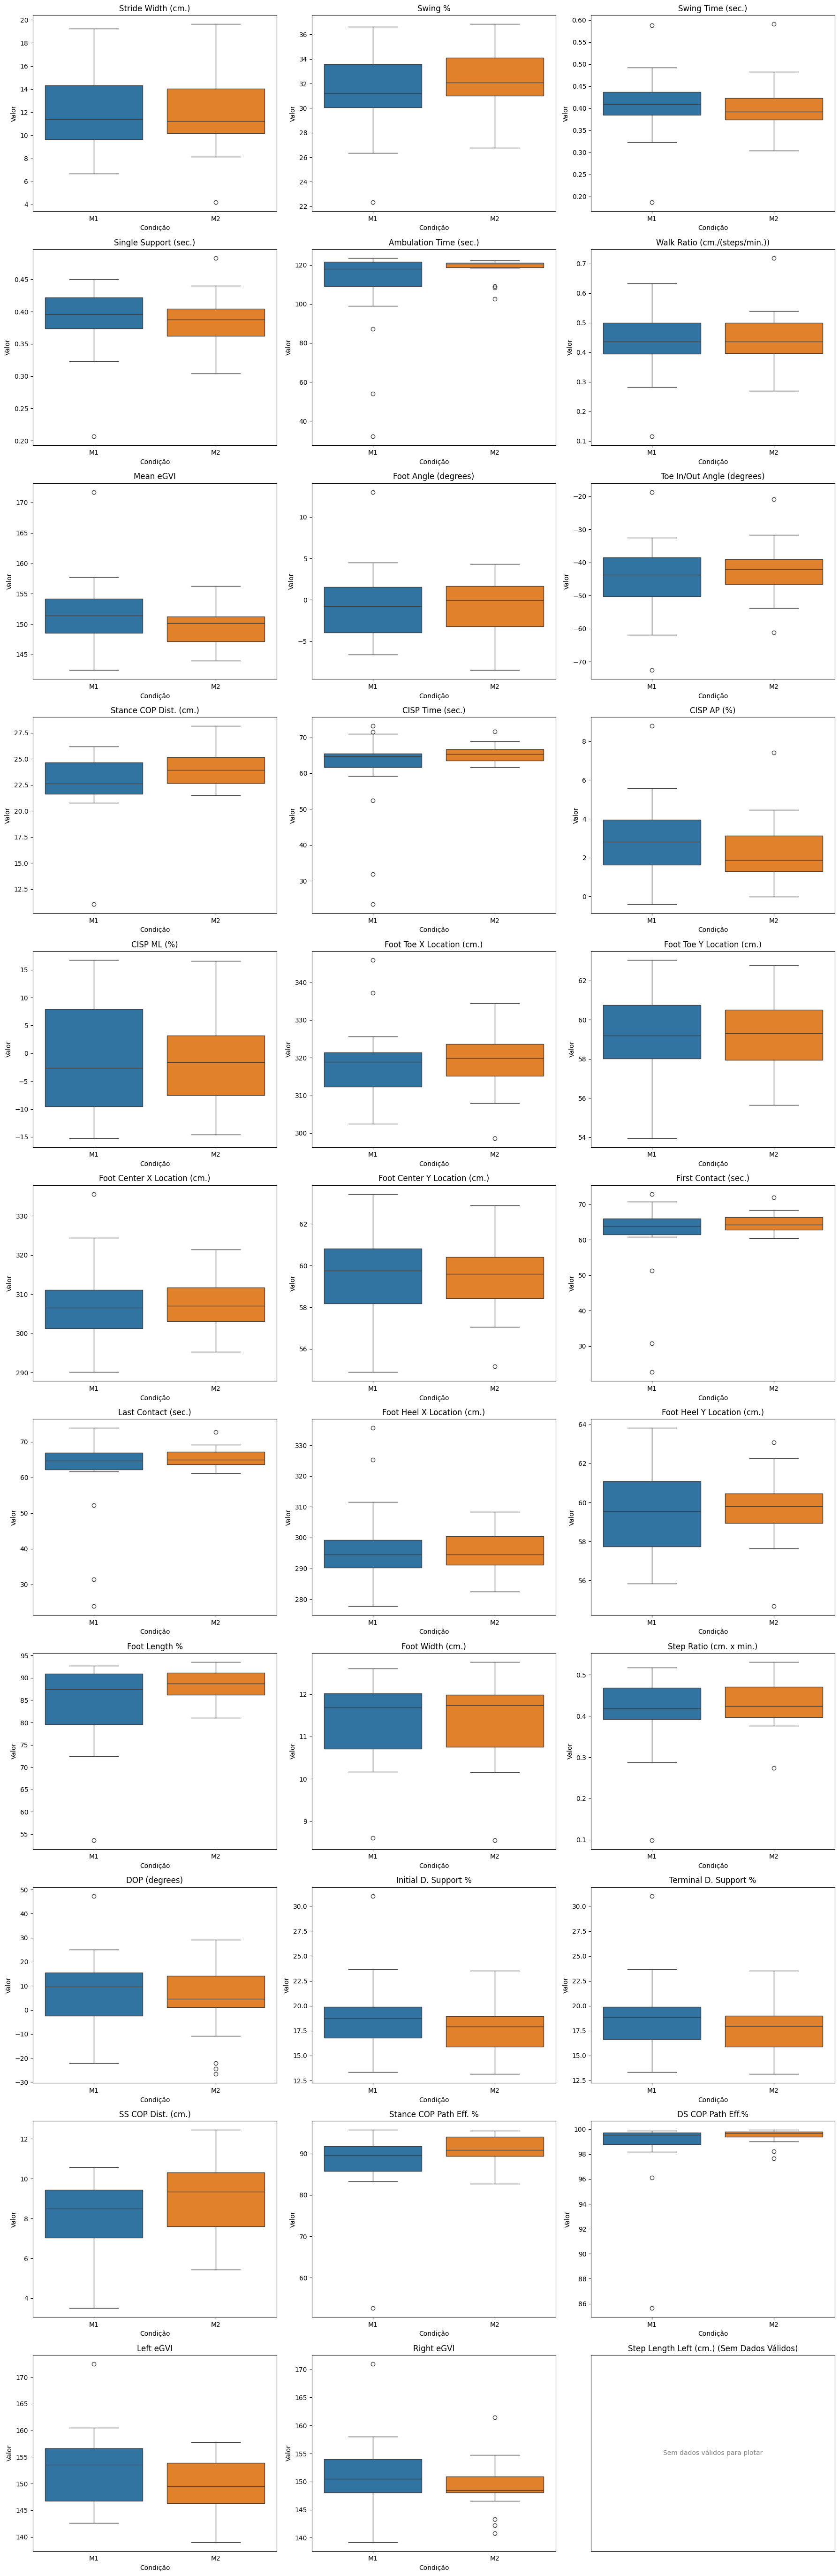

Box plots for non-significant characteristics saved to: /content/drive/MyDrive/doc_mayara/MarchaAnálise/non_significant_characteristics_boxplot.png

--- Interpretação dos Resultados Não-Significativos ---
Para as seguintes características de marcha, não foi encontrada diferença estatisticamente significativa entre as condições M1 e M2 (p >= 0.05):
- Stride Width (cm.) (p = 0.609)
- Swing % (p = 0.154)
- Swing Time (sec.) (p = 0.100)
- Single Support (sec.) (p = 0.037)
- Ambulation Time (sec.) (p = 0.133)
- Walk Ratio (cm./(steps/min.)) (p = 0.344)
- Mean eGVI (p = 0.133)
- Foot Angle (degrees) (p = 0.596)
- Toe In/Out Angle (degrees) (p = 0.294)
- Stance COP Dist. (cm.) (p = 0.021)
- CISP Time (sec.) (p = 0.154)
- CISP AP (%) (p = 0.025)
- CISP ML (%) (p = 0.409)
- Foot Toe X Location (cm.) (p = 0.715)
- Foot Toe Y Location (cm.) (p = 0.498)
- Foot Center X Location (cm.) (p = 0.648)
- Foot Center Y Location (cm.) (p = 0.475)
- First Contact (sec.) (p = 0.409)
- Last Contact (sec.) (p 

In [ ]:
# Filter df_resultados for M1 and M2 conditions
df_m1_m2_non_sig = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Melt the DataFrame for easier plotting with seaborn, using non_significant_characteristics
df_m1_m2_non_sig_melted = df_m1_m2_non_sig.melt(id_vars=['nome', 'condicao'], value_vars=non_significant_characteristics, var_name='Characteristic', value_name='Value')

# Plotting
num_non_significant_characteristics = len(non_significant_characteristics)
n_cols = 3  # Number of columns for subplots
n_rows = (num_non_significant_characteristics + n_cols - 1) // n_cols  # Calculate number of rows

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5))
axes = np.array(axes).flatten() # Convert to numpy array before flattening

for i, caracteristica in enumerate(non_significant_characteristics):
    ax = axes[i]
    df_char_data = df_m1_m2_non_sig_melted[df_m1_m2_non_sig_melted['Characteristic'] == caracteristica]
    df_char_data_clean = df_char_data.dropna(subset=['Value'])

    if df_char_data_clean.empty:
        ax.set_title(f'{caracteristica} (Sem Dados Válidos)')
        ax.text(0.5, 0.5, 'Sem dados válidos para plotar', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        # print(f"Skipping boxplot for {caracteristica}: No valid data points after dropping NaNs.")
    elif df_char_data_clean['condicao'].nunique() < 2:
        ax.set_title(f'{caracteristica} (Condições Insuficientes)')
        ax.text(0.5, 0.5, 'Dados apenas para uma condição (M1 ou M2)', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        # print(f"Skipping boxplot for {caracteristica}: Data for M1 or M2 missing.")
    else:
        sns.boxplot(x='condicao', y='Value', data=df_char_data_clean, ax=ax, hue='condicao', legend=False)
        ax.set_title(f'{caracteristica}')
        ax.set_xlabel('Condição')
        ax.set_ylabel('Valor')

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

# Save the plot
plot_filename_non_sig = pasta_dados + 'Análise/non_significant_characteristics_boxplot.png'
plt.savefig(plot_filename_non_sig)

plt.show()

print(f"Box plots for non-significant characteristics saved to: {plot_filename_non_sig}")

# Interpretation of non-significant results
print("\n--- Interpretação dos Resultados Não-Significativos ---")
if non_significant_characteristics:
    print("Para as seguintes características de marcha, não foi encontrada diferença estatisticamente significativa entre as condições M1 e M2 (p >= 0.05):")
    for char in non_significant_characteristics:
        # Retrieve the p-value for the characteristic, if available
        p_val = p_values_dict.get(char, 'N/A')
        if p_val != 'N/A':
            print(f"- {char} (p = {p_val:.3f})")
        else:
            print(f"- {char}")
    print("\nIsso sugere que a intervenção ou condição que diferencia M1 e M2 não teve um efeito mensurável nessas características específicas, ou que a amostra de dados não foi suficiente para detectar tal efeito, se ele existir.")
else:
    print("Não há características não-significativas para interpretar.")


Individual 'Gait Cycle Time (sec.)' values for M3 R1:


,nome,Gait Cycle Time (sec.)
5,DP02,1.136
8,DP03,1.327
11,DP04,1.258
17,DP06,1.053
23,DP10,1.264
29,DP12,1.013
32,DP13,1.256
35,DP14,1.003
38,DP15,1.329
53,DP20,1.054



Individual 'Gait Cycle Time (sec.)' values for M3 R2:


,nome,Gait Cycle Time (sec.)
2,DP01,1.042
14,DP05,1.230
20,DP09,1.232
26,DP11,1.364
41,DP16,1.496
44,DP17,1.058
47,DP18,1.309
50,DP19,1.527
56,DP21,1.275
59,DP22,1.209


Métricas de Marcha Agrupadas por Condição e Grupo Randomizado (onde aplicável):

Grupo: N/A (Não Aplicável), Condição: M1
  Cadência Média Global: 95.35 passos/min.
  Tempo Médio Global do Ciclo da Marcha: 1.28 segundos
  Duração Média de um Passo: 0.63 segundos

Grupo: N/A (Não Aplicável), Condição: M2
  Cadência Média Global: 98.82 passos/min.
  Tempo Médio Global do Ciclo da Marcha: 1.23 segundos
  Duração Média de um Passo: 0.61 segundos

Grupo: R1, Condição: M3
  Cadência Média Global: 101.95 passos/min.
  Tempo Médio Global do Ciclo da Marcha: 1.17 segundos
  Duração Média de um Passo: 0.59 segundos

Grupo: R2, Condição: M3
  Cadência Média Global: 95.46 passos/min.
  Tempo Médio Global do Ciclo da Marcha: 1.27 segundos
  Duração Média de um Passo: 0.63 segundos


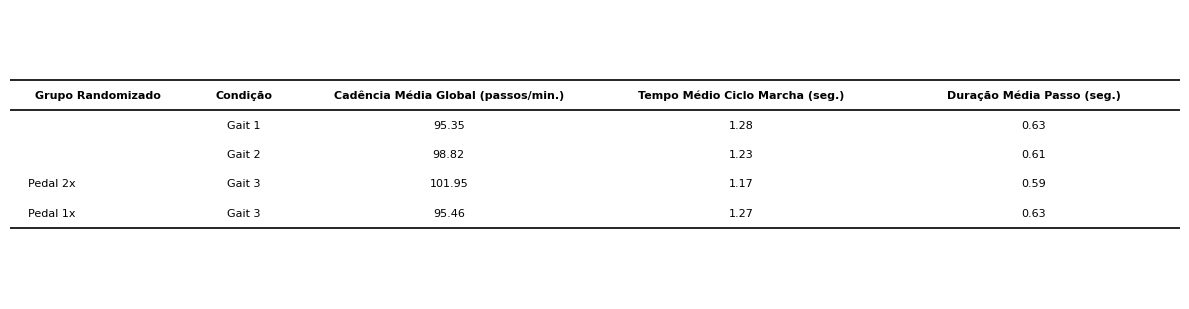

Tabela das métricas de marcha agrupadas salva em: /content/drive/MyDrive/doc_mayara/Marcha/Análise/grouped_gait_metrics_table.png

Gerando gráficos Raincloud para cadência, tempo de ciclo de marcha e duração do passo...


/tmp/ipykernel_2782/2820176688.py:225: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


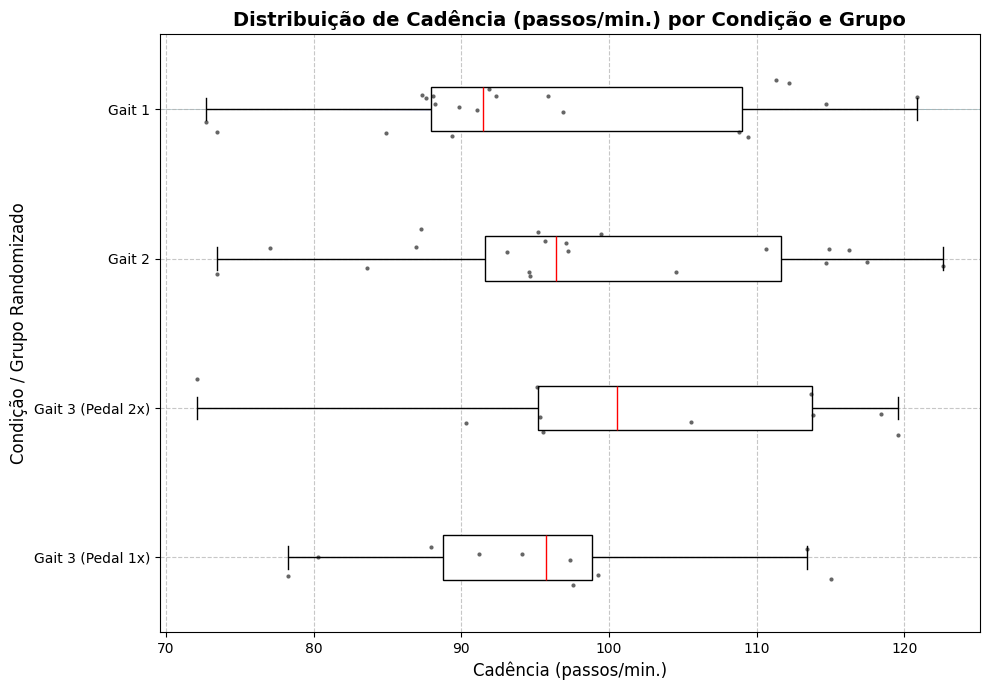

/tmp/ipykernel_2782/2820176688.py:225: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


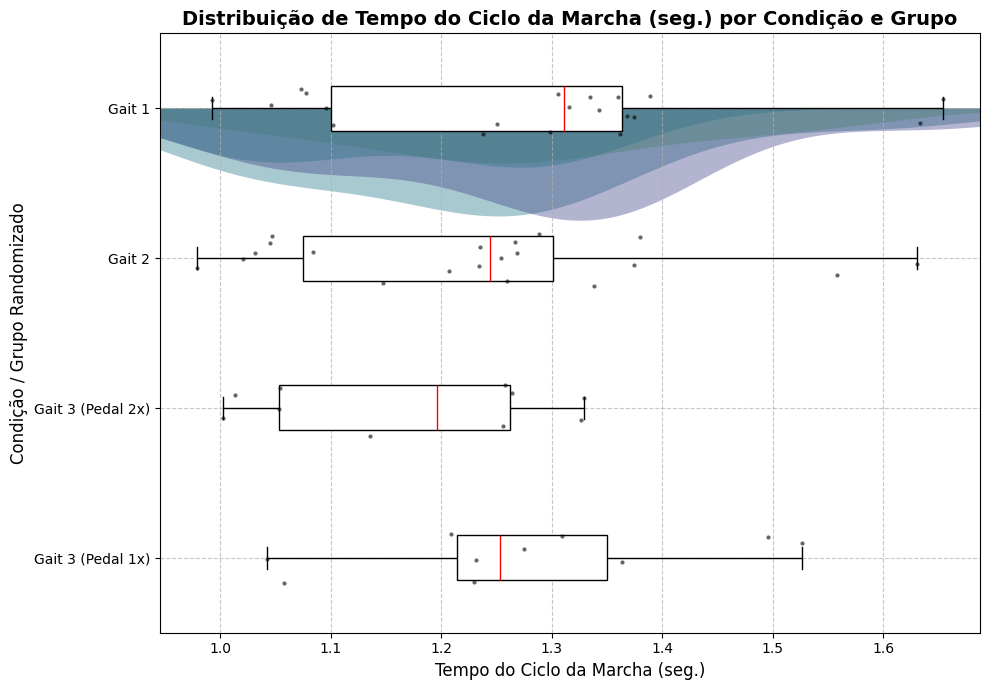

/tmp/ipykernel_2782/2820176688.py:225: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


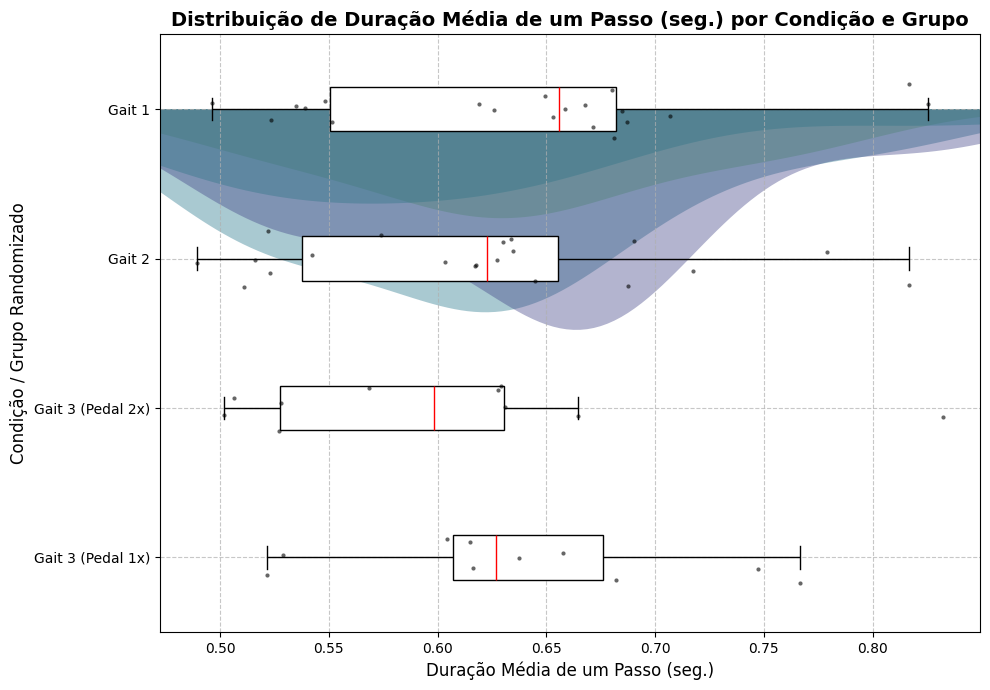

Geração dos gráficos Raincloud concluída.


In [ ]:
# Calcular a cadência média global, tempo médio global do ciclo da marcha e duração média de um passo
# para cada condição (M1, M2, M3) e grupo randomizado (R1, R2), conforme as novas regras.

import matplotlib.pyplot as plt
import os
import pandas as pd
import seaborn as sns # Importar seaborn para os gráficos Raincloud
import numpy as np # Importar numpy para cálculos e manipulação de dados

# 1. Calcular métricas para M1 e M2 sem o contexto de 'grupo_randomizado'
df_m1_m2_only = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()
grouped_m1_m2_metrics = df_m1_m2_only.groupby('condicao').agg(
    global_average_cadence=('Cadence (steps/min.)', 'mean'),
    global_mean_gait_cycle_time=('Gait Cycle Time (sec.)', 'mean')
).reset_index()

# Adicionar um placeholder para 'grupo_randomizado' para estas linhas, conforme solicitado
grouped_m1_m2_metrics['grupo_randomizado'] = ''
# Reordenar colunas para corresponder à estrutura do agrupamento M3
grouped_m1_m2_metrics = grouped_m1_m2_metrics[['grupo_randomizado', 'condicao', 'global_average_cadence', 'global_mean_gait_cycle_time']]


# 2. Calcular métricas para M3, agrupadas por 'grupo_randomizado'
df_m3_only = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Add inspection for Gait Cycle Time in M3 R1 and R2
print("\nIndividual 'Gait Cycle Time (sec.)' values for M3 R1:")
display(df_m3_only[df_m3_only['grupo_randomizado'] == 'R1'][['nome', 'Gait Cycle Time (sec.)']])

print("\nIndividual 'Gait Cycle Time (sec.)' values for M3 R2:")
display(df_m3_only[df_m3_only['grupo_randomizado'] == 'R2'][['nome', 'Gait Cycle Time (sec.)']])

grouped_m3_metrics = df_m3_only.groupby(['grupo_randomizado', 'condicao']).agg(
    global_average_cadence=('Cadence (steps/min.)', 'mean'),
    global_mean_gait_cycle_time=('Gait Cycle Time (sec.)', 'mean')
).reset_index()


# 3. Combinar os resultados
# Assegurar que todas as dataframes tenham as mesmas colunas antes de concatenar
grouped_metrics = pd.concat([grouped_m1_m2_metrics, grouped_m3_metrics], ignore_index=True)

# Ordenar para a ordem de exibição desejada (M1, M2 primeiro, depois R1/R2 sob M3)
grouped_metrics['sort_key_cond'] = grouped_metrics['condicao'].map({'M1': 0, 'M2': 1, 'M3': 2})
grouped_metrics['sort_key_grupo'] = grouped_metrics['grupo_randomizado'].map({'': 0, 'R1': 1, 'R2': 2})
grouped_metrics = grouped_metrics.sort_values(by=['sort_key_cond', 'sort_key_grupo']).drop(columns=['sort_key_cond', 'sort_key_grupo'])


# Calcular a duração média de um passo para cada grupo
grouped_metrics['mean_step_duration_s'] = 60 / grouped_metrics['global_average_cadence']

print("Métricas de Marcha Agrupadas por Condição e Grupo Randomizado (onde aplicável):")
for index, row in grouped_metrics.iterrows():
    grupo_display = row['grupo_randomizado'] if row['grupo_randomizado'] else 'N/A (Não Aplicável)' # Exibir 'N/A' para M1/M2
    print(f"\nGrupo: {grupo_display}, Condição: {row['condicao']}")
    print(f"  Cadência Média Global: {row['global_average_cadence']:.2f} passos/min.")
    print(f"  Tempo Médio Global do Ciclo da Marcha: {row['global_mean_gait_cycle_time']:.2f} segundos")
    print(f"  Duração Média de um Passo: {row['mean_step_duration_s']:.2f} segundos")

# --- Gerar e Salvar Tabela Estilo Tree Lines ---
# Reiniciar o índice (já estão como colunas devido ao reset_index e concat)
df_table_display = grouped_metrics.copy()

# Renomear colunas para exibição na tabela
df_table_display = df_table_display.rename(columns={
    'grupo_randomizado': 'Grupo Randomizado',
    'condicao': 'Condição',
    'global_average_cadence': 'Cadência Média Global (passos/min.)',
    'global_mean_gait_cycle_time': 'Tempo Médio Ciclo Marcha (seg.)',
    'mean_step_duration_s': 'Duração Média Passo (seg.)'
})

# Substituir o placeholder por string vazia para as linhas M1/M2 na exibição
df_table_display['Grupo Randomizado'] = df_table_display['Grupo Randomizado'].replace('', '')

# Substituir as nomenclaturas conforme solicitado
df_table_display['Condição'] = df_table_display['Condição'].replace({'M1': 'Gait 1', 'M2': 'Gait 2', 'M3': 'Gait 3'})
df_table_display['Grupo Randomizado'] = df_table_display['Grupo Randomizado'].replace({'R1': 'Pedal 2x', 'R2': 'Pedal 1x'})


# Formatar os valores numéricos para 2 casas decimais
for col in ['Cadência Média Global (passos/min.)', 'Tempo Médio Ciclo Marcha (seg.)', 'Duração Média Passo (seg.)']:
    df_table_display[col] = df_table_display[col].apply(lambda x: f'{x:.2f}')

# Processar o DataFrame para 'mesclar' células da coluna 'Grupo Randomizado' visualmente
merged_table_rows = []
last_grupo = None
for index, row in df_table_display.iterrows():
    current_grupo = row['Grupo Randomizado']
    if current_grupo == last_grupo:
        row['Grupo Randomizado'] = ''  # Deixar vazio para mesclagem visual
    else:
        last_grupo = current_grupo
    merged_table_rows.append(row)

df_final_display = pd.DataFrame(merged_table_rows)

# Criar figura e eixos para a tabela
fig, ax = plt.subplots(figsize=(12, df_final_display.shape[0] * 0.8)) # Ajustar tamanho da figura dinamicamente
ax.axis('off')  # Esconder eixos

# Definir larguras das colunas para melhor legibilidade
column_widths = [0.15, 0.1, 0.25, 0.25, 0.25] # Ajustar conforme necessário

tabela = ax.table(
    cellText=df_final_display.values,
    colLabels=df_final_display.columns,
    cellLoc='center',
    loc='center',
    colWidths=column_widths
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(8) # Decreased font size for header labels

# Adjust font size of colLabels separately for better control
for (row, col), cell in tabela.get_celld().items():
    if row == 0:  # Header row
        cell.set_fontsize(8) # Smaller font for header

tabela.scale(1.0, 1.5) # Ajustar escala geral da tabela

# Estilo da tabela "Tree lines"
for (row, col), cell in tabela.get_celld().items():
    cell.visible_edges = ''  # Remover todas as bordas
    cell.set_linewidth(0)

# Estilo da linha do cabeçalho
for col in range(len(df_final_display.columns)):
    tabela[(0, col)].visible_edges = 'TB'  # Bordas superior e inferior para o cabeçalho
    tabela[(0, col)].set_linewidth(1.2)
    tabela[(0, col)].set_text_props(ha='center', weight='bold', color='black')  # Texto do cabeçalho
    tabela[(0, col)].set_facecolor('white')  # Fundo branco

# Estilo das linhas de conteúdo e adicionar linha inferior para a tabela inteira
last_row = len(df_final_display)
for (row_idx_mpl, col_idx_mpl), cell in tabela.get_celld().items():
    if row_idx_mpl > 0:  # Apenas para linhas de dados, não o cabeçalho
        # Alinhar à esquerda a coluna 'Grupo Randomizado'
        if col_idx_mpl == df_final_display.columns.get_loc('Grupo Randomizado'):
            cell.set_text_props(ha='left')
        else:
            cell.set_text_props(ha='center')

        # Adicionar linha inferior apenas à última linha da tabela
        if row_idx_mpl == last_row:
            cell.visible_edges = 'B'
            cell.set_linewidth(1.2)

plt.tight_layout()

# Diretório para salvar as tabelas
output_table_dir = os.path.join(pasta_dados, 'Análise')
os.makedirs(output_table_dir, exist_ok=True)

# Salvar a tabela como imagem
table_filename = os.path.join(output_table_dir, 'grouped_gait_metrics_table.png')
plt.savefig(table_filename, dpi=300, bbox_inches='tight')
plt.show()

print(f"Tabela das métricas de marcha agrupadas salva em: {table_filename}")

# --- Início da Geração dos Gráficos Raincloud --- #
print("\nGerando gráficos Raincloud para cadência, tempo de ciclo de marcha e duração do passo...")

# Criar um DataFrame unificado para os plots Raincloud
df_raincloud = df_resultados.copy()

# Calcular a duração média de um passo para cada linha no df_resultados
df_raincloud['mean_step_duration_s'] = 60 / df_raincloud['Cadence (steps/min.)']

# Preencher 'grupo_randomizado' com string vazia para M1 e M2 para facilitar a categorização
df_raincloud['grupo_randomizado'] = df_raincloud['grupo_randomizado'].fillna('')

# Criar uma nova coluna para o eixo X dos plots, combinando Condição e Grupo Randomizado
df_raincloud['cond_grupo_display'] = df_raincloud.apply(
    lambda row: f"Gait {row['condicao'].replace('M', '')}" if row['condicao'] in ['M1', 'M2']
                else f"Gait {row['condicao'].replace('M', '')} ({row['grupo_randomizado'].replace('R1', 'Pedal 2x').replace('R2', 'Pedal 1x')})",
    axis=1
)

# Definir a ordem das categorias no eixo X
order_x = ['Gait 1', 'Gait 2', 'Gait 3 (Pedal 2x)', 'Gait 3 (Pedal 1x)']
df_raincloud['cond_grupo_display'] = pd.Categorical(df_raincloud['cond_grupo_display'], categories=order_x, ordered=True)

# Definir as métricas a serem plotadas
metrics_to_plot = {
    'Cadence (steps/min.)': 'Cadência (passos/min.)',
    'Gait Cycle Time (sec.)': 'Tempo do Ciclo da Marcha (seg.)',
    'mean_step_duration_s': 'Duração Média de um Passo (seg.)'
}

# Diretório para salvar os gráficos Raincloud
output_raincloud_dir = os.path.join(pasta_dados, 'Análise', 'Raincloud_Plots')
os.makedirs(output_raincloud_dir, exist_ok=True)

for english_metric, portuguese_metric in metrics_to_plot.items():
    plt.figure(figsize=(10, 7))

    # Verificar se a coluna existe e não está vazia após dropar NaNs
    plot_data = df_raincloud[['cond_grupo_display', english_metric]].dropna()

    if plot_data.empty:
        print(f"  Não há dados válidos para plotar '{portuguese_metric}'. Pulando.")
        plt.close()
        continue

    # Raincloud Plot (combinação de KDE, Boxplot e Stripplot)
    # 1. KDE Plot (Density)
    sns.kdeplot(
        data=plot_data,
        x=english_metric,
        hue='cond_grupo_display',
        fill=True,
        alpha=0.4,
        linewidth=0,
        palette='viridis',
        legend=False
    )

    # Inverter o KDE para ficar na parte superior ou inferior dependendo da conveniência, ou usar `seaborn.half_violinplot`
    # Para simplicidade e compatibilidade com versões mais antigas do seaborn, vamos empilhar boxplot e stripplot no KDE

    # 2. Boxplot (com a largura ajustada para ser mais estreito que a densidade)
    sns.boxplot(
        data=plot_data,
        y='cond_grupo_display',
        x=english_metric,
        width=0.3,
        boxprops={'zorder': 2, 'facecolor': 'white', 'edgecolor': 'black'},
        medianprops={'color': 'red'},
        whiskerprops={'color': 'black'},
        capprops={'color': 'black'},
        flierprops={'marker': 'o', 'markerfacecolor': 'gray', 'markeredgecolor': 'gray'},
        palette='viridis', # Usar a mesma paleta para consistência
        showfliers=False, # Não mostrar outliers, pois o stripplot já os mostra
        linewidth=1.0
    )

    # 3. Stripplot (pontos individuais)
    sns.stripplot(
        data=plot_data,
        y='cond_grupo_display',
        x=english_metric,
        jitter=0.2,
        size=3,
        color='black',
        alpha=0.6
    )

    plt.title(f'Distribuição de {portuguese_metric} por Condição e Grupo',
              fontsize=14, weight='bold')
    plt.xlabel(portuguese_metric, fontsize=12)
    plt.ylabel('Condição / Grupo Randomizado', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    # Salvar o gráfico
    safe_metric_name = english_metric.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '_').replace('.', '')
    plot_filename = os.path.join(output_raincloud_dir, f'raincloud_plot_{safe_metric_name}.png')
    plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close() # Fechar a figura para liberar memória

print("Geração dos gráficos Raincloud concluída.")
# --- Fim da Geração dos Gráficos Raincloud --- #

## Visualização de Séries Temporais Ponto a Ponto

Os gráficos anteriores de 'série temporal' compararam os valores médios das condições M1 e M2 para cada participante. Agora, vamos gerar gráficos de séries temporais *ponto a ponto* diretamente dos dados brutos de cada arquivo CSV, visualizando como cada característica de marcha se comporta ao longo dos primeiros 120 segundos.

In [ ]:
print("Verificando ciclos de marcha normalizados para cada participante (Gait 1, Gait 2 e Gait 3):")
unique_participants_in_normalized_data = set()
# The structure of all_normalized_ts is {char: {condition: {participant_id: normalized_series}}}
# So we need to collect participants from all available conditions (M1, M2)
# If M3 data were loaded upstream, it would also be collected here.
for char_data in all_normalized_ts.values():
    for condition_data in char_data.values():
        unique_participants_in_normalized_data.update(condition_data.keys())

# Ensure unique_participants is a list for consistent iteration
unique_participants_list = sorted(list(unique_participants_in_normalized_data))

if not unique_participants_list:
    print("Nenhum participante encontrado nos dados normalizados (M1 ou M2).")
else:
    for participant_id in unique_participants_list:
        print(f"\n--- Participante: {participant_id} ---")
        # Extend the conditions to include M3
        for cond in ['M1', 'M2', 'M3']:
            gait_cycles_found = 0
            # Check if any characteristic was normalized for this participant and condition
            # This check will only work for M1/M2 given the current all_normalized_ts structure.
            if cond in all_normalized_ts.values().__iter__().__next__().keys(): # Check if condition key exists in the first characteristic
                for char_name in all_normalized_ts.keys():
                    if participant_id in all_normalized_ts[char_name][cond]:
                        gait_cycles_found += 1
            # For M3, all_normalized_ts is not populated, so gait_cycles_found will be 0.
            # This is expected and handled by the 'else' block below.
            if gait_cycles_found > 0:
                # Retrieve mean Stride Time for context
                mean_stride_time = df_mean_time_series[
                    (df_mean_time_series['nome'] == participant_id) &
                    (df_mean_time_series['condicao'] == cond)
                ]['Stride Time (sec.)'].iloc[0] if not df_mean_time_series[
                    (df_mean_time_series['nome'] == participant_id) &
                    (df_mean_time_series['condicao'] == cond)
                ].empty and not pd.isna(df_mean_time_series[
                    (df_mean_time_series['nome'] == participant_id) &
                    (df_mean_time_series['condicao'] == cond)
                ]['Stride Time (sec.)'].iloc[0]) else np.nan
                print(f"  Condição {cond} (Gait {cond.replace('M', '')}):")
                print(f"    Ciclos de marcha normalizados encontrados: {gait_cycles_found} (para características onde dados válidos foram encontrados)")
                print(f"    Tempo médio da passada (Stride Time) usado: {mean_stride_time:.3f} segundos")
            else:
                print(f"  Condição {cond} (Gait {cond.replace('M', '')}): Nenhum ciclo de marcha normalizado encontrado.")
                if cond == 'M3':
                    # Add specific context for Gait 3 based on the problem summary
                    grupo_randomizado = df_mean_time_series[
                        (df_mean_time_series['nome'] == participant_id) &
                        (df_mean_time_series['condicao'] == cond)
                    ]['grupo_randomizado'].iloc[0] if not df_mean_time_series[
                        (df_mean_time_series['nome'] == participant_id) &
                        (df_mean_time_series['condicao'] == cond)
                    ].empty else "Unknown Group"
                    print(f"    (Nota para Gait 3, grupo {grupo_randomizado}): Não foi possível processar ciclos de marcha normalizados para 'Step Time' e 'Swing Time', pois o contexto anterior indicou que não há dados (zero data points) para estas características nesta condição e grupo.")

Verificando ciclos de marcha normalizados para cada participante (Gait 1, Gait 2 e Gait 3):


NameError: name 'all_normalized_ts' is not defined

In [ ]:
# ATENÇÃO: Se você estiver recebendo um NameError para 'all_normalized_ts', por favor, execute a célula 'a7942be8' primeiro.

print("Verificando ciclos de marcha normalizados para cada participante (Gait 1, Gait 2 e Gait 3):")
unique_participants_in_normalized_data = set()
# The structure of all_normalized_ts is {char: {condition: {participant_id: normalized_series}}}
# So we need to collect participants from all available conditions (M1, M2)
# If M3 data were loaded upstream, it would also be collected here.
for char_data in all_normalized_ts.values():
    for condition_data in char_data.values():
        unique_participants_in_normalized_data.update(condition_data.keys())

# Ensure unique_participants is a list for consistent iteration
unique_participants_list = sorted(list(unique_participants_in_normalized_data))

if not unique_participants_list:
    print("Nenhum participante encontrado nos dados normalizados (M1 ou M2).")
else:
    for participant_id in unique_participants_list:
        print(f"\n--- Participante: {participant_id} ---")
        # Extend the conditions to include M3
        for cond in ['M1', 'M2', 'M3']:
            gait_cycles_found = 0
            # Check if any characteristic was normalized for this participant and condition
            # This check will only work for M1/M2 given the current all_normalized_ts structure.
            if cond in all_normalized_ts.values().__iter__().__next__().keys(): # Check if condition key exists in the first characteristic
                for char_name in all_normalized_ts.keys():
                    if participant_id in all_normalized_ts[char_name][cond]:
                        gait_cycles_found += 1
            # For M3, all_normalized_ts is not populated, so gait_cycles_found will be 0.
            # This is expected and handled by the 'else' block below.
            if gait_cycles_found > 0:
                # Retrieve mean Stride Time for context
                mean_stride_time = df_mean_time_series[
                    (df_mean_time_series['nome'] == participant_id) &
                    (df_mean_time_series['condicao'] == cond)
                ]['Stride Time (sec.)'].iloc[0] if not df_mean_time_series[
                    (df_mean_time_series['nome'] == participant_id) &
                    (df_mean_time_series['condicao'] == cond)
                ].empty and not pd.isna(df_mean_time_series[
                    (df_mean_time_series['nome'] == participant_id) &
                    (df_mean_time_series['condicao'] == cond)
                ]['Stride Time (sec.)'].iloc[0]) else np.nan
                print(f"  Condição {cond} (Gait {cond.replace('M', '')}):")
                print(f"    Ciclos de marcha normalizados encontrados: {gait_cycles_found} (para características onde dados válidos foram encontrados)")
                print(f"    Tempo médio da passada (Stride Time) usado: {mean_stride_time:.3f} segundos")
            else:
                print(f"  Condição {cond} (Gait {cond.replace('M', '')}): Nenhum ciclo de marcha normalizado encontrado.")
                if cond == 'M3':
                    # Add specific context for Gait 3 based on the problem summary
                    grupo_randomizado = df_mean_time_series[
                        (df_mean_time_series['nome'] == participant_id) &
                        (df_mean_time_series['condicao'] == cond)
                    ]['grupo_randomizado'].iloc[0] if not df_mean_time_series[
                        (df_mean_time_series['nome'] == participant_id) &
                        (df_mean_time_series['condicao'] == cond)
                    ].empty else "Unknown Group"
                    print(f"    (Nota para Gait 3, grupo {grupo_randomizado}): Não foi possível processar ciclos de marcha normalizados para 'Step Time' e 'Swing Time', pois o contexto anterior indicou que não há dados (zero data points) para estas características nesta condição e grupo.")

Verificando ciclos de marcha normalizados para cada participante (Gait 1, Gait 2 e Gait 3):


NameError: name 'all_normalized_ts' is not defined

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
import re
import numpy as np
from scipy.interpolate import interp1d

# Define the number of points for normalization (simulating 0-100% of a gait cycle)
N_POINTS = 100

# Dictionary to store normalized time series for M1, M2, and M3 (grouped by R1/R2)
# Structure: {char: {condition: {participant_id: normalized_series}}} for M1/M2
#            {char: {condition_M3: {group: {participant_id: normalized_series}}}} for M3
all_normalized_ts = {}
for char in caract_marcha:
    all_normalized_ts[char] = {
        'M1': {},
        'M2': {},
        'M3': {
            'R1': {},
            'R2': {}
        }
    }

print("Collecting and normalizing time series data for M1, M2, and M3 (0-100% gait cycle)...")

# Loop through all raw data files to collect and normalize time series
for iarquivo in sorted_files_by_extracted_date:
    try:
        filename = os.path.basename(iarquivo)
        condicao_match = re.search(r'(M[123])', filename)

        if not condicao_match: # Skip if not M1, M2 or M3
            continue

        condition = condicao_match.group(1)

        ID_match = re.search(r'(DP\d+)', filename)
        participant_id = ID_match.group(1) if ID_match else 'Unknown_ID'

        # Determine randomized group for M3 if applicable
        randomized_group = None
        if condition == 'M3':
            group_match = re.search(r'(R[12])', iarquivo)
            randomized_group = group_match.group(1) if group_match else 'Unknown_Group'

        # --- Robust header parsing logic ---
        with open(iarquivo, 'r') as f:
            for _ in range(11):
                next(f)
            header_line = next(f).strip()

        detected_sep = ','
        if ';' in header_line and header_line.count(';') > header_line.count(','):
            detected_sep = ';'

        raw_columns = [col.strip() for col in header_line.split(detected_sep)]
        cleaned_columns = [col for col in raw_columns if col != '']
        # --- End of robust header parsing logic ---

        df_raw = pd.read_csv(iarquivo, skiprows=12, header=None, names=cleaned_columns, sep=detected_sep)

        time_column_name = None
        for col in df_raw.columns:
            if 'time' in col.lower() and 'sec' in col.lower():
                time_column_name = col
                break

        if time_column_name:
            df_raw['Time_Plot_Sec'] = pd.to_numeric(df_raw[time_column_name], errors='coerce')
        else:
            time_step_s = 0.01 # Assuming 100 Hz sampling if no time column
            df_raw['Time_Plot_Sec'] = df_raw.index * time_step_s

        # Filter data to exclude rows where Time_Plot_Sec is NaN
        df_raw_clean = df_raw.dropna(subset=['Time_Plot_Sec']).copy()

        # Ensure time is monotonically increasing for interpolation
        df_raw_clean = df_raw_clean.sort_values(by='Time_Plot_Sec')
        df_raw_clean = df_raw_clean[~df_raw_clean['Time_Plot_Sec'].duplicated()]

        if df_raw_clean.empty or len(df_raw_clean) < 2: # Need at least 2 points for interpolation
            # print(f"  Skipping {filename}: Not enough valid time series data.") # Debugging
            continue

        # Get the mean Stride Time for this participant and condition from df_mean_time_series
        # If M3, ensure to pass the randomized group to retrieve the correct mean stride time
        if condition == 'M3' and randomized_group:
            participant_mean_stride_time_df = df_mean_time_series[
                (df_mean_time_series['nome'] == participant_id) &
                (df_mean_time_series['condicao'] == condition) &
                (df_mean_time_series['grupo_randomizado'] == randomized_group)
            ]
        else:
            participant_mean_stride_time_df = df_mean_time_series[
                (df_mean_time_series['nome'] == participant_id) &
                (df_mean_time_series['condicao'] == condition)
            ]

        participant_mean_stride_time = participant_mean_stride_time_df['Stride Time (sec.)'].iloc[0] if not participant_mean_stride_time_df.empty and not pd.isna(participant_mean_stride_time_df['Stride Time (sec.)'].iloc[0]) else 1.2 # Default average stride time in seconds

        if participant_mean_stride_time <= 0:
            # print(f"  Skipping {filename}: Invalid Stride Time ({participant_mean_stride_time}).") # Debugging
            continue

        # Define one gait cycle segment based on the mean stride time, starting from the trial's minimum time
        segment_start_time = df_raw_clean['Time_Plot_Sec'].min()
        segment_end_time = segment_start_time + participant_mean_stride_time

        df_gait_cycle_segment = df_raw_clean[
            (df_raw_clean['Time_Plot_Sec'] >= segment_start_time) &
            (df_raw_clean['Time_Plot_Sec'] <= segment_end_time)
        ].copy()

        if df_gait_cycle_segment.empty or len(df_gait_cycle_segment) < 2: # Need at least 2 points for interpolation
            # print(f"  Skipping {filename}: Segment too short for interpolation after cleaning.") # Debugging
            continue

        # Normalize time to 0-N_POINTS-1 and resample for each characteristic
        for caracteristica in caract_marcha:
            if caracteristica in df_gait_cycle_segment.columns:

                # DEBUG BLOCK START
                if (participant_id == 'DP01' and condition == 'M3') or \
                   (caracteristica in ['Cadence (steps/min.)', 'Velocity (cm./sec.)'] and condition in ['M1', 'M2'] and participant_id == 'DP01'):
                    print(f"\n--- Debugging for {participant_id}, {condition}, {randomized_group if condition == 'M3' else ''}, Char: {caracteristica} ---")
                    print(f"  df_raw_clean shape: {df_raw_clean.shape}")
                    print(f"  participant_mean_stride_time: {participant_mean_stride_time}")
                    print(f"  segment_start_time: {segment_start_time}, segment_end_time: {segment_end_time}")
                    print(f"  df_gait_cycle_segment shape: {df_gait_cycle_segment.shape}")
                    # Check value column properties before dropping NaNs
                    value_series = pd.to_numeric(df_gait_cycle_segment[caracteristica], errors='coerce')
                    print(f"  Characteristic column '{caracteristica}' has {value_series.count()} non-NaN values out of {len(value_series)} in segment.")

                # DEBUG BLOCK END

                y_values = pd.to_numeric(df_gait_cycle_segment[caracteristica], errors='coerce').dropna().values
                time_values = df_gait_cycle_segment.loc[pd.to_numeric(df_gait_cycle_segment[caracteristica], errors='coerce').notna(), 'Time_Plot_Sec'].values

                if len(y_values) < 2: # Need at least 2 points for interpolation
                    # DEBUG BLOCK START
                    if (participant_id == 'DP01' and condition == 'M3') or \
                       (caracteristica in ['Cadence (steps/min.)', 'Velocity (cm./sec.)'] and condition in ['M1', 'M2'] and participant_id == 'DP01'):
                        print(f"    Skipping {caracteristica}: Not enough valid data points ({len(y_values)}) for interpolation in segment.")
                    # DEBUG BLOCK END
                    continue

                # Create an interpolation function
                f_interp = interp1d(time_values, y_values, kind='linear', fill_value="extrapolate")

                # Create new x-axis points from 0 to N_POINTS-1
                # Map these to the original time range for interpolation
                # The original time range for interpolation is now exactly `participant_mean_stride_time`
                resampled_time_points = np.linspace(time_values.min(), time_values.min() + participant_mean_stride_time, N_POINTS)

                # Interpolate to N_POINTS
                resampled_y = f_interp(resampled_time_points)

                if condition == 'M3' and randomized_group:
                    all_normalized_ts[caracteristica]['M3'][randomized_group][participant_id] = pd.Series(resampled_y)
                else:
                    all_normalized_ts[caracteristica][condition][participant_id] = pd.Series(resampled_y)

    except Exception as e:
        # print(f"  Error processing file {iarquivo}: {e}. Skipping for time series plotting.") # Debugging
        pass # Silently skip files that don't match expected format or cause errors

print("Finished collecting and normalizing time series data.")

# Ensure necessary variables from previous cells are available. Define fallbacks if not.
if 'significant_characteristics_fdr_05' not in globals():
    print("WARNING: 'significant_characteristics_fdr_05' not found. Cannot filter for significant characteristics. Using an empty list.")
    significant_characteristics_fdr_05 = []

if 'eng_to_port_map' not in globals():
    print("WARNING: 'eng_to_port_map' not found. Using English names for output. Defining a fallback.")
    # Define eng_to_port_map if not already defined
    translation_map_data = {
        'Característica (Inglês)': caract_marcha,
        'Tradução (Português)': caract_marcha # Fallback: use English if no translation map is available
    }
    eng_to_port_map = dict(zip(translation_map_data['Característica (Inglês)'], translation_map_data['Tradução (Português)']))

if 'p_values_dict' not in globals():
    print("WARNING: 'p_values_dict' not found. P-values will not be displayed on plots. Defining an empty fallback.")
    p_values_dict = {}

def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

# Create a directory for saving the normalized time series plots
output_plot_dir_normalized_ts = os.path.join(pasta_dados, 'Análise', 'Normalized_Gait_Cycle_Time_Series')
os.makedirs(output_plot_dir_normalized_ts, exist_ok=True)

print("Generating mean normalized time series plots for significant characteristics (M1 vs M2)...")

# Loop through each significant characteristic to generate plots
for caracteristica in significant_characteristics_fdr_05:
    plt.figure(figsize=(10, 6))

    # Collect all normalized series for M1 and M2 for this characteristic
    m1_series_list = [s for s in all_normalized_ts[caracteristica]['M1'].values() if not s.empty]
    m2_series_list = [s for s in all_normalized_ts[caracteristica]['M2'].values() if not s.empty]

    mean_m1_ts = None
    mean_m2_ts = None

    if m1_series_list:
        # Combine all M1 series into a DataFrame and calculate the mean across participants
        df_m1_combined = pd.DataFrame(m1_series_list).mean()
        mean_m1_ts = pd.Series(df_m1_combined.values, index=np.linspace(0, 100, N_POINTS))
        sns.lineplot(x=mean_m1_ts.index, y=mean_m1_ts.values, label='Gait 1 (Média)', color='blue', linewidth=2)

    if m2_series_list:
        # Combine all M2 series into a DataFrame and calculate the mean across participants
        df_m2_combined = pd.DataFrame(m2_series_list).mean()
        mean_m2_ts = pd.Series(df_m2_combined.values, index=np.linspace(0, 100, N_POINTS))
        sns.lineplot(x=mean_m2_ts.index, y=mean_m2_ts.values, label='Gait 2 (Média)', color='orange', linewidth=2)

    if mean_m1_ts is not None or mean_m2_ts is not None:
        # Get p-value and significance stars
        p_val = p_values_dict.get(caracteristica)
        title_suffix = f' (p={p_val:.3f}{get_significance_stars(p_val)})' if p_val is not None and not pd.isna(p_val) else ''

        # Translate characteristic name for plot title and labels
        caracteristica_portugues = eng_to_port_map.get(caracteristica, caracteristica)

        plt.title(f'Ciclo da Marcha Normalizado (0-100%): {caracteristica_portugues}{title_suffix}', fontsize=14)
        plt.xlabel('Percentual do Ciclo da Marcha (%)', fontsize=12)
        # Extract unit from original name, if available, otherwise just use the translated name
        unit_match = re.search(r'\((.*?)\)', caracteristica)
        y_label_unit = unit_match.group(1) if unit_match else "Unidade"
        plt.ylabel(f'{caracteristica_portugues} ({y_label_unit})', fontsize=12)
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.legend(title='Condição', fontsize=10)
        plt.tight_layout()

        # Sanitize characteristic name for filename
        safe_caracteristica = ''.join([c if c.isalnum() or c in ['(', ')', '.', ' '] else '_' for c in caracteristica]).replace(' ', '_')
        plot_filename = os.path.join(output_plot_dir_normalized_ts, f'Normalized_Gait_Cycle_TS_M1_M2_{safe_caracteristica}.png')
        plt.savefig(plot_filename)
        plt.close() # Close the figure to free memory
        print(f"  Saved plot: {plot_filename}")
    else:
        plt.close()
        print(f"  Skipping plot for {caracteristica}: No valid normalized data for M1 or M2.")

print("Finished generating all normalized gait cycle time series plots.")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def plot_footprint(df):
    fig, ax = plt.subplots(figsize=(12, 6))

    # Define colors and display names for the groups based on the Gait 3 context
    colors_map = {"R1": "black", "R2": "green"}
    display_group_names = {"R1": "Pedal 2x", "R2": "Pedal 1x"}

    # Loop through groups and then through each foot measurement
    for g in sorted(df["group"].unique()):
        df_g = df[df["group"] == g].reset_index(drop=True)

        for i, row in df_g.iterrows():
            # Raw coordinates for X and Y (no normalization applied as per request)
            heel_x_raw = row["heel_x"]
            center_x_raw = row["center_x"]
            toe_x_raw = row["toe_x"]

            heel_y_raw = row["heel_y"]
            center_y_raw = row["center_y"]
            toe_y_raw = row["toe_y"]

            # Use raw X-coordinates and raw Y-coordinates
            x_coords = [heel_x_raw, center_x_raw, toe_x_raw]
            y_coords = [heel_y_raw, center_y_raw, toe_y_raw]

            # Plot lines connecting heel, center, and toe
            ax.plot(x_coords, y_coords, color=colors_map[g], alpha=0.6, linewidth=1)
            # Plot scatter points for heel, center, and toe
            ax.scatter(x_coords, y_coords, color=colors_map[g], s=50, zorder=5)

    # Set title and labels in Portuguese
    ax.set_title("Reconstrução 2D do Footprint (com posições reais) para Gait 3 por Grupo", fontsize=14)
    # Updated X-axis label to reflect raw values (no normalization)
    ax.set_xlabel("Posição Médio-Lateral (cm)", fontsize=12)
    # Y-axis label already reflects raw values
    ax.set_ylabel("Posição Antero-posterior (cm)", fontsize=12)

    # Let matplotlib determine appropriate x-ticks for raw values

    # Create custom legend for groups, using translated names
    handles = [plt.Line2D([0], [0], marker='o', color='w', label=display_group_names.get(group, group),
                        markerfacecolor=colors_map[group], markersize=10) for group in sorted(df["group"].unique())]
    ax.legend(handles=handles, title="Grupo Randomizado")

    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# --- Prepare data for plotting (copied from previous execution context if df_plot_data is not already available) ---
# This assumes df_resultados is already loaded and available.

# Filter df_resultados for M3 condition
df_m3_foot_data = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Select and rename relevant columns
# Ensure 'grupo_randomizado' is treated as a string for consistent grouping
df_plot_data = df_m3_foot_data.rename(columns={
    'grupo_randomizado': 'group',
    'Foot Heel Y Location (cm.)': 'heel_y',
    'Foot Center Y Location (cm.)': 'center_y',
    'Foot Toe Y Location (cm.)': 'toe_y',
    'Foot Heel X Location (cm.)': 'heel_x',
    'Foot Center X Location (cm.)': 'center_x',
    'Foot Toe X Location (cm.)': 'toe_x'
})

# Keep only the necessary columns for the plot
df_plot_data = df_plot_data[['group', 'heel_y', 'center_y', 'toe_y', 'heel_x', 'center_x', 'toe_x']].copy()

# Drop rows with any missing values in the foot coordinates to avoid errors in plotting
df_plot_data.dropna(subset=['heel_y', 'center_y', 'toe_y', 'heel_x', 'center_x', 'toe_x'], inplace=True)

# Convert 'group' to string type to ensure consistent behavior
df_plot_data['group'] = df_plot_data['group'].astype(str)

# Sort by group to ensure consistent order (e.g., R1 then R2)
df_plot_data.sort_values(by='group', inplace=True)

# Call the plotting function
if not df_plot_data.empty:
    plot_footprint(df_plot_data)
else:
    print("No valid foot layout data available for M3 (R1 vs R2) after filtering.")

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd # Import pandas for DataFrame construction

def plot_density(df_plot_data):
    fig, ax = plt.subplots(figsize=(10, 8))

    # Define colors and display names for the groups
    colors_map = {"R1": "black", "R2": "green"}
    display_group_names = {"R1": "Pedal 2x", "R2": "Pedal 1x"}

    # Parameters for simulating local spread around each foot point
    # This simulates the 'area' of contact around the heel, center, toe points,
    # making the density plot more continuous than just discrete points.
    point_spread_std = 0.5  # Standard deviation for local spread (e.g., foot width variation)
    num_points_per_segment = 10 # Number of points sampled along each foot segment (heel-center, center-toe)

    all_xs, all_ys, all_group_labels = [], [], [] # Changed from all_ys_norm to all_ys to store real Ys

    # NO X-OFFSET FOR VISUAL SEPARATION - use actual X-coordinates

    for group_id, display_name in display_group_names.items():
        df_g = df_plot_data[df_plot_data["group"] == group_id].copy()

        if df_g.empty:
            print(f"No data for group {group_id}. Skipping density plot for this group.")
            continue

        for _, r in df_g.iterrows():
            # Get actual coordinates for the current foot
            heel_x, heel_y = r["heel_x"], r["heel_y"]
            center_x, center_y = r["center_x"], r["center_y"]
            toe_x, toe_y = r["toe_x"], r["toe_y"]

            # Generate points along the heel-center segment using real Ys
            segment1_xs = np.linspace(heel_x, center_x, num_points_per_segment)
            segment1_ys = np.linspace(heel_y, center_y, num_points_per_segment)

            # Generate points along the center-toe segment using real Ys
            # Skip the first point of the second segment to avoid duplication of 'center'
            segment2_xs = np.linspace(center_x, toe_x, num_points_per_segment)[1:]
            segment2_ys = np.linspace(center_y, toe_y, num_points_per_segment)[1:]

            # Combine points for the entire foot outline
            foot_xs = np.concatenate((segment1_xs, segment2_xs))
            foot_ys = np.concatenate((segment1_ys, segment2_ys)) # Use real Ys

            # Add random spread around each generated point to create density effect
            # Note: X-coordinates are not normalized here.
            # The spread for Y is also not normalized now, applying point_spread_std directly.
            density_xs = foot_xs + np.random.normal(0, point_spread_std, len(foot_xs))
            density_ys = foot_ys + np.random.normal(0, point_spread_std, len(foot_ys)) # Apply spread directly

            all_xs.extend(density_xs)
            all_ys.extend(density_ys) # Extend real Ys
            all_group_labels.extend([display_name] * len(density_xs))

    # Create a temporary DataFrame for kdeplot
    df_density_data = pd.DataFrame({
        'x': all_xs,
        'y': all_ys, # Use real Ys
        'group_label': all_group_labels
    })

    # Map display names to actual colors for kdeplot
    kde_colors_map = {display_group_names["R1"]: colors_map["R1"], display_group_names["R2"]: colors_map["R2"]}

    sns.kdeplot(
        x=df_density_data['x'],
        y=df_density_data['y'],
        hue=df_density_data['group_label'],
        fill=True,
        # cmap="Reds", # cmap parameter ignored when using hue mapping. Remove.
        levels=40,
        alpha=0.6,
        ax=ax,
        palette=kde_colors_map # Apply the color map for the hue variable
    )

    ax.set_title("Densidade de Contato Plantar (Real) para Gait 3 por Grupo", fontsize=14)
    ax.set_xlabel("Posição Médio-Lateral (cm)", fontsize=12)
    # Updated Y-axis label to reflect real (non-normalized) values
    ax.set_ylabel("Posição Antero-posterior (cm)", fontsize=12)

    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# Call the plotting function with the prepared data
# df_plot_data is already available from previous execution (e.g., cell fnNEw9fp15VE)
if 'df_plot_data' in locals() and not df_plot_data.empty:
    plot_density(df_plot_data)
else:
    print("df_plot_data not found or is empty. Please ensure it's prepared with 'group', 'heel_y', 'center_y', 'toe_y' data for Gait 3.")

In [ ]:
def plot_mean_shape(df):
    fig, ax = plt.subplots(figsize=(10, 8))

    # Define colors and display names for the groups based on the Gait 3 context
    colors_map = {"R1": "black", "R2": "green"}
    display_group_names = {"R1": "Pedal 2x", "R2": "Pedal 1x"}

    # Offset to visually separate the mean foot shapes of R1 and R2 along the X-axis
    group_offsets = {"R1": -2.5, "R2": 2.5} # Arbitrary offsets in cm for visual separation

    # Sort groups to ensure consistent plotting order (e.g., R1 then R2)
    for g in sorted(df["group"].unique()):
        df_g = df[df["group"] == g]

        # Calculate mean coordinates for heel, center, and toe for the current group
        mean_heel_x = df_g["heel_x"].mean()
        mean_heel_y = df_g["heel_y"].mean()
        mean_center_x = df_g["center_x"].mean()
        mean_center_y = df_g["center_y"].mean()
        mean_toe_x = df_g["toe_x"].mean()
        mean_toe_y = df_g["toe_y"].mean()

        # Apply the group-specific offset to the X-coordinates
        offset = group_offsets.get(g, 0) # Get offset, default to 0 if not found

        x_coords_mean = [mean_heel_x + offset, mean_center_x + offset, mean_toe_x + offset]
        y_coords_mean = [mean_heel_y, mean_center_y, mean_toe_y]

        # Plot the mean foot shape as a line and points
        ax.plot(x_coords_mean, y_coords_mean, color=colors_map[g], linewidth=3, zorder=1)
        ax.scatter(x_coords_mean, y_coords_mean, color=colors_map[g], s=80, zorder=5,
                   label=display_group_names.get(g, g))

    ax.set_title("Forma Média do Pé por Grupo (Gait 3)", fontsize=14)
    ax.set_xlabel("Posição Médio-Lateral (cm)", fontsize=12)
    ax.set_ylabel("Posição Antero-posterior (cm)", fontsize=12)
    ax.legend(title="Grupo Randomizado", loc='best')
    ax.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# --- Prepare data for plotting the mean foot shape for Gait 3 R1 vs R2 ---
# This assumes df_resultados is already loaded and available.

# Filter df_resultados for M3 condition
df_m3_foot_data_mean_shape = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Select and rename relevant columns
df_plot_data_mean_shape = df_m3_foot_data_mean_shape.rename(columns={
    'grupo_randomizado': 'group',
    'Foot Heel Y Location (cm.)': 'heel_y',
    'Foot Center Y Location (cm.)': 'center_y',
    'Foot Toe Y Location (cm.)': 'toe_y',
    'Foot Heel X Location (cm.)': 'heel_x',
    'Foot Center X Location (cm.)': 'center_x',
    'Foot Toe X Location (cm.)': 'toe_x'
})

# Keep only the necessary columns for the plot
df_plot_data_mean_shape = df_plot_data_mean_shape[['group', 'heel_y', 'center_y', 'toe_y', 'heel_x', 'center_x', 'toe_x']].copy()

# Drop rows with any missing values in the foot coordinates to avoid errors in plotting
df_plot_data_mean_shape.dropna(subset=['heel_y', 'center_y', 'toe_y', 'heel_x', 'center_x', 'toe_x'], inplace=True)

# Convert 'group' to string type to ensure consistent behavior
df_plot_data_mean_shape['group'] = df_plot_data_mean_shape['group'].astype(str)

# Sort by group to ensure consistent order (e.g., R1 then R2)
df_plot_data_mean_shape.sort_values(by='group', inplace=True)

# Call the plotting function
if not df_plot_data_mean_shape.empty:
    plot_mean_shape(df_plot_data_mean_shape)
else:
    print("No valid foot layout data available for M3 (R1 vs R2) after filtering for mean shape plot.")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_mean_shape(df):
    fig, ax = plt.subplots(figsize=(12, 10))

    # Define colors and display names for the groups based on the Gait 3 context
    colors_map = {"R1": "black", "R2": "green"}
    display_group_names = {"R1": "Pedal 2x", "R2": "Pedal 1x"}

    # --- 1. Prepare data for density plot (using individual foot data) ---
    # Parameters for simulating local spread around each foot point
    point_spread_std = 0.5  # Standard deviation for local spread (e.g., foot width variation in cm)
    num_points_per_segment = 10 # Number of points sampled along each foot segment (heel-center, center-toe)

    all_xs, all_ys, all_group_labels = [], [], []

    for group_id, display_name in display_group_names.items():
        df_g = df[df["group"] == group_id].copy()

        if df_g.empty:
            continue

        for _, r in df_g.iterrows():
            # Get actual coordinates for the current foot
            heel_x, heel_y = r["heel_x"], r["heel_y"]
            center_x, center_y = r["center_x"], r["center_y"]
            toe_x, toe_y = r["toe_x"], r["toe_y"]

            # Generate points along the heel-center segment
            segment1_xs = np.linspace(heel_x, center_x, num_points_per_segment)
            segment1_ys = np.linspace(heel_y, center_y, num_points_per_segment)

            # Generate points along the center-toe segment
            segment2_xs = np.linspace(center_x, toe_x, num_points_per_segment)[1:] # Skip first to avoid center duplication
            segment2_ys = np.linspace(center_y, toe_y, num_points_per_segment)[1:]

            # Combine points for the entire foot outline
            foot_xs = np.concatenate((segment1_xs, segment2_xs))
            foot_ys = np.concatenate((segment1_ys, segment2_ys))

            # Add random spread around each generated point to create density effect
            density_xs = foot_xs + np.random.normal(0, point_spread_std, len(foot_xs))
            density_ys = foot_ys + np.random.normal(0, point_spread_std, len(foot_ys))

            all_xs.extend(density_xs)
            all_ys.extend(density_ys)
            all_group_labels.extend([display_name] * len(density_xs))

    # Create a temporary DataFrame for kdeplot
    df_density_data = pd.DataFrame({
        'x': all_xs,
        'y': all_ys,
        'group_label': all_group_labels
    })

    # Map display names to actual colors for kdeplot
    kde_colors_map = {display_group_names["R1"]: colors_map["R1"], display_group_names["R2"]: colors_map["R2"]}

    # --- 2. Plot KDE for density ---
    sns.kdeplot(
        x=df_density_data['x'],
        y=df_density_data['y'],
        hue=df_density_data['group_label'],
        fill=True,
        levels=15, # Reduced levels for cleaner look, can be adjusted
        alpha=0.3, # Semi-transparent
        ax=ax,
        palette=kde_colors_map,
        zorder=1 # Plot density behind mean shapes
    )

    # --- 3. Plot Mean Foot Shapes (without offset) ---
    for g in sorted(df["group"].unique()):
        df_g = df[df["group"] == g]

        # Calculate mean coordinates for heel, center, and toe for the current group
        mean_heel_x = df_g["heel_x"].mean()
        mean_heel_y = df_g["heel_y"].mean()
        mean_center_x = df_g["center_x"].mean()
        mean_center_y = df_g["center_y"].mean()
        mean_toe_x = df_g["toe_x"].mean()
        mean_toe_y = df_g["toe_y"].mean()

        x_coords_mean = [mean_heel_x, mean_center_x, mean_toe_x] # NO X-OFFSET
        y_coords_mean = [mean_heel_y, mean_center_y, mean_toe_y]

        # Plot the mean foot shape as a line and points
        ax.plot(x_coords_mean, y_coords_mean, color=colors_map[g], linewidth=3, zorder=3) # Zorder to be above density
        ax.scatter(x_coords_mean, y_coords_mean, color=colors_map[g], s=80, zorder=5,
                   label=f'Média {display_group_names.get(g, g)}') # Add 'Média' to label

    # Set title and labels in Portuguese
    ax.set_title("Overplot: Densidade e Forma Média do Pé por Grupo (Gait 3)", fontsize=14)
    ax.set_xlabel("Posição Médio-Lateral (cm)", fontsize=12)
    ax.set_ylabel("Posição Antero-posterior (cm)", fontsize=12)
    ax.legend(title="Grupo Randomizado", loc='best')
    ax.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


# Prepare data for plotting the mean foot shape for Gait 3 R1 vs R2
# This assumes df_resultados is already loaded and available.

# Filter df_resultados for M3 condition
df_m3_foot_data_mean_shape = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Select and rename relevant columns
df_plot_data_mean_shape = df_m3_foot_data_mean_shape.rename(columns={
    'grupo_randomizado': 'group',
    'Foot Heel Y Location (cm.)': 'heel_y',
    'Foot Center Y Location (cm.)': 'center_y',
    'Foot Toe Y Location (cm.)': 'toe_y',
    'Foot Heel X Location (cm.)': 'heel_x',
    'Foot Center X Location (cm.)': 'center_x',
    'Foot Toe X Location (cm.)': 'toe_x'
})

# Keep only the necessary columns for the plot
df_plot_data_mean_shape = df_plot_data_mean_shape[['group', 'heel_y', 'center_y', 'toe_y', 'heel_x', 'center_x', 'toe_x']].copy()

# Drop rows with any missing values in the foot coordinates to avoid errors in plotting
df_plot_data_mean_shape.dropna(subset=['heel_y', 'center_y', 'toe_y', 'heel_x', 'center_x', 'toe_x'], inplace=True)

# Convert 'group' to string type to ensure consistent behavior
df_plot_data_mean_shape['group'] = df_plot_data_mean_shape['group'].astype(str)

# Sort by group to ensure consistent order (e.g., R1 then R2)
df_plot_data_mean_shape.sort_values(by='group', inplace=True)

# Call the plotting function
if not df_plot_data_mean_shape.empty:
    plot_mean_shape(df_plot_data_mean_shape)
else:
    print("No valid foot layout data available for M3 (R1 vs R2) after filtering for mean shape plot.")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os
import scipy.stats as stats

# Filter df_resultados for M3 condition
df_m3 = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Separate into R1 and R2 groups
df_r1_m3 = df_m3[df_m3['grupo_randomizado'] == 'R1'].copy()
df_r2_m3 = df_m3[df_m3['grupo_randomizado'] == 'R2'].copy()

p_values_r1_r2_m3 = {}
significant_characteristics_r1_r2_m3_05 = []
significant_characteristics_r1_r2_m3_01 = []

print("Performing independent t-tests for Gait 3 condition (R1 vs R2)...")

for caracteristica in caract_marcha:
    # Get the data for the current characteristic for R1 and R2 in M3
    data_r1 = df_r1_m3[caracteristica].dropna()
    data_r2 = df_r2_m3[caracteristica].dropna()

    # Ensure there's enough data for both groups to perform the test
    if len(data_r1) > 1 and len(data_r2) > 1:
        try:
            # Perform independent t-test
            ttest_result = stats.ttest_ind(data_r1, data_r2, equal_var=False, nan_policy='omit')
            p_value = ttest_result.pvalue
            p_values_r1_r2_m3[caracteristica] = p_value

            if p_value < 0.05:
                significant_characteristics_r1_r2_m3_05.append(caracteristica)
            if p_value < 0.01:
                significant_characteristics_r1_r2_m3_01.append(caracteristica)
        except Exception as e:
            p_values_r1_r2_m3[caracteristica] = np.nan
    else:
        p_values_r1_r2_m3[caracteristica] = np.nan

print("Finished performing independent t-tests.")

# Close any existing plots to clear the matplotlib state
plt.close('all')

# Filter df_resultados for M3 condition
df_m3_filtered = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Identify non-significant characteristics for R1 vs R2 in M3
non_significant_characteristics_r1_r2_m3 = [char for char in caract_marcha if char not in significant_characteristics_r1_r2_m3_05]

# Melt the DataFrame for easier plotting with seaborn
df_m3_melted_non_sig = df_m3_filtered.melt(
    id_vars=['nome', 'condicao', 'grupo_randomizado'],
    value_vars=non_significant_characteristics_r1_r2_m3,
    var_name='Characteristic',
    value_name='Value'
)

# Add a new column for custom labels
df_m3_melted_non_sig['grupo_randomizado_label'] = df_m3_melted_non_sig['grupo_randomizado'].map({'R1': 'Pedal2x', 'R2': 'Pedal1x'})

# Create a directory for saving plots
output_plot_dir_r1_r2_m3_boxplot_swarm_non_sig = os.path.join(pasta_dados, 'Análise', 'Boxplots_Swarm_R1_R2_Gait3_Nao_Significativas')
os.makedirs(output_plot_dir_r1_r2_m3_boxplot_swarm_non_sig, exist_ok=True)

print("Generating box plots with swarm overlay for NON-significant characteristics (R1 vs R2 in Gait 3)...")

# Plotting
num_characteristics_r1_r2_m3_non_sig = len(non_significant_characteristics_r1_r2_m3)

# Adjust number of columns for better layout based on total characteristics
if num_characteristics_r1_r2_m3_non_sig > 10:
    n_cols = 4
elif num_characteristics_r1_r2_m3_non_sig > 5:
    n_cols = 3
else:
    n_cols = 2

n_rows = (num_characteristics_r1_r2_m3_non_sig + n_cols - 1) // n_cols  # Calculate number of rows

# Adjust figsize dynamically based on the number of plots to ensure readability
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5))
axes = np.array(axes).flatten() # Convert to numpy array before flattening

for i, caracteristica in enumerate(non_significant_characteristics_r1_r2_m3):
    ax = axes[i]
    df_char_data = df_m3_melted_non_sig[df_m3_melted_non_sig['Characteristic'] == caracteristica]
    df_char_data_clean = df_char_data.dropna(subset=['Value', 'grupo_randomizado_label']) # Use the new label column

    if df_char_data_clean.empty or df_char_data_clean['grupo_randomizado_label'].nunique() < 2:
        ax.set_title(f'{caracteristica} (Sem Dados Válidos/Grupos)')
        ax.text(0.5, 0.5, 'Sem dados válidos para plotar', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray')
        ax.set_xticks([])
        ax.set_yticks([])
    else:
        # Plot Boxplot
        sns.boxplot(x='grupo_randomizado_label', y='Value', data=df_char_data_clean, ax=ax, palette='light:salmon', hue='grupo_randomizado_label', legend=False)
        # Overlay Swarmplot
        sns.swarmplot(x='grupo_randomizado_label', y='Value', data=df_char_data_clean, ax=ax, color='black', size=3, alpha=0.6, dodge=True)
        ax.set_title(f'{caracteristica} (Pedal2x vs Pedal1x em Gait 3)')
        ax.set_xlabel('Condição do Pedal')
        ax.set_ylabel('Valor')

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

# Save the plot
plot_filename_r1_r2_m3_boxplot_swarm_non_sig = os.path.join(output_plot_dir_r1_r2_m3_boxplot_swarm_non_sig, 'non_significant_characteristics_R1_R2_Gait3_boxplot_with_swarm.png')
plt.savefig(plot_filename_r1_r2_m3_boxplot_swarm_non_sig)

plt.show()

print(f"Box plots with swarm overlay for NON-significant characteristics (R1 vs R2 in Gait 3) saved to: {plot_filename_r1_r2_m3_boxplot_swarm_non_sig}")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Close any existing plots to clear the matplotlib state
plt.close('all')

# Filter df_resultados for M3 condition
df_m3_filtered = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Use only significant characteristics AFTER FDR correction as requested
significant_characteristics_r1_r2_m3_05_filtered = significant_characteristics_r1_r2_m3_05_fdr

# Melt the DataFrame for easier plotting with seaborn
df_m3_melted = df_m3_filtered.melt(
    id_vars=['nome', 'condicao', 'grupo_randomizado'],
    value_vars=significant_characteristics_r1_r2_m3_05_filtered, # Use the FDR-corrected significant characteristics
    var_name='Characteristic',
    value_name='Value'
)

# Add a new column for custom labels
df_m3_melted['grupo_randomizado_label'] = df_m3_melted['grupo_randomizado'].map({'R1': 'Pedal2x', 'R2': 'Pedal1x'})

# Define colors for R1 and R2 to match previous Gait 3 plots
colors_map_gait3 = {'Pedal2x': 'gray', 'Pedal1x': 'lightgreen'}

# Create a directory for saving plots (for the filtered set)
output_plot_dir_r1_r2_m3_raincloud_filtered = os.path.join(pasta_dados, 'Análise', 'Raincloud_Plots_R1_R2_Gait3_Filtered')
os.makedirs(output_plot_dir_r1_r2_m3_raincloud_filtered, exist_ok=True)

print("Generating raincloud plots for FDR-corrected significant characteristics (R1 vs R2 in Gait 3)...")

# Plotting
num_characteristics_r1_r2_m3_filtered = len(significant_characteristics_r1_r2_m3_05_filtered)
n_cols = 2  # Number of columns for subplots, adjusted for better raincloud visibility
n_rows = (num_characteristics_r1_r2_m3_filtered + n_cols - 1) // n_cols  # Calculate number of rows

# Adjust figsize dynamically based on the number of plots to ensure readability
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 7, n_rows * 6), dpi=300)
axes = np.array(axes).flatten() # Convert to numpy array before flattening

for i, caracteristica in enumerate(significant_characteristics_r1_r2_m3_05_filtered):
    ax = axes[i]
    df_char_data = df_m3_melted[df_m3_melted['Characteristic'] == caracteristica]
    df_char_data_clean = df_char_data.dropna(subset=['Value', 'grupo_randomizado_label']) # Use the new label column

    # Translate characteristic name for plot title if map is available
    caracteristica_portugues = eng_to_port_map.get(caracteristica, caracteristica)

    if df_char_data_clean.empty or df_char_data_clean['grupo_randomizado_label'].nunique() < 2:
        ax.set_title(f'{caracteristica_portugues} (Sem Dados Válidos/Grupos)')
        ax.text(0.5, 0.5, 'Sem dados válidos para plotar', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray')
        ax.set_xticks([])
        ax.set_yticks([])
    else:
        # --- Raincloud Plot elements ---
        # 1. KDE Plot (Density) - quantitative on x-axis, categorical on y-axis
        # Use 'hue' for coloring different groups
        sns.kdeplot(
            data=df_char_data_clean,
            x='Value',
            hue='grupo_randomizado_label',
            fill=True,
            alpha=0.4,
            linewidth=0,
            palette=colors_map_gait3, # Apply custom colors
            legend=False,
            ax=ax
        )

        # 2. Boxplot - categorical on y-axis, quantitative on x-axis
        sns.boxplot(
            data=df_char_data_clean,
            y='grupo_randomizado_label',
            x='Value',
            hue='grupo_randomizado_label', # Keep hue for proper coloring if using a palette with hue
            width=0.3,
            boxprops={'zorder': 2, 'facecolor': 'white', 'edgecolor': 'black'},
            medianprops={'color': 'red'},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            flierprops={'marker': 'o', 'markerfacecolor': 'gray', 'markeredgecolor': 'gray'},
            palette=colors_map_gait3, # Apply custom colors
            showfliers=False,
            linewidth=1.0,
            ax=ax
        )

        # 3. Stripplot (individual points) - categorical on y-axis, quantitative on x-axis
        sns.stripplot(
            data=df_char_data_clean,
            y='grupo_randomizado_label',
            x='Value',
            jitter=0.2,
            size=3,
            color='black',
            alpha=0.6,
            ax=ax
        )
        # --- End Raincloud Plot elements ---

        ax.set_title(f'{caracteristica_portugues} (Pedal2x vs Pedal1x em Gait 3)')
        ax.set_xlabel('Valor') # Quantitative variable on X-axis
        ax.set_ylabel('Grupo Randomizado') # Categorical variable on Y-axis

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

# Save the plot with a distinct filename
plot_filename_r1_r2_m3_raincloud_filtered = os.path.join(output_plot_dir_r1_r2_m3_raincloud_filtered, 'significant_characteristics_R1_R2_Gait3_raincloud_filtered.png')
plt.savefig(plot_filename_r1_r2_m3_raincloud_filtered)

plt.show()

print(f"Raincloud plots for FDR-corrected significant characteristics (R1 vs R2 in Gait 3) saved to: {plot_filename_r1_r2_m3_raincloud_filtered}")

## Tradução das Características de Marcha (PKMAS)

Abaixo está uma tabela com as características de marcha em inglês, conforme visualizadas na tabela do software PKMAS, e suas respectivas traduções para o português:

| Característica (Inglês)            | Tradução (Português)                      |
|:-----------------------------------|:------------------------------------------|
| `Cadence (steps/min.)`             | Cadência (passos/min.)                    |
| `Velocity (cm./sec.)`              | Velocidade (cm./seg.)                     |
| `Step Length (cm.)`                | Comprimento do Passo (cm.)                |
| `Stride Length (cm.)`              | Comprimento da Passada (cm.)              |
| `Stride Velocity (cm./sec.)`       | Velocidade da Passada (cm./seg.)          |
| `Stride Width (cm.)`               | Largura da Passada (cm.)                  |
| `Stance Time (sec.)`               | Tempo de Suporte (seg.)                   |
| `Stride Time (sec.)`               | Tempo de Passada (seg.)                   |
| `Swing %`                          | Porcentagem da Fase de Balanço (%)        |
| `Swing Time (sec.)`                | Tempo da Fase de Balanço (seg.)           |
| `Gait Cycle Time (sec.)`           | Tempo do Ciclo da Marcha (seg.)           |
| `Integ. Pressure (p x sec.)`       | Pressão Integrada (p x seg.)              |
| `Single Support (sec.)`            | Suporte Simples (seg.)                    |
| `Total D. Support (sec.)`          | Suporte Duplo Total (seg.)                |
| `Ambulation Time (sec.)`           | Tempo de Ambiência (seg.)                 |
| `Walk Ratio (cm./(steps/min.))`    | Razão de Caminhada (cm./(passos/min.))    |
| `Mean eGVI`                        | eGVI Médio                                |
| `Foot Angle (degrees)`             | Ângulo do Pé (graus)                      |
| `Toe In/Out Angle (degrees)`       | Ângulo de Abertura/Fechamento do Pé (graus) |
| `Stance COP Dist. (cm.)`           | Distância do COP na Fase de Suporte (cm.) |
| `Stance COP Dist. %`               | Porcentagem da Distância do COP na Fase de Suporte (%) |
| `CISP Time (sec.)`                 | Tempo CISP (seg.)                         |
| `CISP AP (%)`                      | CISP AP (%)                               |
| `CISP ML (%)`                      | CISP ML (%)                               |
| `Foot Toe X Location (cm.)`        | Localização X da Ponta do Pé (cm.)        |
| `Foot Toe Y Location (cm.)`        | Localização Y da Ponta do Pé (cm.)        |
| `Foot Center X Location (cm.)`     | Localização X do Centro do Pé (cm.)       |
| `Foot Center Y Location (cm.)`     | Localização Y do Centro do Pé (cm.)       |
| `First Contact (sec.)`             | Primeiro Contato (seg.)                   |
| `Last Contact (sec.)`              | Último Contato (seg.)                     |
| `Foot Length (cm.)`                | Comprimento do Pé (cm.)                   |
| `Foot Area (cm. x cm.)`            | Área do Pé (cm. x cm.)                    |
| `Foot Heel X Location (cm.)`       | Localização X do Calcanhar do Pé (cm.)    |
| `Foot Heel Y Location (cm.)`       | Localização Y do Calcanhar do Pé (cm.)    |
| `Absolute Step Length (cm.)`       | Comprimento Absoluto do Passo (cm.)       |
| `Foot Length %`                    | Porcentagem do Comprimento do Pé (%)      |
| `Foot Width (cm.)`                 | Largura do Pé (cm.)                       |
| `Step Ratio (cm. x min.)`          | Razão do Passo (cm. x min.)               |
| `Step Time (sec.)`                 | Tempo do Passo (seg.)                     |
| `DOP (degrees)`                    | DOP (graus)                               |
| `Initial D. Support (sec.)`        | Suporte Duplo Inicial (seg.)              |
| `Initial D. Support %`             | Porcentagem do Suporte Duplo Inicial (%)  |
| `Terminal D. Support (sec.)`       | Suporte Duplo Terminal (seg.)             |
| `Terminal D. Support %`            | Porcentagem do Suporte Duplo Terminal (%) |
| `SS COP Dist. (cm.)`               | Distância do COP no Suporte Simples (cm.) |
| `DS COP Dist. (cm.)`               | Distância do COP no Suporte Duplo (cm.)   |
| `SS COP Dist. %`                   | Porcentagem da Distância do COP no Suporte Simples (%) |
| `Stance COP Path Eff. %`           | Eficiência do Caminho do COP na Fase de Suporte (%) |
| `SS COP Path Eff. %`               | Eficiência do Caminho do COP no Suporte Simples (%) |
| `DS COP Path Eff.%`                | Eficiência do Caminho do COP no Suporte Duplo (%) |
| `Left eGVI`                        | eGVI Esquerdo                             |
| `Right eGVI`                       | eGVI Direito                              |
| `Step Length Left (cm.)`           | Comprimento do Passo Esquerdo (cm.)       |

## Análise de Mudança Percentual e Absoluta para Todas as Características Significativas por Categoria

Esta seção expande a análise de mudança entre as condições Gait1 e Gait2 para *todas* as características identificadas como estatisticamente significativas. Os cálculos de mudança percentual e absoluta são apresentados, e essas mudanças são visualizadas em gráficos de barras categorizados, com anotações claras sobre o aumento ou diminuição.


In [ ]:
import pandas as pd
import numpy as np
import os
from IPython.display import Image, display

# Certifique-se de que `descriptive_stats_by_condition`, `significant_characteristics_at_05` e `categories` estão disponíveis
# `eng_to_port_map` (dicionário de tradução) também é necessário e deve estar disponível de células anteriores.

# Criar um novo diretório para salvar os plots
output_dir_changes = os.path.join(pasta_dados, 'Análise', 'Mudancas_M1_M2_Categorizadas')
os.makedirs(output_dir_changes, exist_ok=True)

print("Calculando mudanças percentuais e absolutas para características significativas por categoria...")

# Filtrar as características significativas que estão presentes nos dados descritivos
actual_significant_characteristics = [char for char in significant_characteristics_at_05 if (char, 'mean') in descriptive_stats_by_condition.columns]

# Dicionário para armazenar os resultados das mudanças
changes_data = {}

for char_english in actual_significant_characteristics:
    mean_m1 = descriptive_stats_by_condition.loc['M1', (char_english, 'mean')]
    mean_m2 = descriptive_stats_by_condition.loc['M2', (char_english, 'mean')]

    if pd.isna(mean_m1) or pd.isna(mean_m2):
        # Evitar cálculos com NaN
        percent_change = np.nan
        absolute_change = np.nan
    else:
        absolute_change = mean_m2 - mean_m1
        if mean_m1 != 0:
            percent_change = (absolute_change / mean_m1) * 100
        else:
            percent_change = np.nan # Undefined if M1 mean is zero

    changes_data[char_english] = {
        'M1_mean': mean_m1,
        'M2_mean': mean_m2,
        'percent_change': percent_change,
        'absolute_change': absolute_change
    }

# Converter para DataFrame para facilitar a visualização
df_changes = pd.DataFrame.from_dict(changes_data, orient='index')
df_changes.index.name = 'Characteristic'

print("\nResumo das Mudanças (M2 vs M1) para Características Significativas:")

# Re-definir as categorias para garantir que o mapeamento esteja correto e completo
categories_pt = {
    "Espaço-Temporal": [
        'Cadence (steps/min.)', 'Velocity (cm./sec.)', 'Stride Velocity (cm./sec.)'
    ],
    "Temporais": [
        'Stance Time (sec.)', 'Stride Time (sec.)', 'Gait Cycle Time (sec.)',
        'Single Support (sec.)', 'Total D. Support (sec.)', 'Step Time (sec.)',
        'Initial D. Support (sec.)', 'Terminal D. Support (sec.)'
    ],
    "Espaciais": [
        'Step Length (cm.)', 'Stride Length (cm.)', 'Absolute Step Length (cm.)',
        'Foot Length (cm.)', 'Foot Width (cm.)', 'Foot Length %'
    ],
    "Pressão e Dinâmica": [
        'Integ. Pressure (p x sec.)', 'Stance COP Dist. (cm.)', 'Stance COP Dist. %',
        'CISP AP (%)', 'Foot Area (cm. x cm.)', 'SS COP Dist. (cm.)',
        'DS COP Dist. (cm.)', 'SS COP Dist. %', 'SS COP Path Eff. %', 'DS COP Path Eff.%'
    ]
}

# Certifique-se de que `eng_to_port_map` está definido em uma célula anterior
# Se não estiver, definiremos um placeholder
if 'eng_to_port_map' not in globals():
    print("WARNING: `eng_to_port_map` not found. Using English names for output.")
    eng_to_port_map = {char: char for char in caract_marcha} # Fallback to English

print("\n--- Análise Detalhada das Mudanças (M2 vs M1) ---")

for category_name_pt, characteristics_list_english in categories_pt.items():
    print(f"\nCategoria: {category_name_pt}")
    # Filtrar apenas as características significativas desta categoria
    category_significant_chars = [char for char in characteristics_list_english if char in actual_significant_characteristics]

    if not category_significant_chars:
        print(f"  Nenhuma característica significativa encontrada para a categoria '{category_name_pt}'. Pulando.")
        continue

    for char_english in category_significant_chars:
        char_portuguese = eng_to_port_map.get(char_english, char_english) # Obter tradução

        m1_mean = df_changes.loc[char_english, 'M1_mean']
        m2_mean = df_changes.loc[char_english, 'M2_mean']
        percent_change = df_changes.loc[char_english, 'percent_change']
        absolute_change = df_changes.loc[char_english, 'absolute_change']

        change_direction = "Aumento" if absolute_change > 0 else ("Diminuição" if absolute_change < 0 else "Sem Mudança")

        print(f"  - {char_portuguese} ({char_english}):")
        print(f"    Média M1: {m1_mean:.2f}, Média M2: {m2_mean:.2f}")
        if not pd.isna(percent_change):
            print(f"    {change_direction}: {abs(percent_change):.2f}% ({abs(absolute_change):.2f} em unidades)")
        else:
            print(f"    Mudança: Não calculável (Média M1 é zero ou contém NaN)")

print("\nConcluída a análise das mudanças percentuais e absolutas por categoria.")

## CORRELAÇÕES

In [ ]:
import pandas as pd
from scipy.stats import spearmanr, pearsonr, shapiro
import numpy as np
from statsmodels.stats.multitest import multipletests # Re-enable FDR correction

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# --- Helper functions for normality and correlation ---
def check_normality(data):
    # Shapiro-Wilk test for normality
    # H0: data is drawn from a normal distribution
    # Small p-value (e.g., < 0.05) leads to rejection of H0
    if len(data) < 3: # Shapiro-Wilk requires at least 3 data points
        return np.nan, "N/A (not enough data)"
    stat, p_value = shapiro(data)
    return p_value, "Normal" if p_value > 0.05 else "Not Normal"

def perform_correlation(data1, data2):
    normality_p1, normality_status1 = check_normality(data1)
    normality_p2, normality_status2 = check_normality(data2)

    test_name = ""
    rho = np.nan
    p_value = np.nan

    # Check if there's enough data and variance for correlation
    if len(data1) > 1 and len(data2) > 1 and data1.nunique() > 1 and data2.nunique() > 1:
        if normality_status1 == "Normal" and normality_status2 == "Normal":
            # Use Pearson if both are normal
            rho, p_value = pearsonr(data1, data2)
            test_name = "Pearson"
        else:
            # Use Spearman if one or both are not normal (or not enough data for normality test)
            rho, p_value = spearmanr(data1, data2)
            test_name = "Spearman"
    else:
        test_name = "N/A (not enough data/variance)"

    return rho, p_value, test_name, normality_p1, normality_status1, normality_p2, normality_status2

# --- Load df_demografico from the new path ---
demografico_file_path = '/content/drive/MyDrive/doc_mayara/Escalas_dados/Dados_demografico_estagio_fog.csv'

try:
    df_demografico = pd.read_csv(demografico_file_path)
    print(f"df_demografico loaded successfully from {demografico_file_path}.")
except FileNotFoundError:
    print(f"Error: '{demografico_file_path}' not found. Please ensure the file exists in the specified path.")
    df_demografico = pd.DataFrame(columns=['ID paciente', 'H&Y', 'FOG'])
except Exception as e:
    print(f"An unexpected error occurred while loading df_demografico: {e}")
    df_demografico = pd.DataFrame(columns=['ID paciente', 'H&Y', 'FOG'])

# MODIFIED: Use characteristics specified by the user
selected_caract_marcha = [
    'Cadence (steps/min.)',
    'Velocity (cm./sec.)',
    'Stride Length (cm.)',
    'Total D. Support (sec.)',
    'Mean eGVI',
    'CISP AP (%)'

]


print(f"Correlation analysis will be performed for the following characteristics: {selected_caract_marcha}")


# 1. Preparar df_resultados para fusão com df_demografico
# Assegurar que 'nome' em df_resultados e 'ID paciente' em df_demografico são do mesmo tipo (string)
df_resultados_temp = df_resultados[df_resultados['condicao'] != 'M3'].copy() # Filter out M3 data
df_resultados_temp['nome'] = df_resultados_temp['nome'].astype(str)
# Check if 'ID paciente' exists in df_demografico before attempting to convert
if 'ID paciente' in df_demografico.columns:
    df_demografico['ID paciente'] = df_demografico['ID paciente'].astype(str)
else:
    print("Warning: 'ID paciente' column not found in df_demografico. Merging might fail.")
    # Add a dummy 'ID paciente' column if it's missing to prevent immediate error,
    # but actual merging will likely be problematic.
    df_demografico['ID paciente'] = ''

# Limpar e converter 'H&Y' para numérico, tratando vírgulas como decimais e coerção de erros.
if 'H&Y' in df_demografico.columns:
    df_demografico['H&Y_numeric'] = df_demografico['H&Y'].astype(str).str.replace(',', '.', regex=False)
    df_demografico['H&Y_numeric'] = pd.to_numeric(df_demografico['H&Y_numeric'], errors='coerce')
else:
    print("Coluna 'H&Y' não encontrada em df_demografico. Isso afetará os cálculos de correlação.")
    df_demografico['H&Y_numeric'] = np.nan

# --- Handle FOG column (use FOG_numeric directly) and create FOG_binary ---
if 'FOG' in df_demografico.columns:
    df_demografico['FOG_numeric'] = df_demografico['FOG'].astype(str).str.replace(',', '.', regex=False)
    df_demografico['FOG_numeric'] = pd.to_numeric(df_demografico['FOG_numeric'], errors='coerce')

    # Create FOG_binary based on FOG_numeric
    # Assuming FOG is present if FOG_numeric > 0, and absent if FOG_numeric == 0
    df_demografico['FOG_binary'] = (df_demografico['FOG_numeric'] > 0).astype(int)
    print("FOG_binary column created in df_demografico.")
else:
    print("Coluna 'FOG' não encontrada em df_demografico. Isso afetará os cálculos de correlação.")
    df_demografico['FOG_numeric'] = np.nan
    df_demografico['FOG_binary'] = np.nan # Create FOG_binary as NaN if FOG_numeric is missing


# Fusão dos DataFrames para ter H&Y e FOG_numeric disponíveis
df_merged_correlation = pd.merge(
    df_resultados_temp,
    df_demografico[['ID paciente', 'H&Y_numeric', 'FOG_numeric', 'FOG_binary']], # Incluir FOG_numeric e FOG_binary
    left_on='nome',
    right_on='ID paciente',
    how='inner'
)

# Renomear H&Y_numeric para H&Y e FOG_numeric para FOG para consistência
df_merged_correlation = df_merged_correlation.rename(columns={'H&Y_numeric': 'H&Y', 'FOG_numeric': 'FOG'})

print("DataFrame mesclado para correlação (df_merged_correlation.head()):")
display(df_merged_correlation.head())

# --- Situação 1: Correlação de cada característica basal (M1) com H&Y e FOG ---
print("\n--- Situação 1: Análise de Correlação (M1 vs H&Y/FOG) ---")

correlation_results_s1 = []
p_values_s1_hy = pd.Series(dtype=float)
p_values_s1_fog = pd.Series(dtype=float)

# Loop only for M1 as requested for basal correlation
cond = 'M1'
df_cond = df_merged_correlation[df_merged_correlation['condicao'] == cond].copy()

# Ensure H&Y and FOG are numeric once
df_cond['H&Y'] = pd.to_numeric(df_cond['H&Y'], errors='coerce')
df_cond['FOG'] = pd.to_numeric(df_cond['FOG'], errors='coerce')

for caracteristica in selected_caract_marcha:
    if caracteristica not in df_cond.columns:
        print(f"  Skipping correlation for '{caracteristica}' in {cond}: Column not found.")
        continue

    # Ensure the characteristic column is numeric
    df_cond[caracteristica] = pd.to_numeric(df_cond[caracteristica], errors='coerce')

    # Correlação: Característica vs H&Y
    df_cond_clean_char_hy = df_cond[[caracteristica, 'H&Y']].dropna()
    rho_char_hy, p_val_char_hy, test_name_hy, norm_p1_hy, norm_status1_hy, norm_p2_hy, norm_status2_hy = perform_correlation(
        df_cond_clean_char_hy[caracteristica], df_cond_clean_char_hy['H&Y']
    )
    correlation_results_s1.append({
        'Momento': cond,
        'Variáveis': f'{caracteristica} vs H&Y',
        'Teste de Correlação': test_name_hy,
        'Normalidade Var1 (p)': f'{norm_p1_hy:.3f}' if pd.notna(norm_p1_hy) else norm_status1_hy,
        'Status Normalidade Var1': norm_status1_hy,
        'Normalidade Var2 (p)': f'{norm_p2_hy:.3f}' if pd.notna(norm_p2_hy) else norm_status2_hy,
        'Status Normalidade Var2': norm_status2_hy,
        'ρ': rho_char_hy,
        'p': p_val_char_hy,
        'Target': 'H&Y'
    })
    if pd.notna(p_val_char_hy):
        p_values_s1_hy.loc[f'{caracteristica} vs H&Y'] = p_val_char_hy

    # Correlação: Característica vs FOG
    df_cond_clean_char_fog = df_cond[[caracteristica, 'FOG']].dropna()
    rho_char_fog, p_val_char_fog, test_name_fog, norm_p1_fog, norm_status1_fog, norm_p2_fog, norm_status2_fog = perform_correlation(
        df_cond_clean_char_fog[caracteristica], df_cond_clean_char_fog['FOG']
    )
    correlation_results_s1.append({
        'Momento': cond,
        'Variáveis': f'{caracteristica} vs FOG',
        'Teste de Correlação': test_name_fog,
        'Normalidade Var1 (p)': f'{norm_p1_fog:.3f}' if pd.notna(norm_p1_fog) else norm_status1_fog,
        'Status Normalidade Var1': norm_status1_fog,
        'Normalidade Var2 (p)': f'{norm_p2_fog:.3f}' if pd.notna(norm_p2_fog) else norm_status2_fog,
        'Status Normalidade Var2': norm_status2_fog,
        'ρ': rho_char_fog,
        'p': p_val_char_fog,
        'Target': 'FOG'
    })
    if pd.notna(p_val_char_fog):
        p_values_s1_fog.loc[f'{caracteristica} vs FOG'] = p_val_char_fog

df_corr_s1 = pd.DataFrame(correlation_results_s1)

# --- Apply FDR correction separately for H&Y and FOG ---
# For H&Y
if not p_values_s1_hy.empty:
    reject_hy, p_values_adjusted_hy, _, _ = multipletests(p_values_s1_hy.values, alpha=0.05, method='fdr_bh')
    df_corr_s1.loc[df_corr_s1['Variáveis'].isin(p_values_s1_hy.index), 'p (Adjusted FDR)'] = p_values_adjusted_hy
    df_corr_s1.loc[df_corr_s1['Variáveis'].isin(p_values_s1_hy.index), 'Reject H0 (FDR)'] = reject_hy

# For FOG
if not p_values_s1_fog.empty:
    reject_fog, p_values_adjusted_fog, _, _ = multipletests(p_values_s1_fog.values, alpha=0.05, method='fdr_bh')
    df_corr_s1.loc[df_corr_s1['Variáveis'].isin(p_values_s1_fog.index), 'p (Adjusted FDR)'] = p_values_adjusted_fog
    df_corr_s1.loc[df_corr_s1['Variáveis'].isin(p_values_s1_fog.index), 'Reject H0 (FDR)'] = reject_fog

# Format numeric columns for display
df_corr_s1['ρ'] = df_corr_s1['ρ'].map(lambda x: f'{x:.2f}' if pd.notna(x) else None)
df_corr_s1['p'] = df_corr_s1['p'].map(lambda x: f'{x:.3f}' if pd.notna(x) else None)

print("\nResultados da Situação 1 (com Correção FDR separada para H&Y e FOG):")
display(df_corr_s1)

# --- Situação 2: Correlacionar a mudança causada pela intervenção (Deltas vs Basal) ---
print("\n--- Situação 2: Análise de Correlação (Deltas M2-M1 vs FOG basal) ---")

correlation_results_s2 = []
p_values_s2 = pd.Series(dtype=float)

# Use selected_caract_marcha for delta calculation
significant_chars_for_deltas = selected_caract_marcha

# --- Filter out characteristics that might not be suitable for delta calculation (e.g., those with all NaNs) ---
valid_chars_for_deltas = []
for char in significant_chars_for_deltas:
    if char in df_merged_correlation.columns:
        # Check if there's actual data for M1 and M2 for this characteristic
        data_m1 = pd.to_numeric(df_merged_correlation[(df_merged_correlation['condicao'] == 'M1')][char], errors='coerce').dropna()
        data_m2 = pd.to_numeric(df_merged_correlation[(df_merged_correlation['condicao'] == 'M2')][char], errors='coerce').dropna()
        # For delta calculation, we need paired data, so filtering for participants present in both M1 and M2
        # Let's pivot first to ensure paired data handling
        pass # Will handle pairing during pivot

    else:
        print(f"  Skipping delta calculation for '{char}' as it is not in df_merged_correlation.")

# Pivotar df_merged_correlation para obter M1 e M2 para cada participante para *todas* as características
# This will automatically handle pairing by 'nome'
df_pivot_all_chars = df_merged_correlation.pivot_table(
    index='nome',
    columns='condicao',
    values=selected_caract_marcha # Use selected_caract_marcha
)

# DataFrame para armazenar os deltas
df_deltas_all = pd.DataFrame()

# Calculate deltas for all characteristics in selected_caract_marcha
for char in selected_caract_marcha:
    col_m1 = (char, 'M1')
    col_m2 = (char, 'M2')

    if col_m1 in df_pivot_all_chars.columns and col_m2 in df_pivot_all_chars.columns:
        # Ensure values are numeric before subtraction
        m1_vals = pd.to_numeric(df_pivot_all_chars[col_m1], errors='coerce')
        m2_vals = pd.to_numeric(df_pivot_all_chars[col_m2], errors='coerce')

        # Calculate Absolute Delta
        df_deltas_all[f'delta_abs_{char}'] = m2_vals - m1_vals

        # Removed Percentage Delta calculation as requested
        # df_deltas_all[f'delta_perc_{char}'] = np.where(m1_vals != 0, ((m2_vals - m1_vals) / m1_vals) * 100, np.nan)
    else:
        #print(f"  Warning: M1 or M2 data for '{char}' not found in pivoted table. Skipping delta calculation.")
        pass # Silently skip if data is not available for both conditions

# Mergear H&Y basal e FOG basal (usando FOG_numeric)
# df_demografico already has H&Y_numeric and FOG_numeric
df_basal_vars = df_demografico[['ID paciente', 'FOG_numeric']].drop_duplicates(subset=['ID paciente']).set_index('ID paciente')
df_deltas_with_basal = df_deltas_all.merge(df_basal_vars, left_index=True, right_index=True, how='inner')
df_deltas_with_basal = df_deltas_with_basal.rename(columns={'FOG_numeric': 'FOG_basal'}) # Rename to FOG_basal

# Loop through all calculated deltas (only absolute now) and correlate with H&Y basal and FOG basal
for delta_col in df_deltas_all.columns: # Iterate over all calculated delta columns
    # Correlação com FOG basal
    df_corr_fog = df_deltas_with_basal[[delta_col, 'FOG_basal']].dropna()
    rho_fog, p_val_fog, test_name_fog, norm_p1_fog, norm_status1_fog, norm_p2_fog, norm_status2_fog = perform_correlation(
        df_corr_fog[delta_col], df_corr_fog['FOG_basal']
    )
    correlation_results_s2.append({
        'Correlação': f'{delta_col} vs FOG basal',
        'Teste de Correlação': test_name_fog,
        'Normalidade Var1 (p)': f'{norm_p1_fog:.3f}' if pd.notna(norm_p1_fog) else norm_status1_fog,
        'Status Normalidade Var1': norm_status1_fog,
        'Normalidade Var2 (p)': f'{norm_p2_fog:.3f}' if pd.notna(norm_p2_fog) else norm_status2_fog,
        'Status Normalidade Var2': norm_status2_fog,
        'ρ': rho_fog,
        'p': p_val_fog
    })
    if pd.notna(p_val_fog):
        p_values_s2.loc[f'{delta_col} vs FOG basal'] = p_val_fog

df_corr_s2 = pd.DataFrame(correlation_results_s2)
# Set 'Correlação' as the index for proper `loc` operation during FDR correction
df_corr_s2 = df_corr_s2.set_index('Correlação')

# Apply FDR correction for Situation 2
if not p_values_s2.empty:
    reject_s2, p_values_adjusted_s2, _, _ = multipletests(p_values_s2.values, alpha=0.05, method='fdr_bh')
    # Use .loc with p_values_s2.index which has the correct labels
    df_corr_s2.loc[p_values_s2.index, 'p (Adjusted FDR)'] = p_values_adjusted_s2
    df_corr_s2.loc[p_values_s2.index, 'Reject H0 (FDR)'] = reject_s2

# Format numeric columns for display
df_corr_s2['ρ'] = df_corr_s2['ρ'].map(lambda x: f'{x:.2f}' if pd.notna(x) else None)
df_corr_s2['p'] = df_corr_s2['p'].map(lambda x: f'{x:.3f}' if pd.notna(x) else None)

print("\nResultados da Situação 2 (com Correção FDR):")
print(df_corr_s2.to_string())

## Gerando Gráficos de Dispersão para Correlações Significativas (Situação 1)

Esta seção gera os gráficos de dispersão para as correlações significativas encontradas na *Situação 1*, que envolvem características de marcha basal (Gait1) correlacionadas com H&Y e FOG. Para evitar a truncagem de células e garantir a geração de todos os gráficos, o processo foi separado do anterior e inclui gerenciamento de memória explícito.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import gc # Import garbage collector
import pandas as pd
import numpy as np

# Ensure the output directory exists for Correlation Heatmaps
output_correlation_heatmaps_dir = os.path.join(pasta_dados, 'Análise', 'Correlation_Heatmaps')
os.makedirs(output_correlation_heatmaps_dir, exist_ok=True)

# Function to get significance stars based on p-value
def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

# Ensure eng_to_port_map is defined (copied from b7f21a2c or fallback)
if 'eng_to_port_map' not in globals():
    print("WARNING: 'eng_to_port_map' not found. Creating a fallback map.")
    translation_map_data = {
        'Característica (Inglês)': caract_marcha,
        'Tradução (Português)': caract_marcha
    }
    eng_to_port_map = dict(zip(translation_map_data['Característica (Inglês)'], translation_map_data['Tradução (Português)']))

print("Generating heatmaps for correlations before and after FDR correction...")

# --- Process Situation 1: Gait Characteristics (M1) vs Basal Variables (H&Y, FOG) ---
print("\n--- Situation 1 Heatmaps (M1 vs H&Y/FOG) ---")

df_s1_processed = df_corr_s1.copy()

# Convert relevant columns to numeric
df_s1_processed['rho_numeric'] = pd.to_numeric(df_s1_processed['ρ'], errors='coerce')
df_s1_processed['p_numeric'] = pd.to_numeric(df_s1_processed['p'], errors='coerce')
df_s1_processed['p_adjusted_fdr_numeric'] = pd.to_numeric(df_s1_processed['p (Adjusted FDR)'], errors='coerce')

# Extract gait characteristic and target variable from 'Variáveis'
df_s1_processed['Gait_Char_English'] = df_s1_processed['Variáveis'].apply(lambda x: x.split(' vs ')[0].strip())
df_s1_processed['Target_Var'] = df_s1_processed['Variáveis'].apply(lambda x: x.split(' vs ')[1].strip())

# Translate gait characteristic names
df_s1_processed['Gait_Char_Portuguese'] = df_s1_processed['Gait_Char_English'].map(eng_to_port_map)

# Special translation for FOG target
df_s1_processed['Target_Var_Portuguese'] = df_s1_processed['Target_Var'].replace({'H&Y': 'H&Y', 'FOG': 'FOG-Q'})

# Pivot for rho values
rho_pivot_s1 = df_s1_processed.pivot_table(
    index='Gait_Char_Portuguese',
    columns='Target_Var_Portuguese',
    values='rho_numeric'
)

# Create annotation matrices for original and FDR-adjusted p-values
annotations_original_s1 = df_s1_processed.pivot_table(
    index='Gait_Char_Portuguese',
    columns='Target_Var_Portuguese',
    values='p_numeric'
).map(get_significance_stars)

annotations_fdr_s1 = df_s1_processed.pivot_table(
    index='Gait_Char_Portuguese',
    columns='Target_Var_Portuguese',
    values='p_adjusted_fdr_numeric'
).map(get_significance_stars)


# Heatmap for Situation 1 (Original p-values)
if not rho_pivot_s1.empty:
    plt.figure(figsize=(8, len(rho_pivot_s1) * 0.8))
    sns.heatmap(
        rho_pivot_s1,
        annot=annotations_original_s1, # Annotate with significance stars
        fmt='s', # Format annotations as strings
        cmap='coolwarm', # Color map for correlation strength
        linewidths=.5,
        linecolor='lightgray',
        cbar_kws={'label': 'Coeficiente de Correlação (ρ)'}
    )
    plt.title('Situação 1: Correlações (M1 vs H&Y/FOG) - p-valores originais', fontsize=14)
    plt.xlabel('Variáveis Basais', fontsize=12)
    plt.ylabel('Características da Marcha (M1)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plot_filename = os.path.join(output_correlation_heatmaps_dir, 'heatmap_s1_original_p_values.png')
    plt.savefig(plot_filename)
    plt.show()
    plt.close()
    gc.collect()
    print(f"  Saved heatmap: {plot_filename}")

    # Heatmap for Situation 1 (FDR-adjusted p-values)
    plt.figure(figsize=(8, len(rho_pivot_s1) * 0.8))
    sns.heatmap(
        rho_pivot_s1,
        annot=annotations_fdr_s1, # Annotate with FDR-adjusted significance stars
        fmt='s',
        cmap='coolwarm',
        linewidths=.5,
        linecolor='lightgray',
        cbar_kws={'label': 'Coeficiente de Correlação (ρ)'}
    )
    plt.title('Situação 1: Correlações (M1 vs H&Y/FOG) - p-valores ajustados (FDR)', fontsize=14)
    plt.xlabel('Variáveis Basais', fontsize=12)
    plt.ylabel('Características da Marcha (M1)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plot_filename = os.path.join(output_correlation_heatmaps_dir, 'heatmap_s1_fdr_adjusted_p_values.png')
    plt.savefig(plot_filename)
    plt.show()
    plt.close()
    gc.collect()
    print(f"  Saved heatmap: {plot_filename}")
else:
    print("No data to generate heatmaps for Situation 1.")

# --- Process Situation 2: Deltas (M2-M1) vs Basal FOG ---
print("\n--- Situation 2 Heatmaps (Deltas vs FOG Basal) ---")

df_s2_processed = df_corr_s2.reset_index().copy()

# Convert relevant columns to numeric
df_s2_processed['rho_numeric'] = pd.to_numeric(df_s2_processed['ρ'], errors='coerce')
df_s2_processed['p_numeric'] = pd.to_numeric(df_s2_processed['p'], errors='coerce')
df_s2_processed['p_adjusted_fdr_numeric'] = pd.to_numeric(df_s2_processed['p (Adjusted FDR)'], errors='coerce')

# Extract gait characteristic from 'Correlação' (remove 'delta_abs_' prefix)
df_s2_processed['Gait_Char_English'] = df_s2_processed['Correlação'].apply(lambda x: x.split(' vs ')[0].replace('delta_abs_', '').strip())
# Translate to Portuguese and add 'Δ' prefix
df_s2_processed['Gait_Char_Portuguese'] = df_s2_processed['Gait_Char_English'].map(eng_to_port_map).apply(lambda x: f'Δ {x} (M2-M1)')

df_s2_processed['Target_Var_Portuguese'] = df_s2_processed['Correlação'].apply(lambda x: x.split(' vs ')[1].replace('basal', 'Basal'))

# Pivot for rho values
rho_pivot_s2 = df_s2_processed.pivot_table(
    index='Gait_Char_Portuguese',
    columns='Target_Var_Portuguese',
    values='rho_numeric'
)

# Create annotation matrices for original and FDR-adjusted p-values
annotations_original_s2 = df_s2_processed.pivot_table(
    index='Gait_Char_Portuguese',
    columns='Target_Var_Portuguese',
    values='p_numeric'
).map(get_significance_stars)

annotations_fdr_s2 = df_s2_processed.pivot_table(
    index='Gait_Char_Portuguese',
    columns='Target_Var_Portuguese',
    values='p_adjusted_fdr_numeric'
).map(get_significance_stars)

# Heatmap for Situation 2 (Original p-values)
if not rho_pivot_s2.empty:
    plt.figure(figsize=(6, len(rho_pivot_s2) * 0.8))
    sns.heatmap(
        rho_pivot_s2,
        annot=annotations_original_s2,
        fmt='s',
        cmap='coolwarm',
        linewidths=.5,
        linecolor='lightgray',
        cbar_kws={'label': 'Coeficiente de Correlação (ρ)'}
    )
    plt.title('Situação 2: Correlações (Δ M2-M1 vs FOG Basal) - p-valores originais', fontsize=14)
    plt.xlabel('Variável Basal', fontsize=12)
    plt.ylabel('Características da Marcha (Δ M2-M1)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plot_filename = os.path.join(output_correlation_heatmaps_dir, 'heatmap_s2_original_p_values.png')
    plt.savefig(plot_filename)
    plt.show()
    plt.close()
    gc.collect()
    print(f"  Saved heatmap: {plot_filename}")

    # Heatmap for Situation 2 (FDR-adjusted p-values)
    plt.figure(figsize=(6, len(rho_pivot_s2) * 0.8))
    sns.heatmap(
        rho_pivot_s2,
        annot=annotations_fdr_s2,
        fmt='s',
        cmap='coolwarm',
        linewidths=.5,
        linecolor='lightgray',
        cbar_kws={'label': 'Coeficiente de Correlação (ρ)'}
    )
    plt.title('Situação 2: Correlações (Δ M2-M1 vs FOG Basal) - p-valores ajustados (FDR)', fontsize=14)
    plt.xlabel('Variável Basal', fontsize=12)
    plt.ylabel('Características da Marcha (Δ M2-M1)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plot_filename = os.path.join(output_correlation_heatmaps_dir, 'heatmap_s2_fdr_adjusted_p_values.png')
    plt.savefig(plot_filename)
    plt.show()
    plt.close()
    gc.collect()
    print(f"  Saved heatmap: {plot_filename}")
else:
    print("No data to generate heatmaps for Situation 2.")

print("Finished generating all correlation heatmaps.")

In [ ]:
from IPython.display import Image, display
import os

# Assuming `significant_correlation_table_path` is defined in a previous cell
# If not, provide the full path to the saved image file.
# For example: significant_correlation_table_path = os.path.join(pasta_dados, 'Análise', 'fdr_significant_correlations_table.png')

if 'significant_correlation_table_path' in globals():
    print(f"Exibindo tabela de correlações significativas: {significant_correlation_table_path}")
    display(Image(filename=significant_correlation_table_path))
else:
    print("Não foi possível encontrar o caminho da tabela de correlações significativas. Por favor, execute as células anteriores que geram esta tabela.")

# The PDF version of the table was also saved in a previous cell
if 'significant_correlation_pdf_path' in globals():
    print(f"A tabela também foi salva em PDF: {significant_correlation_pdf_path}")
else:
    print("Não foi possível encontrar o caminho da tabela de correlações significativas em PDF.")

## Gerando Gráficos de Dispersão para Correlações Significativas (Situação 2)

Esta seção gera os gráficos de dispersão para as correlações significativas encontradas na *Situação 2*, que envolvem a mudança nas características de marcha (Deltas Gait2-Gait1) correlacionadas com variáveis basais. O processo também foi separado para garantir a geração de todos os gráficos e inclui gerenciamento de memória.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import gc # Import garbage collector

# Ensure the output directory exists for Situation 2
output_correlation_plots_dir_s2 = os.path.join(pasta_dados, 'Análise', 'Correlation_Plots_Situacao_2_JointPlots')
os.makedirs(output_correlation_plots_dir_s2, exist_ok=True)

print("Generating joint plots (scatter + marginal raincloud) for significant correlations from Situação 2 (Deltas vs Basal variables)...")
plot_count_s2 = 0

# Check if significant_correlations_top_7 is defined and not empty
# Note: The variable `significant_correlations_top_7` is derived from `df_corr_s2`
# which contains Spearman's rho and p-value. We will use this here.
# Ensure 'p' column is numeric for filtering
if 'df_corr_s2' in locals() and not df_corr_s2.empty:
    df_corr_s2['p_numeric'] = pd.to_numeric(df_corr_s2['p'], errors='coerce')
    significant_correlations_s2 = df_corr_s2[df_corr_s2['p_numeric'] < 0.05].copy()
    significant_correlations_s2.drop(columns=['p_numeric'], inplace=True, errors='ignore') # Drop temp column
else:
    print("  df_corr_s2 not found or is empty. Cannot generate plots.")
    significant_correlations_s2 = pd.DataFrame() # Create empty DataFrame to skip loop


if not significant_correlations_s2.empty:
    for index, row in significant_correlations_s2.iterrows():
        correlation_str = index
        rho = row['ρ'] # Use original rho column
        p_value = row['p'] # Use original p-value for display

        # Parse the correlation string: e.g., 'delta_abs_SS COP Path Eff. % vs H&Y basal'
        parts = correlation_str.split(' vs ')
        if len(parts) != 2:
            print(f"  Skipping invalid correlation string: {correlation_str}")
            continue

        delta_col_raw = parts[0].strip() # e.g., 'delta_abs_SS COP Path Eff. %'
        basal_var_raw = parts[1].strip() # e.g., 'H&Y basal'

        # Extract the original characteristic name from delta_col_raw
        # Assuming format 'delta_abs_Characteristic Name'
        if delta_col_raw.startswith('delta_abs_'):
            gait_char_english = delta_col_raw[len('delta_abs_'):].strip()
        else:
            gait_char_english = delta_col_raw # Fallback if format is unexpected

        # Determine the actual column name for the basal variable in df_deltas_with_basal
        basal_var_col_name = None
        basal_var_portuguese = None
        if 'H&Y basal' in basal_var_raw: # Check if 'H&Y basal' is part of the string
            basal_var_col_name = 'H&Y_basal'
            basal_var_portuguese = 'H&Y Basal'
        elif 'FOG basal' in basal_var_raw: # Check if 'FOG basal' is part of the string
            basal_var_col_name = 'FOG_basal'
            basal_var_portuguese = 'FOG Basal'
        else:
            print(f"  Skipping plot for {correlation_str}: Unknown basal variable type.")
            continue

        # Prepare data for plotting from df_deltas_with_basal
        # Note: delta_col_raw is directly the column name in df_deltas_with_basal
        if 'df_deltas_with_basal' not in locals():
            print(f"  Skipping plot for {correlation_str}: df_deltas_with_basal not found.")
            continue

        plot_df_s2 = df_deltas_with_basal[[delta_col_raw, basal_var_col_name]].copy()

        # Ensure columns are numeric and drop NaNs for plotting
        plot_df_s2[delta_col_raw] = pd.to_numeric(plot_df_s2[delta_col_raw], errors='coerce')
        plot_df_s2[basal_var_col_name] = pd.to_numeric(plot_df_s2[basal_var_col_name], errors='coerce')
        plot_df_s2 = plot_df_s2.dropna(subset=[delta_col_raw, basal_var_col_name])

        if plot_df_s2.empty:
            print(f"  Skipping plot for {correlation_str}: No valid data points after cleaning.")
            continue

        # Translate delta characteristic name for plot titles and labels
        gait_char_portuguese = eng_to_port_map.get(gait_char_english, gait_char_english)

        # --- Create JointGrid for scatter + marginal raincloud plots (JointPlot) ---
        g = sns.JointGrid(x=basal_var_col_name, y=delta_col_raw, data=plot_df_s2, height=7, ratio=5)

        # Plot the main scatter plot with regression line
        g.plot_joint(sns.regplot, scatter_kws={'alpha':0.7}, line_kws={'color':'red'})

        # Plot marginals: raincloud effect (violinplot + stripplot)
        g.plot_marginals(sns.violinplot, inner=None, color='lightgreen', linewidth=0, alpha=0.6)
        g.plot_marginals(sns.stripplot, color='black', size=3, alpha=0.6, jitter=0.2)

        # Set titles and labels
        g.ax_joint.set_xlabel(basal_var_portuguese)
        # Replace 'M1' and 'M2' with 'Gait 1' and 'Gait 2' in the y-axis label for consistency
        g.ax_joint.set_ylabel(f'Δ {gait_char_portuguese} (Gait 2 - Gait 1)')
        g.fig.suptitle(f'Correlação entre Δ {gait_char_portuguese} e {basal_var_portuguese}\n(ρ = {rho}, p = {p_value})', y=1.02) # Adjust y to prevent overlap
        g.ax_joint.grid(True, linestyle='--', alpha=0.7)

        g.fig.tight_layout()

        # Sanitize filenames
        sanitized_delta_char = gait_char_english.replace(' ', '_').replace('/', '_').replace('.', '').replace('%', '').replace('(', '').replace(')', '')
        sanitized_basal_var_file = basal_var_raw.replace(' ', '_').replace('&', '')
        plot_filename_s2 = os.path.join(output_correlation_plots_dir_s2, f'jointplot_s2_delta_{sanitized_delta_char}_vs_{sanitized_basal_var_file}.png')
        g.savefig(plot_filename_s2)
        plt.close(g.fig) # Close the figure to free memory
        gc.collect() # Explicitly call garbage collector
        plot_count_s2 += 1
        print(f"  Saved plot: {plot_filename_s2} ({plot_count_s2}/{len(significant_correlations_s2)})\n")

print(f"Finished generating {plot_count_s2} joint plots for significant correlations from Situação 2.")

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
from matplotlib.backends.backend_pdf import PdfPages # Import PdfPages for PDF export

# Function to get significance stars based on p-value
def get_significance_stars_str(p_value_raw):
    try:
        p_value = float(p_value_raw)
        if p_value < 0.001:
            return '***'
        elif p_value < 0.01:
            return '**'
        elif p_value < 0.05:
            return '*'
        else:
            return ''
    except (ValueError, TypeError):
        return ''

# Helper function to format p-values with stars
def get_formatted_p_value_with_stars(p_value_raw):
    try:
        p_value = float(p_value_raw)
        stars = get_significance_stars_str(p_value_raw)
        return f"{p_value:.3f}{stars}"
    except (ValueError, TypeError):
        return "N/A"

# Initialize lists to store all table rows for significant and non-significant correlations
significant_correlation_rows = []
non_significant_correlation_rows = []

# --- Process Situation 1 correlations ---
# Ensure 'p' column is numeric for filtering
df_corr_s1['p_numeric'] = pd.to_numeric(df_corr_s1['p'], errors='coerce')

for index, row in df_corr_s1.iterrows():
    variables_str = row['Variáveis']
    gait_char_english = variables_str.split(' vs ')[0].strip()
    basal_var_original = variables_str.split(' vs ')[1].strip() # H&Y or FOG

    gait_char_portuguese = eng_to_port_map.get(gait_char_english, gait_char_english)
    basal_var_portuguese = basal_var_original # H&Y and FOG don't need further translation here

    formatted_p_value_original = get_formatted_p_value_with_stars(row['p'])
    formatted_p_value_adjusted = get_formatted_p_value_with_stars(row['p (Adjusted FDR)'])
    fdr_significant_status = 'Sim' if row['Reject H0 (FDR)'] == True else 'Não'

    current_row = {
        'Situação': 'Situação 1 (Gait 1 vs. H&Y/FOG)',
        'Variáveis': f'{gait_char_portuguese} vs {basal_var_portuguese}',
        'ρ (Spearman)': row['ρ'],
        'p-valor (Original)': formatted_p_value_original,
        'p-valor (Ajustado FDR)': formatted_p_value_adjusted,
        'Significativo FDR': fdr_significant_status
    }

    if row['Reject H0 (FDR)'] == True:
        significant_correlation_rows.append(current_row)
    else:
        non_significant_correlation_rows.append(current_row)

# --- Process Situation 2 correlations ---
# Ensure 'p' column is numeric for filtering
df_corr_s2['p_numeric'] = pd.to_numeric(df_corr_s2['p'], errors='coerce')

for index, row in df_corr_s2.iterrows():
    correlation_str = index
    delta_col_raw = correlation_str.split(' vs ')[0].strip()
    basal_var_raw = correlation_str.split(' vs ')[1].strip()

    # Extract original characteristic name from delta_col_raw
    gait_char_english = delta_col_raw[len('delta_abs_'):].strip()
    gait_char_portuguese = eng_to_port_map.get(gait_char_english, gait_char_english)

    # Basal variable translation
    basal_var_portuguese_s2 = ""
    if 'H&Y basal' in basal_var_raw:
        basal_var_portuguese_s2 = 'H&Y Basal'
    elif 'FOG basal' in basal_var_raw:
        basal_var_portuguese_s2 = 'FOG Basal'
    else:
        basal_var_portuguese_s2 = basal_var_raw # fallback

    formatted_p_value_original = get_formatted_p_value_with_stars(row['p'])
    formatted_p_value_adjusted = get_formatted_p_value_with_stars(row['p (Adjusted FDR)'])
    fdr_significant_status = 'Sim' if row['Reject H0 (FDR)'] == True else 'Não'

    current_row = {
        'Situação': 'Situação 2 (Δ Gait 2-Gait 1 vs. H&Y/FOG Basal)',
        'Variáveis': f'Δ {gait_char_portuguese} vs {basal_var_portuguese_s2}',
        'ρ (Spearman)': row['ρ'],
        'p-valor (Original)': formatted_p_value_original,
        'p-valor (Ajustado FDR)': formatted_p_value_adjusted,
        'Significativo FDR': fdr_significant_status
    }

    if row['Reject H0 (FDR)'] == True:
        significant_correlation_rows.append(current_row)
    else:
        non_significant_correlation_rows.append(current_row)

# Define the output directory based on pasta_dados (available from previous cells)
output_table_dir = os.path.join(pasta_dados, 'Análise')
os.makedirs(output_table_dir, exist_ok=True) # Ensure directory exists

# Define column widths for better readability
column_widths_corr = [0.20, 0.35, 0.08, 0.10, 0.10, 0.10] # Adjusted widths

# --- Generate table for FDR Significant Correlations ---
if significant_correlation_rows:
    df_significant_correlation_table = pd.DataFrame(significant_correlation_rows)

    # Apply 'Tree Lines' visual merging for 'Situação' column
    merged_significant_rows = []
    last_situation = None
    for row in significant_correlation_rows:
        current_situation = row['Situação']
        if current_situation == last_situation:
            row['Situação'] = '' # Set to empty string for visual merging
        else:
            last_situation = current_situation
        merged_significant_rows.append(row)
    df_significant_correlation_table_display = pd.DataFrame(merged_significant_rows)

    fig_sig, ax_sig = plt.subplots(figsize=(18, df_significant_correlation_table_display.shape[0] * 0.5))
    ax_sig.axis('off')

    tabela_sig = ax_sig.table(
        cellText=df_significant_correlation_table_display.values,
        colLabels=df_significant_correlation_table_display.columns,
        cellLoc='center',
        loc='center',
        colWidths=column_widths_corr
    )

    tabela_sig.auto_set_font_size(False)
    tabela_sig.set_fontsize(8) # Changed from 10 to 8
    tabela_sig.scale(1.0, 1.5)

    situation_col_idx = df_significant_correlation_table_display.columns.get_loc('Situação')
    variables_col_idx = df_significant_correlation_table_display.columns.get_loc('Variáveis')

    # Apply styling for "three lines" table
    for (row_idx_mpl, col_idx_mpl), cell in tabela_sig.get_celld().items():
        cell.visible_edges = ''
        cell.set_linewidth(0)

    # Header row styling
    for col in range(len(df_significant_correlation_table_display.columns)):
        tabela_sig[(0, col)].visible_edges = 'TB'
        tabela_sig[(0, col)].set_linewidth(1.2)
        tabela_sig[(0, col)].set_text_props(ha='center', weight='bold', color='black')
        tabela_sig[(0, col)].set_facecolor('white')

    # Content rows styling and add bottom line for the entire table
    last_row_sig = len(df_significant_correlation_table_display)
    for (row_idx_mpl, col_idx_mpl), cell in tabela_sig.get_celld().items():
        if row_idx_mpl > 0:
            if col_idx_mpl == situation_col_idx or col_idx_mpl == variables_col_idx:
                cell.set_text_props(ha='left')
            else:
                cell.set_text_props(ha='center')

            if row_idx_mpl == last_row_sig:
                cell.visible_edges = 'B'
                cell.set_linewidth(1.2)

    plt.tight_layout()

    significant_correlation_table_path = os.path.join(output_table_dir, 'fdr_significant_correlations_table.png')
    plt.savefig(significant_correlation_table_path, dpi=300, bbox_inches='tight')

    significant_correlation_pdf_path = os.path.join(output_table_dir, 'fdr_significant_correlations_table.pdf')
    with PdfPages(significant_correlation_pdf_path) as pdf:
        pdf.savefig(fig_sig)
    plt.close(fig_sig)
    print(f"Tabela de correlações significativas (FDR ajustado) salva em PNG: {significant_correlation_table_path}")
    print(f"Tabela de correlações significativas (FDR ajustado) salva em PDF: {significant_correlation_pdf_path}")
    from IPython.display import Image, display
    display(Image(filename=significant_correlation_table_path))
else:
    print("Nenhuma correlação significativa encontrada após ajuste FDR para ser exibida.")

# --- Generate table for FDR Non-Significant Correlations ---
if non_significant_correlation_rows:
    df_non_significant_correlation_table = pd.DataFrame(non_significant_correlation_rows)

    # Apply 'Tree Lines' visual merging for 'Situação' column
    merged_non_significant_rows = []
    last_situation = None
    for row in non_significant_correlation_rows:
        current_situation = row['Situação']
        if current_situation == last_situation:
            row['Situação'] = '' # Set to empty string for visual merging
        else:
            last_situation = current_situation
        merged_non_significant_rows.append(row)
    df_non_significant_correlation_table_display = pd.DataFrame(merged_non_significant_rows)

    fig_non_sig, ax_non_sig = plt.subplots(figsize=(18, df_non_significant_correlation_table_display.shape[0] * 0.5))
    ax_non_sig.axis('off')

    tabela_non_sig = ax_non_sig.table(
        cellText=df_non_significant_correlation_table_display.values,
        colLabels=df_non_significant_correlation_table_display.columns,
        cellLoc='center',
        loc='center',
        colWidths=column_widths_corr
    )

    tabela_non_sig.auto_set_font_size(False)
    tabela_non_sig.set_fontsize(8)
    tabela_non_sig.scale(1.0, 1.5)

    situation_col_idx = df_non_significant_correlation_table_display.columns.get_loc('Situação')
    variables_col_idx = df_non_significant_correlation_table_display.columns.get_loc('Variáveis')

    # Apply styling for "three lines" table
    for (row_idx_mpl, col_idx_mpl), cell in tabela_non_sig.get_celld().items():
        cell.visible_edges = ''
        cell.set_linewidth(0)

    # Header row styling
    for col in range(len(df_non_significant_correlation_table_display.columns)):
        tabela_non_sig[(0, col)].visible_edges = 'TB'
        tabela_non_sig[(0, col)].set_linewidth(1.2)
        tabela_non_sig[(0, col)].set_text_props(ha='center', weight='bold', color='black')
        tabela_non_sig[(0, col)].set_facecolor('white')

    # Content rows styling and add bottom line for the entire table
    last_row_non_sig = len(df_non_significant_correlation_table_display)
    for (row_idx_mpl, col_idx_mpl), cell in tabela_non_sig.get_celld().items():
        if row_idx_mpl > 0:
            if col_idx_mpl == situation_col_idx or col_idx_mpl == variables_col_idx:
                cell.set_text_props(ha='left')
            else:
                cell.set_text_props(ha='center')

            if row_idx_mpl == last_row_non_sig:
                cell.visible_edges = 'B'
                cell.set_linewidth(1.2)

    plt.tight_layout()

    non_significant_correlation_table_path = os.path.join(output_table_dir, 'fdr_non_significant_correlations_table.png')
    plt.savefig(non_significant_correlation_table_path, dpi=300, bbox_inches='tight')

    non_significant_correlation_pdf_path = os.path.join(output_table_dir, 'fdr_non_significant_correlations_table.pdf')
    with PdfPages(non_significant_correlation_pdf_path) as pdf:
        pdf.savefig(fig_non_sig)
    plt.close(fig_non_sig)

    print(f"Tabela de correlações não significativas (FDR ajustado) salva em PNG: {non_significant_correlation_table_path}")
    print(f"Tabela de correlações não significativas (FDR ajustado) salva em PDF: {non_significant_correlation_pdf_path}")
    from IPython.display import Image, display
    display(Image(filename=non_significant_correlation_table_path))
else:
    print("Todas as correlações foram significativas após ajuste FDR ou não há dados para correlações não significativas.")

In [ ]:
import pandas as pd
from scipy import stats
import numpy as np
import os

# 1. Load df_demografico using the provided path
demografico_file_path = '/content/drive/MyDrive/doc_mayara/Escalas_dados/Dados_demografico_estagio_fog.csv'

try:
    df_demografico = pd.read_csv(demografico_file_path)
    print(f"df_demografico loaded successfully from {demografico_file_path}.")
except FileNotFoundError:
    print(f"Error: '{demografico_file_path}' not found. Please ensure the file exists in the specified path.")
    df_demografico = pd.DataFrame(columns=['ID paciente', 'Congelamento', 'H&Y', 'FOG'])
except Exception as e:
    print(f"An unexpected error occurred while loading df_demografico: {e}")
    df_demografico = pd.DataFrame(columns=['ID paciente', 'Congelamento', 'H&Y', 'FOG'])

# 2. Pre-process df_demografico
# Ensure 'ID paciente' is string type in df_demografico for consistent merging
if 'ID paciente' in df_demografico.columns:
    df_demografico['ID paciente'] = df_demografico['ID paciente'].astype(str)
else:
    print("Warning: 'ID paciente' column not found in df_demografico. Merging might fail.")
    df_demografico['ID paciente'] = ''

# Rename 'FOG' column to 'Congelamento' if 'FOG' exists and 'Congelamento' does not
# Assuming 'FOG' column might contain 'Sim'/'Não' for FOG status
if 'FOG' in df_demografico.columns and 'Congelamento' not in df_demografico.columns:
    df_demografico.rename(columns={'FOG': 'Congelamento'}, inplace=True)
    print("Renamed 'FOG' column to 'Congelamento'.")

# Map 'Sim'/'Não' to 'FOG Presente'/'FOG Ausente' for clarity
if 'Congelamento' in df_demografico.columns:
    df_demografico['FOG_Status'] = df_demografico['Congelamento'].map({'Sim': 'FOG Presente', 'Não': 'FOG Ausente'})
    df_demografico.dropna(subset=['FOG_Status'], inplace=True)
    print("Created 'FOG_Status' column and dropped NaNs.")
else:
    print("Error: 'Congelamento' or 'FOG' column not found in df_demografico. Cannot determine FOG status.")


# Ensure df_resultados is available from previous cells
if 'df_resultados' not in globals() or df_resultados.empty:
    print("Error: 'df_resultados' not found or is empty. Please run previous cells to load gait data.")
    # Exit or handle error appropriately if df_resultados is critical
else:
    df_resultados_m1 = df_resultados[df_resultados['condicao'] == 'M1'].copy()
    df_resultados_m1['nome'] = df_resultados_m1['nome'].astype(str)

    # 3. Merge DataFrames
    df_merged_for_fog = pd.merge(
        df_resultados_m1,
        df_demografico[['ID paciente', 'FOG_Status']],
        left_on='nome',
        right_on='ID paciente',
        how='inner'
    )

    if df_merged_for_fog.empty:
        print("Error: Merged DataFrame for FOG comparison is empty. Check 'nome' and 'ID paciente' columns and data.")
    else:
        print("DataFrame merged successfully for FOG comparison (M1 condition).")
        # 4. Define Selected Gait Characteristics based on user request (matching caract_marcha)
        selected_gait_characteristics_user = [
            'Step Length (cm.)',
            'Step Time (sec.)',
            'Velocity (cm./sec.)',
            'Swing Time (sec.)',
            'Total D. Support (sec.)'
        ]

        # Filter for characteristics that actually exist in df_merged_for_fog
        existing_characteristics = [char for char in selected_gait_characteristics_user if char in df_merged_for_fog.columns]

        if not existing_characteristics:
            print("Error: None of the requested gait characteristics found in the merged DataFrame.")
        else:
            print(f"Comparing the following gait characteristics: {existing_characteristics}")

            # 5. Separate into FOG groups
            df_fog_presente = df_merged_for_fog[df_merged_for_fog['FOG_Status'] == 'FOG Presente'].copy()
            df_fog_ausente = df_merged_for_fog[df_merged_for_fog['FOG_Status'] == 'FOG Ausente'].copy()

            # Ensure characteristics are numeric and drop NaNs for comparison
            for char in existing_characteristics:
                df_fog_presente[char] = pd.to_numeric(df_fog_presente[char], errors='coerce')
                df_fog_ausente[char] = pd.to_numeric(df_fog_ausente[char], errors='coerce')

            # 6. Perform Statistical Test (Mann-Whitney U)
            comparison_results = []

            print("\nPerforming Mann-Whitney U test for FOG Presente vs FOG Ausente (M1 condition):")
            for char in existing_characteristics:
                data_presente = df_fog_presente[char].dropna()
                data_ausente = df_fog_ausente[char].dropna()

                if len(data_presente) >= 3 and len(data_ausente) >= 3: # Mann-Whitney U requires at least 3 samples per group
                    statistic, p_value = stats.mannwhitneyu(data_presente, data_ausente, alternative='two-sided')
                    comparison_results.append({
                        'Característica': char,
                        'FOG Presente (N)': len(data_presente),
                        'FOG Ausente (N)': len(data_ausente),
                        'Média FOG Presente': data_presente.mean(),
                        'Desvio Padrão FOG Presente': data_presente.std(),
                        'Média FOG Ausente': data_ausente.mean(),
                        'Desvio Padrão FOG Ausente': data_ausente.std(),
                        'Teste': 'Mann-Whitney U',
                        'p-valor': p_value
                    })
                    print(f"  - {char}: p-value = {p_value:.3f}")
                else:
                    comparison_results.append({
                        'Característica': char,
                        'FOG Presente (N)': len(data_presente),
                        'FOG Ausente (N)': len(data_ausente),
                        'Média FOG Presente': np.nan,
                        'Desvio Padrão FOG Presente': np.nan,
                        'Média FOG Ausente': np.nan,
                        'Desvio Padrão FOG Ausente': np.nan,
                        'Teste': 'Mann-Whitney U',
                        'p-valor': np.nan
                    })
                    print(f"  - Skipping {char}: Not enough data for comparison (FOG Presente N={len(data_presente)}, FOG Ausente N={len(data_ausente)}).")

            # 7. Store and Display Results
            df_comparison_results = pd.DataFrame(comparison_results)
            print("\n--- Resultados Detalhados da Comparação de Grupos FOG (M1) ---")
            display(df_comparison_results)

            # Optionally, save results to a CSV file
            output_dir_analysis = os.path.join(pasta_dados, 'Análise')
            os.makedirs(output_dir_analysis, exist_ok=True)
            output_file_path_fog_comparison = os.path.join(output_dir_analysis, 'mannwhitneyu_fog_comparison_M1_specific.csv')
            df_comparison_results.to_csv(output_file_path_fog_comparison, index=False)
            print(f"Comparison results saved to: {output_file_path_fog_comparison}")

In [ ]:
import pandas as pd
import os
from scipy import stats
import numpy as np

symmetry_indices_file_path = '/content/drive/MyDrive/doc_mayara/Marcha/Analise_Simetria/indice_simetria_medio.csv'

try:
    df_symmetry = pd.read_csv(symmetry_indices_file_path)
    print(f"DataFrame 'df_symmetry' loaded successfully from {symmetry_indices_file_path}.")
    print("\nFirst 5 rows of df_symmetry:")
    display(df_symmetry.head())
    print("\nColumn information for df_symmetry:")
    display(df_symmetry.info())

    # Filter for relevant characteristics and conditions
    target_characteristics = ['Step Length']
    df_symmetry_filtered = df_symmetry[
        df_symmetry['Caracteristica'].isin(target_characteristics) &
        df_symmetry['Condicao'].isin(['M1', 'M2'])
    ].copy()

    # Display the filtered data head to confirm
    print("\nFiltered df_symmetry for Step Length (M1 & M2):")
    display(df_symmetry_filtered.head())

    # Pivot the DataFrame to have 'Condicao' as columns and 'Caracteristica' as rows for easier comparison
    df_symmetry_pivot = df_symmetry_filtered.pivot_table(
        index=['Paciente', 'Caracteristica'],
        columns='Condicao',
        values='Indice de Simetria (%)'
    ).reset_index()

    print("\nPivoted df_symmetry for comparison:")
    display(df_symmetry_pivot.head())

    # Calculate mean and standard deviation for each characteristic per condition
    mean_std_symmetry = df_symmetry_filtered.groupby(['Condicao', 'Caracteristica'])['Indice de Simetria (%)'].agg(['mean', 'std']).unstack(level=0)
    print("\nMean and Standard Deviation of Asymmetry Indices:")
    display(mean_std_symmetry)

    # Store the pivoted DataFrame for statistical testing in the next step
    df_asymmetry_comparison = df_symmetry_pivot

    # --- Statistical Comparison ----
    print("\nPerforming statistical comparison (M1 vs M2) for Asymmetry Indices...")

    statistical_results = []

    for characteristic in target_characteristics:
        df_char = df_asymmetry_comparison[df_asymmetry_comparison['Caracteristica'] == characteristic].copy()

        # Drop rows where either M1 or M2 value is missing for this characteristic
        df_char = df_char.dropna(subset=['M1', 'M2'])

        if len(df_char) < 2:
            print(f"  Skipping '{characteristic}': Not enough paired samples for statistical test (N={len(df_char)}).")
            statistical_results.append({
                'Caracteristica': characteristic,
                'Test': 'N/A',
                'p-value': np.nan,
                'Normality (M1-M2 diff)': 'N/A'
            })
            continue

        m1_values = df_char['M1']
        m2_values = df_char['M2']

        # Check normality of the differences (M1 - M2) using Shapiro-Wilk test
        differences = m1_values - m2_values
        shapiro_diff_stat, shapiro_diff_p = stats.shapiro(differences)

        is_diff_normal = shapiro_diff_p > 0.05

        p_value = np.nan
        test_name = ''

        if is_diff_normal:
            # Paired t-test if differences are normally distributed
            t_stat, p_value = stats.ttest_rel(m1_values, m2_values, nan_policy='omit')
            test_name = 'Paired t-test'
        else:
            # Wilcoxon signed-rank test if differences are not normally distributed (non-parametric)
            # Use 'zero_method="wilcox"' and 'correction=False' to match common interpretations
            wilcoxon_stat, p_value = stats.wilcoxon(m1_values, m2_values, zero_method='wilcox', correction=False, nan_policy='omit')
            test_name = 'Wilcoxon signed-rank test'

        statistical_results.append({
            'Caracteristica': characteristic,
            'Test': test_name,
            'p-value': p_value,
            'Normality (M1-M2 diff)': 'Normal' if is_diff_normal else 'Not Normal'
        })
        print(f"  '{characteristic}': Test={test_name}, p-value={p_value:.3f}, Normality of Differences: {'Normal' if is_diff_normal else 'Not Normal'}")

    df_statistical_results = pd.DataFrame(statistical_results)
    print("\nSummary of Statistical Comparison:")
    display(df_statistical_results)

    # Optionally save results
    output_dir = os.path.join(os.path.dirname(symmetry_indices_file_path), 'Analysis')
    os.makedirs(output_dir, exist_ok=True)
    output_file = os.path.join(output_dir, 'symmetry_indices_statistical_comparison.csv')
    df_statistical_results.to_csv(output_file, index=False)
    print(f"Statistical comparison results saved to: {output_file}")


except FileNotFoundError:
    print(f"Error: The file '{symmetry_indices_file_path}' was not found. Please ensure the path is correct.")
except Exception as e:
    print(f"An error occurred while loading, inspecting, or comparing the CSV: {e}")

In [ ]:
mean_egvi_m1 = descriptive_stats_by_condition.loc['M1', ('Mean eGVI', 'mean')]
mean_egvi_m2 = descriptive_stats_by_condition.loc['M2', ('Mean eGVI', 'mean')]

# Filter df_resultados for M3 condition
df_m3_egvi = df_resultados[df_resultados['condicao'] == 'M3'].copy()

# Get mean eGVI for R1 and R2 in M3
mean_egvi_r1_m3 = df_m3_egvi[df_m3_egvi['grupo_randomizado'] == 'R1']['Mean eGVI'].mean()
mean_egvi_r2_m3 = df_m3_egvi[df_m3_egvi['grupo_randomizado'] == 'R2']['Mean eGVI'].mean()

print(f"Mean eGVI for Gait 1 (M1): {mean_egvi_m1:.2f}")
print(f"Mean eGVI for Gait 2 (M2): {mean_egvi_m2:.2f}")
print(f"Mean eGVI for Gait 3 (M3) - Group R1: {mean_egvi_r1_m3:.2f}")
print(f"Mean eGVI for Gait 3 (M3) - Group R2: {mean_egvi_r2_m3:.2f}")

In [ ]:
import scipy.stats as stats
import pandas as pd
import numpy as np
import os
# Removed: from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure eng_to_port_map is defined for translations
# This definition is copied from a previous cell where it was created.
# Data for the translation mapping
# The definition of translation_map_data and eng_to_port_map has been removed as it is already defined globally.


print("Performing statistical comparison (R1 vs R2) for Asymmetry Indices in Gait 3...")

# Ensure df_symmetry_m3 is available and valid
if 'df_symmetry_m3' not in globals() or df_symmetry_m3.empty:
    print("Error: 'df_symmetry_m3' not found or is empty. Please run previous cells.")
elif True:
    # Get all unique characteristics from df_symmetry_m3
    # MODIFIED: Restrict to 'Step Length', 'Step Time', and 'Swing Time'
    symmetry_characteristics = ['Step Length']

    statistical_results_m3_r1_r2 = []

    for characteristic in symmetry_characteristics:
        df_char = df_symmetry_m3[df_symmetry_m3['Caracteristica'] == characteristic].copy()

        # Separate into R1 and R2 groups for the current characteristic
        data_r1 = df_char[df_char['grupo_randomizado'] == 'R1']['Indice de Simetria (%)'].dropna()
        data_r2 = df_char[df_char['grupo_randomizado'] == 'R2']['Indice de Simetria (%)'].dropna()

        print(f"\nProcessing Asymmetry Index for: {characteristic}")

        # Ensure there's enough data for both groups to perform tests
        if len(data_r1) > 1 and len(data_r2) > 1:
            try:
                # --- Perform Normality Tests (Shapiro-Wilk) ---
                shapiro_r1_stat, shapiro_r1_p = stats.shapiro(data_r1)
                shapiro_r2_stat, shapiro_r2_p = stats.shapiro(data_r2)

                is_r1_normal = shapiro_r1_p > 0.05
                is_r2_normal = shapiro_r2_p > 0.05

                print(f"  R1 Normality (Shapiro-Wilk p): {shapiro_r1_p:.3f} (Normal: {is_r1_normal})")
                print(f"  R2 Normality (Shapiro-Wilk p): {shapiro_r2_p:.3f} (Normal: {is_r2_normal})")

                # --- Decide and Perform Appropriate Statistical Test ---
                p_value = np.nan
                test_name = ''
                if is_r1_normal and is_r2_normal:
                    # Use independent t-test (Welch's t-test for unequal variances is generally safer)
                    ttest_result = stats.ttest_ind(data_r1, data_r2, equal_var=False, nan_policy='omit')
                    p_value = ttest_result.pvalue
                    test_name = "Welch's t-test (independent samples)"
                    print(f"  Both groups normally distributed. Using Welch's t-test.")
                else:
                    # Use Mann-Whitney U test (non-parametric alternative for independent samples)
                    mannwhitneyu_result = stats.mannwhitneyu(data_r1, data_r2, alternative='two-sided')
                    p_value = mannwhitneyu_result.pvalue
                    test_name = "Mann-Whitney U test"
                    print(f"  One or both groups not normally distributed. Using Mann-Whitney U test.")

                statistical_results_m3_r1_r2.append({
                    'Caracteristica': characteristic,
                    'Test': test_name,
                    'p-value': p_value,
                    'Normality R1 (p)': shapiro_r1_p,
                    'Normality R2 (p)': shapiro_r2_p
                })
                print(f"  Result: p-value = {p_value:.6f}")

            except Exception as e:
                print(f"  Error during normality or statistical test for {characteristic}: {e}")
                statistical_results_m3_r1_r2.append({
                    'Caracteristica': characteristic,
                    'Test': 'Error',
                    'p-value': np.nan,
                    'Normality R1 (p)': np.nan,
                    'Normality R2 (p)': np.nan
                })
        else:
            print(f"  Skipping {characteristic}: Not enough data in both R1 ({len(data_r1)}) and R2 ({len(data_r2)}) for Gait 3 condition.")
            statistical_results_m3_r1_r2.append({
                'Caracteristica': characteristic,
                'Test': 'Not enough data',
                'p-value': np.nan,
                'Normality R1 (p)': np.nan,
                'Normality R2 (p)': np.nan
            })

    df_statistical_results_m3_r1_r2 = pd.DataFrame(statistical_results_m3_r1_r2)
    print("\n--- Summary of Statistical Tests for Asymmetry Indices in Gait 3 (R1 vs R2) ---")
    display(df_statistical_results_m3_r1_r2)

    # Optionally save results
    output_dir = os.path.join(os.path.dirname(symmetry_indices_file_path), 'Analysis')
    os.makedirs(output_dir, exist_ok=True)
    output_file_stats_symmetry = os.path.join(output_dir, 'symmetry_indices_statistical_comparison_R1_R2_Gait3.csv')
    df_statistical_results_m3_r1_r2.to_csv(output_file_stats_symmetry, index=False)
    print(f"Statistical comparison results (R1 vs R2 Gait 3) saved to: {output_file_stats_symmetry}")

In [ ]:
print("Generating box plots with swarm overlay for significant asymmetry characteristics (R1 vs R2 in Gait 3)...")

# Close any existing plots to clear the matplotlib state
plt.close('all')

# Function to get significance stars based on p-value (re-used from previous cells)
def get_significance_stars(p_value):
    if p_value is None or pd.isna(p_value):
        return ''
    elif p_value < 0.001:
        return '***'
    elif p_value < 0.01:
        return '**'
    elif p_value < 0.05:
        return '*'
    else:
        return ''

# Create a directory for saving plots
output_plot_dir_symmetry = os.path.join(os.path.dirname(symmetry_indices_file_path), 'Analysis', 'Boxplots_Swarm_Asymmetry_R1_R2_Gait3')
os.makedirs(output_plot_dir_symmetry, exist_ok=True)

# Define significant_asymmetry_fdr as the characteristics with p-value < 0.05 from df_statistical_results_m3_r1_r2
# Since FDR correction is removed, we check the 'p-value' directly
if 'df_statistical_results_m3_r1_r2' in globals() and not df_statistical_results_m3_r1_r2.empty:
    significant_asymmetry_fdr = df_statistical_results_m3_r1_r2[
        pd.to_numeric(df_statistical_results_m3_r1_r2['p-value'], errors='coerce') < 0.05
    ]['Caracteristica'].tolist()
else:
    significant_asymmetry_fdr = []


if 'df_symmetry_m3' not in globals() or df_symmetry_m3.empty:
    print("Error: 'df_symmetry_m3' not found or is empty. Skipping plots.")
elif not significant_asymmetry_fdr:
    print("No significant asymmetry characteristics found. Skipping plots.")
else:
    # Filter df_symmetry_m3 for only the significant characteristics
    df_plot_symmetry = df_symmetry_m3[df_symmetry_m3['Caracteristica'].isin(significant_asymmetry_fdr)].copy()

    # Add a new column for custom labels (R1: Pedal 2x, R2: Pedal 1x)
    df_plot_symmetry['grupo_randomizado_label'] = df_plot_symmetry['grupo_randomizado'].map({'R1': 'Pedal 2x', 'R2': 'Pedal 1x'})

    # Define colors for R1 and R2 to match previous Gait 3 plots if desired
    colors_map_gait3 = {'Pedal 2x': 'gray', 'Pedal 1x': 'lightgreen'} # Example colors

    # Determine grid size for subplots
    num_plots = len(significant_asymmetry_fdr)
    if num_plots == 0:
        print("No significant asymmetry characteristics to plot.")
    else:
        n_cols = min(num_plots, 2) # Max 2 columns for better readability
        n_rows = (num_plots + n_cols - 1) // n_cols

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 8, n_rows * 6), dpi=300)
        axes = np.array(axes).flatten() # Flatten for easy iteration

        for i, caracteristica_eng in enumerate(significant_asymmetry_fdr):
            ax = axes[i]
            df_char_data = df_plot_symmetry[df_plot_symmetry['Caracteristica'] == caracteristica_eng]
            df_char_data_clean = df_char_data.dropna(subset=['Indice de Simetria (%)', 'grupo_randomizado_label'])

            # Get p-value for the title (now only original p-value)
            p_val_row = df_statistical_results_m3_r1_r2[df_statistical_results_m3_r1_r2['Caracteristica'] == caracteristica_eng]
            original_p_val = p_val_row['p-value'].iloc[0] if not p_val_row.empty else np.nan

            stars = get_significance_stars(original_p_val)
            title_suffix = f' (p={original_p_val:.3f}{stars})' if not pd.isna(original_p_val) else ''

            # Translate characteristic name for plot title
            caracteristica_portugues = eng_to_port_map.get(caracteristica_eng, caracteristica_eng)

            if df_char_data_clean.empty or df_char_data_clean['grupo_randomizado_label'].nunique() < 2:
                ax.set_title(f'{caracteristica_portugues}\n(Sem Dados Válidos/Grupos)', fontsize=10)
                ax.text(0.5, 0.5, 'Sem dados válidos para plotar', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray', fontsize=8)
                ax.set_xticks([])
                ax.set_yticks([])
            else:
                # Plot Boxplot
                sns.boxplot(x='grupo_randomizado_label', y='Indice de Simetria (%)', data=df_char_data_clean, ax=ax, palette=colors_map_gait3, hue='grupo_randomizado_label', legend=False)
                # Overlay Swarmplot
                sns.swarmplot(x='grupo_randomizado_label', y='Indice de Simetria (%)', data=df_char_data_clean, ax=ax, color='black', size=3, alpha=0.6, dodge=True)

                ax.set_title(f'{caracteristica_portugues} (Assimetria) \nR1 vs R2 em Gait 3{title_suffix}', fontsize=12)
                ax.set_xlabel('Grupo Randomizado', fontsize=10)
                ax.set_ylabel('Índice de Simetria (%)', fontsize=10)
                ax.tick_params(axis='x', labelsize=9)
                ax.tick_params(axis='y', labelsize=9)
                ax.grid(True, linestyle='--', alpha=0.7)

        # Hide any unused subplots
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
        fig.suptitle('Box Plots de Índices de Assimetria Significativos (R1 vs R2 em Gait 3)', fontsize=16)

        plot_filename_symmetry = os.path.join(output_plot_dir_symmetry, 'significant_asymmetry_R1_R2_Gait3_boxplot_with_swarm.png')
        plt.savefig(plot_filename_symmetry)
        plt.close(fig)
        print(f"  Saved plot: {plot_filename_symmetry}")

print("Finished generating box plots for significant asymmetry characteristics.")

display(df_statistical_results_m3_r1_r2)

Let's inspect the `df_symmetry_m3` DataFrame specifically for 'Step Time' and 'Swing Time' to understand why there was insufficient data for statistical analysis. We will filter for each characteristic and then check the number of data points for R1 and R2 groups.

In [ ]:
print("Re-running cell a8ff141f to ensure df_symmetry_m3 is properly created.")
%exec a8ff141f

In [ ]:
print("Re-running cell c87e46c0 to ensure df_statistical_results_m3_r1_r2 is properly created.")
%exec c87e46c0

In [ ]:
print("Displaying df_statistical_results_m3_r1_r2:")
display(df_statistical_results_m3_r1_r2)

In [ ]:
import pandas as pd
import numpy as np
import re
import os

# Ensure df_resultados is available
if 'df_resultados' not in globals():
    print("Error: 'df_resultados' not found. Please run previous cells.")
else:
    # Filter df_resultados for M3 condition to get group information
    df_m3_groups = df_resultados[df_resultados['condicao'] == 'M3'][['nome', 'condicao', 'grupo_randomizado']].copy()

    # Ensure df_symmetry is available and loaded. If not, load it.
    if 'df_symmetry' not in globals():
        symmetry_indices_file_path = '/content/drive/MyDrive/doc_mayara/Marcha/Analise_Simetria/indice_simetria_medio.csv'
        try:
            df_symmetry = pd.read_csv(symmetry_indices_file_path)
            print(f"DataFrame 'df_symmetry' loaded successfully from {symmetry_indices_file_path}.")
        except FileNotFoundError:
            print(f"Error: The file '{symmetry_indices_file_path}' was not found.")
            df_symmetry = pd.DataFrame() # Create empty DataFrame to avoid errors

    if not df_symmetry.empty and not df_m3_groups.empty:
        # --- FIX: Create a mapping from patient names to DP_ID (e.g., 'Alenusk' to 'DP02') ---
        name_id_mapping = {}
        if 'sorted_files_by_extracted_date' in globals():
            for file_path in sorted_files_by_extracted_date:
                filename = os.path.basename(file_path)
                id_match = re.search(r'(DP\d+)', filename)
                dp_id = id_match.group(1) if id_match else None

                path_parts = file_path.split(os.sep)
                patient_folder_name = path_parts[-2] # e.g., 'Francisco_Chagas_DP18'

                patient_name_match = re.search(r'([A-Za-z_]+)_DP\d+', patient_folder_name)
                patient_name = patient_name_match.group(1).replace('_', ' ') if patient_name_match else None

                if dp_id and patient_name:
                    name_id_mapping[patient_name] = dp_id

            df_name_id_map = pd.DataFrame(name_id_mapping.items(), columns=['Paciente_Name', 'DP_ID'])
            df_name_id_map.drop_duplicates(inplace=True)

            # Merge df_symmetry with the mapping to add 'DP_ID' using 'Paciente' name
            df_symmetry_with_id = pd.merge(
                df_symmetry,
                df_name_id_map,
                left_on='Paciente',
                right_on='Paciente_Name',
                how='left' # Use left merge to keep all symmetry data
            ).drop(columns=['Paciente_Name'])

            # Filter out any rows where DP_ID could not be mapped
            df_symmetry_with_id.dropna(subset=['DP_ID'], inplace=True)

            # Convert 'DP_ID' to string to ensure consistent type for merging
            df_symmetry_with_id['DP_ID'] = df_symmetry_with_id['DP_ID'].astype(str)
            df_m3_groups['nome'] = df_m3_groups['nome'].astype(str)

            if not df_symmetry_with_id.empty:
                # Merge df_symmetry_with_id with df_m3_groups to add 'grupo_randomizado'
                df_symmetry_m3 = pd.merge(
                    df_symmetry_with_id[df_symmetry_with_id['Condicao'] == 'M3'], # Filter symmetry data for M3
                    df_m3_groups[['nome', 'grupo_randomizado']],
                    left_on='DP_ID', # Use the new DP_ID column
                    right_on='nome',
                    how='inner'
                ).drop(columns=['nome']) # Drop the redundant 'nome' column

                if not df_symmetry_m3.empty:
                    print("\nDescriptive statistics for Asymmetry Indices in Gait 3 (M3) by Randomized Group:")
                    # Calculate descriptive statistics for each characteristic by group
                    descriptive_stats_m3_symmetry = df_symmetry_m3.groupby(['grupo_randomizado', 'Caracteristica'])['Indice de Simetria (%)'].agg(['mean', 'std'])
                    display(descriptive_stats_m3_symmetry)
                else:
                    print("No matching symmetry data found for Gait 3 (M3) with group information after merge using DP_ID.")
            else:
                print("df_symmetry could not be mapped to DP_ID or is empty after mapping.")
        else:
            print("Error: 'sorted_files_by_extracted_date' not found. Cannot create patient name to ID mapping.")
    else:
        print("df_symmetry or df_resultados (M3 groups) is empty. Cannot perform calculations.")

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

# Ensure df_resultados is available
if 'df_resultados' not in globals():
    print("Error: 'df_resultados' not found. Please run previous cells to load gait data.")
else:
    # Create a copy to avoid modifying the original DataFrame directly when adding new columns
    df_egvi_asymmetry = df_resultados.copy()

    # Ensure 'Left eGVI' and 'Right eGVI' columns are numeric
    df_egvi_asymmetry['Left eGVI'] = pd.to_numeric(df_egvi_asymmetry['Left eGVI'], errors='coerce')
    df_egvi_asymmetry['Right eGVI'] = pd.to_numeric(df_egvi_asymmetry['Right eGVI'], errors='coerce')

    # Calculate Asymmetry Index (AI)
    # AI = (|R - L| / ((R + L) / 2)) * 100
    R = df_egvi_asymmetry['Right eGVI']
    L = df_egvi_asymmetry['Left eGVI']

    # Avoid division by zero if (R + L) / 2 is zero or very close to zero
    denominator = (R + L) / 2
    # Replace zero values in the denominator with NaN to avoid ZeroDivisionError
    denominator = denominator.replace(0, np.nan)

    df_egvi_asymmetry['eGVI Asymmetry Index (%)'] = (np.abs(R - L) / denominator) * 100

    print("eGVI Asymmetry Index (AI) calculated successfully.")

    print("\nDescriptive statistics for eGVI Asymmetry Index (%):")
    # Display descriptive statistics, grouped by condition for context
    display(df_egvi_asymmetry.groupby('condicao')['eGVI Asymmetry Index (%)'].describe())

    print("\nFirst 5 rows of df_egvi_asymmetry with the new index:")
    display(df_egvi_asymmetry[['nome', 'condicao', 'Left eGVI', 'Right eGVI', 'eGVI Asymmetry Index (%)']].head())

    # --- New analysis for Gait 3 (M3), comparing R1 and R2 groups ---
    print("\n--- Analysis of eGVI Asymmetry Index for Gait 3 (M3): R1 vs R2 Groups ---")

    # Filter for M3 condition
    df_m3_egvi_asymmetry = df_egvi_asymmetry[df_egvi_asymmetry['condicao'] == 'M3'].copy()

    # Separate into R1 and R2 groups
    df_r1_m3_egvi_asymmetry = df_m3_egvi_asymmetry[df_m3_egvi_asymmetry['grupo_randomizado'] == 'R1'].copy()
    df_r2_m3_egvi_asymmetry = df_m3_egvi_asymmetry[df_m3_egvi_asymmetry['grupo_randomizado'] == 'R2'].copy()

    # Extract 'eGVI Asymmetry Index (%)' for R1 and R2, dropping NaNs
    data_r1_egvi_ai = df_r1_m3_egvi_asymmetry['eGVI Asymmetry Index (%)'].dropna()
    data_r2_egvi_ai = df_r2_m3_egvi_asymmetry['eGVI Asymmetry Index (%)'].dropna()

    print("\nDescriptive Statistics for eGVI Asymmetry Index (%) in Gait 3 (R1 vs R2):")
    if not data_r1_egvi_ai.empty:
        print("R1 (Pedal 2x):")
        display(data_r1_egvi_ai.describe())
    else:
        print("No data for R1 (Pedal 2x).")

    if not data_r2_egvi_ai.empty:
        print("R2 (Pedal 1x):")
        display(data_r2_egvi_ai.describe())
    else:
        print("No data for R2 (Pedal 1x).")

    # Perform Normality Tests (Shapiro-Wilk) and then appropriate statistical test
    print("\nPerforming Normality Tests and Statistical Comparison for eGVI Asymmetry Index (%):")

    if len(data_r1_egvi_ai) > 1 and len(data_r2_egvi_ai) > 1:
        try:
            # Normality test for R1
            shapiro_r1_stat, shapiro_r1_p = stats.shapiro(data_r1_egvi_ai)
            is_r1_normal = shapiro_r1_p > 0.05
            print(f"  R1 Normality (Shapiro-Wilk p): {shapiro_r1_p:.3f} (Normal: {is_r1_normal})")

            # Normality test for R2
            shapiro_r2_stat, shapiro_r2_p = stats.shapiro(data_r2_egvi_ai)
            is_r2_normal = shapiro_r2_p > 0.05
            print(f"  R2 Normality (Shapiro-Wilk p): {shapiro_r2_p:.3f} (Normal: {is_r2_normal})")

            p_value = np.nan
            test_name = ''
            if is_r1_normal and is_r2_normal:
                # Use independent t-test (Welch's t-test for unequal variances is generally safer)
                ttest_result = stats.ttest_ind(data_r1_egvi_ai, data_r2_egvi_ai, equal_var=False, nan_policy='omit')
                p_value = ttest_result.pvalue
                test_name = "Welch's t-test (independent samples)"
                print(f"  Both groups normally distributed. Using Welch's t-test.")
            else:
                # Use Mann-Whitney U test (non-parametric alternative for independent samples)
                mannwhitneyu_result = stats.mannwhitneyu(data_r1_egvi_ai, data_r2_egvi_ai, alternative='two-sided')
                p_value = mannwhitneyu_result.pvalue
                test_name = "Mann-Whitney U test"
                print(f"  One or both groups not normally distributed. Using Mann-Whitney U test.")

            print(f"  Result: {test_name} p-value = {p_value:.6f}")

            if p_value < 0.05:
                print(f"  eGVI Asymmetry Index (%) is significantly different between R1 and R2 (p < 0.05).")
            else:
                print(f"  No significant difference found in eGVI Asymmetry Index (%) between R1 and R2 (p >= 0.05).")

        except Exception as e:
            print(f"  Error during normality or statistical test: {e}")
    else:
        print("  Not enough data in both R1 and R2 groups to perform statistical tests.")


### Análise do Índice de Assimetria de eGVI (%) para M1 vs M2

Vamos agora realizar a comparação estatística do `eGVI Asymmetry Index (%)` entre as condições M1 (Gait 1) e M2 (Gait 2) para amostras pareadas.

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

print("--- Análise do Índice de Assimetria de eGVI (%) para M1 vs M2 ---")

# Filter for M1 and M2 conditions
df_m1_m2_egvi_asymmetry = df_egvi_asymmetry[df_egvi_asymmetry['condicao'].isin(['M1', 'M2'])].copy()

# Reshape data for paired comparison (pivot by participant 'nome')
df_pivot_egvi_ai = df_m1_m2_egvi_asymmetry.pivot(index='nome', columns='condicao', values='eGVI Asymmetry Index (%)')

# Drop rows where either M1 or M2 value is missing for the eGVI Asymmetry Index
df_pivot_egvi_ai = df_pivot_egvi_ai.dropna(subset=['M1', 'M2'])

# Extract paired values
m1_egvi_ai_values = df_pivot_egvi_ai['M1']
m2_egvi_ai_values = df_pivot_egvi_ai['M2']

print("\nDescriptive Statistics for eGVI Asymmetry Index (%) (M1 vs M2, Paired Samples):")
if not m1_egvi_ai_values.empty:
    print("M1 (Gait 1):")
    display(m1_egvi_ai_values.describe())
else:
    print("No data for M1 (Gait 1).")

if not m2_egvi_ai_values.empty:
    print("M2 (Gait 2):")
    display(m2_egvi_ai_values.describe())
else:
    print("No data for M2 (Gait 2).")


# Perform Normality Test on the Differences (M1 - M2) for Paired t-test assumption
print("\nPerforming Normality Test and Statistical Comparison for eGVI Asymmetry Index (%):")

if len(m1_egvi_ai_values) >= 2 and len(m2_egvi_ai_values) >= 2:
    try:
        differences_egvi_ai = m1_egvi_ai_values - m2_egvi_ai_values

        # Shapiro-Wilk test for normality of differences
        shapiro_diff_stat, shapiro_diff_p = stats.shapiro(differences_egvi_ai)
        is_diff_normal = shapiro_diff_p > 0.05
        print(f"  Normality of Differences (Shapiro-Wilk p): {shapiro_diff_p:.3f} (Normal: {is_diff_normal})")

        p_value = np.nan
        test_name = ''
        if is_diff_normal:
            # Paired t-test if differences are normally distributed
            t_stat, p_value = stats.ttest_rel(m1_egvi_ai_values, m2_egvi_ai_values, nan_policy='omit')
            test_name = 'Paired t-test'
        else:
            # Wilcoxon signed-rank test if differences are not normally distributed (non-parametric)
            wilcoxon_stat, p_value = stats.wilcoxon(m1_egvi_ai_values, m2_egvi_ai_values, zero_method='wilcox', correction=False, nan_policy='omit')
            test_name = 'Wilcoxon signed-rank test'

        print(f"  Result: {test_name} p-value = {p_value:.6f}")

        if p_value < 0.05:
            print(f"  eGVI Asymmetry Index (%) is significantly different between M1 and M2 (p < 0.05).")
        else:
            print(f"  No significant difference found in eGVI Asymmetry Index (%) between M1 and M2 (p >= 0.05).")

    except Exception as e:
        print(f"  Error during normality or statistical test: {e}")
else:
    print("  Not enough paired data points for M1 and M2 to perform statistical tests.")


print("\n\n--- Análise do Mean eGVI para M1 vs M2 ---")

# Filter for M1 and M2 conditions from df_resultados
df_m1_m2_mean_egvi = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])].copy()

# Reshape data for paired comparison (pivot by participant 'nome')
df_pivot_mean_egvi = df_m1_m2_mean_egvi.pivot(index='nome', columns='condicao', values='Mean eGVI')

# Drop rows where either M1 or M2 value is missing for Mean eGVI
df_pivot_mean_egvi = df_pivot_mean_egvi.dropna(subset=['M1', 'M2'])

# Extract paired values
m1_mean_egvi_values = df_pivot_mean_egvi['M1']
m2_mean_egvi_values = df_pivot_mean_egvi['M2']

print("\nDescriptive Statistics for Mean eGVI (M1 vs M2, Paired Samples):")
if not m1_mean_egvi_values.empty:
    print("M1 (Gait 1):")
    display(m1_mean_egvi_values.describe())
else:
    print("No data for M1 (Gait 1).")

if not m2_mean_egvi_values.empty:
    print("M2 (Gait 2):")
    display(m2_mean_egvi_values.describe())
else:
    print("No data for M2 (Gait 2).")


# Perform Normality Test on the Differences (M1 - M2) for Paired t-test assumption
print("\nPerforming Normality Test and Statistical Comparison for Mean eGVI:")

if len(m1_mean_egvi_values) >= 2 and len(m2_mean_egvi_values) >= 2:
    try:
        differences_mean_egvi = m1_mean_egvi_values - m2_mean_egvi_values

        # Shapiro-Wilk test for normality of differences
        shapiro_diff_stat, shapiro_diff_p_mean_egvi = stats.shapiro(differences_mean_egvi)
        is_diff_normal_mean_egvi = shapiro_diff_p_mean_egvi > 0.05
        print(f"  Normality of Differences (Shapiro-Wilk p): {shapiro_diff_p_mean_egvi:.3f} (Normal: {is_diff_normal_mean_egvi})")

        p_value_mean_egvi = np.nan
        test_name_mean_egvi = ''
        if is_diff_normal_mean_egvi:
            # Paired t-test if differences are normally distributed
            t_stat_mean_egvi, p_value_mean_egvi = stats.ttest_rel(m1_mean_egvi_values, m2_mean_egvi_values, nan_policy='omit')
            test_name_mean_egvi = 'Paired t-test'
        else:
            # Wilcoxon signed-rank test if differences are not normally distributed (non-parametric)
            wilcoxon_stat_mean_egvi, p_value_mean_egvi = stats.wilcoxon(m1_mean_egvi_values, m2_mean_egvi_values, zero_method='wilcox', correction=False, nan_policy='omit')
            test_name_mean_egvi = 'Wilcoxon signed-rank test'

        print(f"  Result: {test_name_mean_egvi} p-value = {p_value_mean_egvi:.6f}")

        if p_value_mean_egvi < 0.05:
            print(f"  Mean eGVI is significantly different between M1 and M2 (p < 0.05).")
        else:
            print(f"  No significant difference found in Mean eGVI between M1 and M2 (p >= 0.05).")

    except Exception as e:
        print(f"  Error during normality or statistical test for Mean eGVI: {e}")
else:
    print("  Not enough paired data points for M1 and M2 to perform statistical tests for Mean eGVI.")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# --- Renaming mapping as requested by the user ---
COND_MAP = {'M1': 'Gait1', 'M2': 'Gait2', 'M3': 'Gait3'}
GROUP_MAP = {'R1': 'Pedal2x', 'R2': 'Pedal1x'}

# --- Setup for Raincloud Plots (General Function) ---
def create_raincloud_plot(data_df, x_col, y_col, hue_col, title, x_label, y_label, order=None, output_filename=None):
    plt.figure(figsize=(10, 7))
    # Raincloud Plot (combination of KDE, Boxplot, and Stripplot)
    # 1. KDE Plot (Density)
    sns.kdeplot(
        data=data_df,
        x=y_col,
        hue=hue_col,
        fill=True,
        alpha=0.4,
        linewidth=0,
        palette='viridis',
        legend=False
    )

    # 2. Boxplot
    sns.boxplot(
        data=data_df,
        y=x_col,
        x=y_col,
        hue=x_col, # Added hue to address FutureWarning
        order=order,
        width=0.3,
        boxprops={'zorder': 2, 'facecolor': 'white', 'edgecolor': 'black'},
        medianprops={'color': 'red'},
        whiskerprops={'color': 'black'},
        capprops={'color': 'black'},
        flierprops={'marker': 'o', 'markerfacecolor': 'gray', 'markeredgecolor': 'gray'},
        palette='viridis',
        showfliers=False,
        linewidth=1.0
    )

    # 3. Stripplot (individual points)
    sns.stripplot(
        data=data_df,
        y=x_col,
        x=y_col,
        order=order,
        jitter=0.2,
        size=3,
        color='black',
        alpha=0.6
    )

    plt.title(title, fontsize=14, weight='bold')
    plt.xlabel(x_label, fontsize=12)
    plt.ylabel(y_label, fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    if output_filename:
        output_raincloud_dir = os.path.join(pasta_dados, 'Análise', 'Raincloud_Plots')
        os.makedirs(output_raincloud_dir, exist_ok=True)
        plt.savefig(os.path.join(output_raincloud_dir, output_filename), dpi=300, bbox_inches='tight')
        print(f"Saved raincloud plot: {output_filename}")
    plt.show()
    plt.close()

# --- Plot 1: Raincloud for Asymmetry Indices ---
print("\n--- Generating Raincloud Plot for Asymmetry Indices ---")

# Ensure df_egvi_asymmetry, df_symmetry_m3, df_asymmetry_comparison are available
# Fallback/error handling if they are not
if 'df_egvi_asymmetry' not in globals() or df_egvi_asymmetry.empty:
    print("Error: df_egvi_asymmetry not found or is empty. Cannot plot eGVI Asymmetry Index.")
    eGVI_ai_data = pd.DataFrame()
else:
    # eGVI Asymmetry Index (M1 vs M2 and R1 vs R2 in M3)
    plot_df_egvi_ai = df_egvi_asymmetry[['nome', 'condicao', 'grupo_randomizado', 'eGVI Asymmetry Index (%)']].copy()
    plot_df_egvi_ai['Caracteristica'] = 'eGVI Asymmetry Index (% eGVI)'
    plot_df_egvi_ai.rename(columns={'eGVI Asymmetry Index (%)': 'Value'}, inplace=True)
    # Map condicao and fillna for grupo_randomizado for display_group creation
    plot_df_egvi_ai['Display_Group'] = plot_df_egvi_ai.apply(
        lambda row: f"{COND_MAP.get(row['condicao'])} ({GROUP_MAP.get(row['grupo_randomizado'], '')})" if pd.notna(row['grupo_randomizado'])
                    else COND_MAP.get(row['condicao']),
        axis=1
    )
    # Clean up empty parentheses for M1/M2 - Fixed SyntaxWarning by removing redundant backslashes
    plot_df_egvi_ai['Display_Group'] = plot_df_egvi_ai['Display_Group'].str.replace(' ()', '', regex=False)
    eGVI_ai_data = plot_df_egvi_ai


if 'df_symmetry_m3' not in globals() or df_symmetry_m3.empty:
    print("Error: df_symmetry_m3 not found or is empty. Cannot plot Step/Swing/Length Asymmetry Index for M3.")
    symmetry_m3_data = pd.DataFrame()
else:
    # Step Length, Step Time, Swing Time Asymmetry Indices (M3 R1/R2)
    target_chars_m3 = ['Step Length', 'Step Time', 'Swing Time']
    symmetry_m3_data = df_symmetry_m3[
        df_symmetry_m3['Caracteristica'].isin(target_chars_m3)
    ].copy()
    symmetry_m3_data.rename(columns={'Indice de Simetria (%)': 'Value', 'Paciente': 'nome', 'Condicao': 'condicao'}, inplace=True)
    symmetry_m3_data['condicao'] = 'M3' # Ensure condition is M3
    symmetry_m3_data['Caracteristica'] = symmetry_m3_data['Caracteristica'] + ' Asymmetry Index (%)'
    symmetry_m3_data['Display_Group'] = symmetry_m3_data.apply(
        lambda row: f"{COND_MAP.get(row['condicao'])} ({GROUP_MAP.get(row['grupo_randomizado'], '')})" if pd.notna(row['grupo_randomizado'])
                    else COND_MAP.get(row['condicao']),
        axis=1
    )


if 'df_asymmetry_comparison' not in globals() or df_asymmetry_comparison.empty:
    print("Error: df_asymmetry_comparison not found or is empty. Cannot plot Step/Swing/Length Asymmetry Index for M1/M2.")
    symmetry_m1_m2_data = pd.DataFrame()
else:
    # Step Length, Step Time, Swing Time Asymmetry Indices (M1/M2)
    target_chars_m1m2 = ['Step Length', 'Step Time', 'Swing Time']
    symmetry_m1_m2_melted = df_asymmetry_comparison[
        df_asymmetry_comparison['Caracteristica'].isin(target_chars_m1m2)
    ].melt(id_vars=['Paciente', 'Caracteristica'], value_vars=['M1', 'M2'], var_name='condicao', value_name='Value')
    symmetry_m1_m2_melted.rename(columns={'Paciente': 'nome'}, inplace=True)
    symmetry_m1_m2_melted['grupo_randomizado'] = None # No group for M1/M2
    symmetry_m1_m2_melted['Caracteristica'] = symmetry_m1_m2_melted['Caracteristica'] + ' Asymmetry Index (%)'
    symmetry_m1_m2_melted['Display_Group'] = symmetry_m1_m2_melted.apply(
        lambda row: COND_MAP.get(row['condicao']),
        axis=1
    )
    symmetry_m1_m2_data = symmetry_m1_m2_melted


# Combine all asymmetry dataframes
all_asymmetry_data = pd.concat([
    eGVI_ai_data[['nome', 'Caracteristica', 'Value', 'Display_Group']],
    symmetry_m3_data[['nome', 'Caracteristica', 'Value', 'Display_Group']],
    symmetry_m1_m2_data[['nome', 'Caracteristica', 'Value', 'Display_Group']]
], ignore_index=True)

# Drop rows where 'Value' is NaN (important for plotting)
all_asymmetry_data.dropna(subset=['Value'], inplace=True)

# Define the order for the Display_Group on the x-axis
plot1_order = ['Gait1', 'Gait2', 'Gait3 (Pedal2x)', 'Gait3 (Pedal1x)']
all_asymmetry_data['Display_Group'] = pd.Categorical(all_asymmetry_data['Display_Group'], categories=plot1_order, ordered=True)

# Translate Characteristic names for display
asymmetry_char_translation = {
    'eGVI Asymmetry Index (% eGVI)': 'Índice de Assimetria eGVI (%)',
    'Step Length Asymmetry Index (%)': 'Índice de Assimetria Comprimento do Passo (%)',
    'Step Time Asymmetry Index (%)': 'Índice de Assimetria Tempo do Passo (%)',
    'Swing Time Asymmetry Index (%)': 'Índice de Assimetria Tempo de Balanço (%)'
}
all_asymmetry_data['Caracteristica_Translated'] = all_asymmetry_data['Caracteristica'].map(asymmetry_char_translation)

# Get unique characteristics to plot
unique_asymmetry_chars = all_asymmetry_data['Caracteristica'].unique()

if len(unique_asymmetry_chars) > 0:
    num_plots = len(unique_asymmetry_chars)
    n_cols = 2 # 2 columns for subplots
    n_rows = (num_plots + n_cols - 1) // n_cols

    fig_asymmetry, axes_asymmetry = plt.subplots(n_rows, n_cols, figsize=(n_cols * 8, n_rows * 6), dpi=300)
    axes_asymmetry = np.array(axes_asymmetry).flatten()

    for i, char_eng in enumerate(unique_asymmetry_chars):
        ax = axes_asymmetry[i]
        plot_data = all_asymmetry_data[all_asymmetry_data['Caracteristica'] == char_eng].dropna(subset=['Value', 'Display_Group'])

        if plot_data.empty:
            ax.set_title(f'{asymmetry_char_translation.get(char_eng, char_eng)}\n(Sem Dados Válidos)', fontsize=10)
            ax.text(0.5, 0.5, 'Sem dados válidos para plotar', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color='gray', fontsize=8)
            ax.set_xticks([])
            ax.set_yticks([])
            continue

        sns.kdeplot(
            data=plot_data,
            x='Value',
            hue='Display_Group',
            fill=True,
            alpha=0.4,
            linewidth=0,
            palette='viridis',
            legend=False,
            ax=ax
        )

        sns.boxplot(
            data=plot_data,
            y='Display_Group',
            x='Value',
            hue='Display_Group', # Added hue to address FutureWarning
            order=plot1_order,
            width=0.3,
            boxprops={'zorder': 2, 'facecolor': 'white', 'edgecolor': 'black'},
            medianprops={'color': 'red'},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            flierprops={'marker': 'o', 'markerfacecolor': 'gray', 'markeredgecolor': 'gray'},
            palette='viridis',
            showfliers=False,
            linewidth=1.0,
            ax=ax
        )

        sns.stripplot(
            data=plot_data,
            y='Display_Group',
            x='Value',
            order=plot1_order,
            jitter=0.2,
            size=3,
            color='black',
            alpha=0.6,
            ax=ax
        )

        ax.set_title(f'{asymmetry_char_translation.get(char_eng, char_eng)}', fontsize=12, weight='bold')
        ax.set_xlabel('Valor', fontsize=10)
        ax.set_ylabel('Condição / Grupo', fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.7)

    # Hide any unused subplots
    for j in range(i + 1, len(axes_asymmetry)):
        fig_asymmetry.delaxes(axes_asymmetry[j])

    fig_asymmetry.suptitle('Raincloud Plots: Índices de Assimetria (M1, M2, M3 R1, M3 R2)', fontsize=16, y=1.02)
    fig_asymmetry.tight_layout(rect=[0, 0.03, 1, 0.95])
    output_filename_plot1 = 'raincloud_asymmetry_indices.png'
    output_raincloud_dir = os.path.join(pasta_dados, 'Análise', 'Raincloud_Plots')
    os.makedirs(output_raincloud_dir, exist_ok=True)
    plt.savefig(os.path.join(output_raincloud_dir, output_filename_plot1), dpi=300, bbox_inches='tight')
    print(f"Saved raincloud plot: {output_filename_plot1}")
    plt.show()
    plt.close(fig_asymmetry)
else:
    print("No valid asymmetry index data to plot.")

# --- Plot 2: Raincloud for Mean eGVI (M1 vs M2) ---
print("\n--- Generating Raincloud Plot for Mean eGVI (Global Variability Index) ---")

if 'df_resultados' not in globals() or df_resultados.empty:
    print("Error: df_resultados not found or is empty. Cannot plot Mean eGVI.")
else:
    mean_egvi_data = df_resultados[df_resultados['condicao'].isin(['M1', 'M2'])][['nome', 'condicao', 'Mean eGVI']].copy()
    mean_egvi_data.rename(columns={'Mean eGVI': 'Value'}, inplace=True)
    mean_egvi_data['Display_Group'] = mean_egvi_data['condicao'].map(COND_MAP)

    # Drop rows where 'Value' is NaN
    mean_egvi_data.dropna(subset=['Value'], inplace=True)

    if not mean_egvi_data.empty:
        create_raincloud_plot(
            data_df=mean_egvi_data,
            x_col='Display_Group',
            y_col='Value',
            hue_col='Display_Group',
            title='Raincloud Plot: eGVI Médio (Gait1 vs Gait2)',
            x_label='eGVI Médio (índice de variabilidade global)',
            y_label='Condição',
            order=['Gait1', 'Gait2'],
            output_filename='raincloud_mean_egvi_m1_m2.png'
        )
    else:
        print("No valid Mean eGVI data for M1 and M2 to plot.")

print("Raincloud plot generation complete.")